In [1]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification - OPTIMIZED VERSION
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP - OPTIMIZED
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: OPTIMIZED CONFIGURATION - FASTER TRAINING
# ============================================================================

class Config:
    """Optimized configuration settings for HiENBERT training"""
    
    # =========================================================================
    # BASE MODEL
    # =========================================================================
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================
    PROJECT_DIR = os.getcwd()
    
    # =========================================================================
    # INPUT DATASET DIRECTORY
    # =========================================================================
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")

    
    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR,
                     RESULTS_DIR, CHECKPOINT_DIR, SHAP_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    SHAP_DIR = os.path.join(
    RESULTS_DIR,
    "shap_explanations"
)
    # =========================================================================
    # OPTIMIZED TRAINING PARAMETERS - FASTER
    # =========================================================================
    MAX_LENGTH = 128
    BATCH_SIZE = 32  # Increased for faster training
    EPOCHS = 15      # Reduced epochs - early stopping will handle
    LEARNING_RATE = 2e-5  # Slightly higher for faster convergence
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1  # Effective batch size = 64 * 2 = 128
    WARMUP_RATIO = 0.1
    
    # =========================================================================
    # OPTIMIZED TRAINING SETTINGS
    # =========================================================================
    USE_AMP = True
    NUM_WORKERS = 4  # For faster data loading
    PIN_MEMORY = True
    
    # =========================================================================
    # DEVICE
    # =========================================================================
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================
    HF_TOKEN = os.getenv("HF_TOKEN")


def get_model_path():
    return Config.XLMBERT_PATH


print("=" * 80)
print("OPTIMIZED HIENBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE} (Effective: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS})")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[NUM WORKERS] {Config.NUM_WORKERS}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

OPTIMIZED HIENBERT CONFIGURATION

[BATCH SIZE] 32 (Effective: 32)
[EPOCHS] 15
[LEARNING RATE] 2e-05
[NUM WORKERS] 4
[DEVICE] cuda


In [3]:
# ============================================================================
# CELL 3: OPTIMIZED DATA LOADING
# ============================================================================

class OptimizedDataLoader:
    """Load and analyze balanced dataset - OPTIMIZED"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
    
    def load_data(self):
        print("Loading datasets...")
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        print(f"Train: {len(self.train_df)}, Dev: {len(self.dev_df)}, Test: {len(self.test_df)}")
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_distribution(self, df, label_col, title=""):
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        print(f"\n{'='*60}")
        print(f"Class Distribution - {title}")
        print(f"{'='*60}")
        for cls, count in class_counts.items():
            print(f"  {cls}: {count} ({class_percentages[cls]:.2f}%)")
        return class_counts
    
    def analyze_all(self):
        self.load_data()
        print("\n" + "="*80)
        print("DATASET ANALYSIS")
        print("="*80)
        self.analyze_distribution(self.train_df, 'primary_category', 'Primary Categories')
        self.analyze_distribution(self.train_df, 'Severity', 'Severity')
        return self.train_df, self.dev_df, self.test_df

# Load data
data_loader = OptimizedDataLoader()
train_df, dev_df, test_df = data_loader.load_data()

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036


In [4]:
# ============================================================================
# CELL 4: OPTIMIZED DATA PREPROCESSING
# ============================================================================

class OptimizedPreprocessor:
    """Optimized data preprocessing with efficient text handling"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        # Fill NaN values efficiently
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        # Combine text efficiently
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("\nPreparing labels...")
        
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)}")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

# Process data
preprocessor = OptimizedPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("\n✅ Data preprocessing completed")


Preprocessing text...

Preparing labels...
Primary: 8, Subcat: 24, Severity: 3

Final: Train 14165, Dev 3035, Test 3036

✅ Data preprocessing completed


In [5]:
# ============================================================================
# CELL 5: OPTIMIZED DATASET CLASS
# ============================================================================

class OptimizedComplaintDataset(Dataset):
    """Optimized dataset with efficient tokenization"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


def create_optimized_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create optimized dataloaders with multiple workers"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    train_loader = DataLoader(
        train_dataset,
        batch_size=Config.BATCH_SIZE,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=Config.PIN_MEMORY,
        drop_last=False,
        prefetch_factor=4
    )
    
    dev_loader = DataLoader(
        dev_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=Config.NUM_WORKERS // 2,
        pin_memory=Config.PIN_MEMORY
    )
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined")

✅ Dataset class defined


In [7]:
# ============================================================================
# CELL 6: OPTIMIZED HIENBERT MODEL
# ============================================================================

class OptimizedHiEnBERT(nn.Module):
    """Optimized HiENBERT model with efficient architecture"""
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        # Single shared layer for efficiency
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        # Shared representation
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [8]:
# ============================================================================
# CELL 7: LOAD BASE MODEL
# ============================================================================

def load_base_model():
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    
    tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        token=Config.HF_TOKEN,
        use_fast=True  # Fast tokenizer for speed
    )
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")
    return base_model, tokenizer

# Load model
base_model, tokenizer = load_base_model()
base_model = base_model.to(Config.DEVICE)

# Create optimized model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = OptimizedHiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"\n✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading base model: xlm-roberta-base


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12037.13it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 250002, Hidden: 768

✅ Model loaded: 278,661,155 parameters


In [9]:
# ============================================================================
# CELL 8: FIXED OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class MultiTaskLoss(nn.Module):
    """Efficient multi-task loss"""
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler=None):
    """FIXED: Optimized training loop - properly handles gradient accumulation"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    optimizer.zero_grad()  # Initialize with zero grad
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Normalize loss for gradient accumulation
        loss = loss / Config.GRADIENT_ACCUMULATION_STEPS
        
        # Backward pass
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        # Update weights only after accumulation steps
        if (batch_idx + 1) % Config.GRADIENT_ACCUMULATION_STEPS == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * Config.GRADIENT_ACCUMULATION_STEPS
        
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar with current batch accuracy
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({
            'loss': f'{loss.item() * Config.GRADIENT_ACCUMULATION_STEPS:.3f}',
            'acc': f'{current_acc:.3f}',
            'batch': f'{batch_idx+1}/{len(dataloader)}'
        })
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate_optimized(model, dataloader, device, return_predictions=False):
    """Fixed optimized evaluation"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [9]:
# ============================================================================
# CELL 9: FIXED - CREATE OPTIMIZED DATALOADERS
# ============================================================================

# FIRST, let's test with a smaller batch size to ensure it works
# Override Config for testing
Config.BATCH_SIZE = 32  # Reduce batch size for stability
Config.GRADIENT_ACCUMULATION_STEPS = 1  # Start with no accumulation
Config.NUM_WORKERS = 0  # Use 0 for debugging (will show errors)

print(f"USING: Batch Size={Config.BATCH_SIZE}, Accumulation={Config.GRADIENT_ACCUMULATION_STEPS}, Workers={Config.NUM_WORKERS}")

# FIXED: Create dataloaders with conditional prefetch_factor
def create_fixed_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with proper handling of prefetch_factor"""
    print("\nCreating optimized dataloaders...")
    
    train_dataset = OptimizedComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = OptimizedComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = OptimizedComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Common DataLoader arguments
    common_args = {
        'batch_size': Config.BATCH_SIZE,
        'shuffle': True,
        'num_workers': Config.NUM_WORKERS,
        'pin_memory': Config.PIN_MEMORY,
        'drop_last': False
    }
    
    # Only add prefetch_factor if num_workers > 0
    if Config.NUM_WORKERS > 0:
        common_args['prefetch_factor'] = 4
    
    train_loader = DataLoader(train_dataset, **common_args)
    
    # Validation loader
    val_args = {
        'batch_size': Config.BATCH_SIZE * 2,
        'shuffle': False,
        'num_workers': Config.NUM_WORKERS // 2 if Config.NUM_WORKERS > 1 else 0,
        'pin_memory': Config.PIN_MEMORY
    }
    if Config.NUM_WORKERS > 1:
        val_args['prefetch_factor'] = 2
    
    dev_loader = DataLoader(dev_dataset, **val_args)
    test_loader = DataLoader(test_dataset, **val_args)
    
    print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")
    return train_loader, dev_loader, test_loader

# Create dataloaders
train_loader, dev_loader, test_loader = create_fixed_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Test one batch to ensure it works
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels: {test_batch['primary'].shape}")
print("✅ Data loader working!")

# Setup optimizer
optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999),
    eps=1e-8
)

total_steps = len(train_loader) * Config.EPOCHS // Config.GRADIENT_ACCUMULATION_STEPS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None
early_stopping = EarlyStopping(patience=5, mode='max')

print(f"\nTraining setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Effective batch size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"  Mixed precision: {scaler is not None}")

USING: Batch Size=32, Accumulation=1, Workers=0

Creating optimized dataloaders...
Train batches: 443, Dev: 48, Test: 48

Testing data loader...
Input shape: torch.Size([32, 128])
Labels: torch.Size([32])
✅ Data loader working!

Training setup:
  Total batches per epoch: 443
  Total steps: 6645
  Warmup steps: 664
  Effective batch size: 32
  Mixed precision: True


In [10]:
# ============================================================================
# CELL 10: FIXED TRAINING LOOP
# ============================================================================

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING HIENBERT WITH {Config.BASE_MODEL.upper()}")
print("="*80 + "\n")

start_time = time.time()

# Try a single batch first to test
print("\nTesting forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
sentiment = test_batch['sentiment'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask, sentiment)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!")

# Now train
for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    try:
        train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
            model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
        )
    except Exception as e:
        print(f"Error in training: {e}")
        import traceback
        traceback.print_exc()
        break
    
    # Validation
    val_metrics = evaluate_optimized(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING HIENBERT WITH XLM-ROBERTA


Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/15
--------------------------------------------------


Train Loss: 4.7138 | Acc: 0.4311 | Bal Acc: 0.4180
Val Acc: 0.8544 | Bal Acc: 0.8603 | F1: 0.8538
Task Losses: Primary=1.562, Subcat=2.611, Severity=1.082
Epoch Time: 355.3s
✓ New best model saved! F1: 0.8538

Epoch 2/15
--------------------------------------------------


Train Loss: 1.8925 | Acc: 0.8681 | Bal Acc: 0.8664
Val Acc: 0.8956 | Bal Acc: 0.8931 | F1: 0.8951
Task Losses: Primary=0.475, Subcat=1.031, Severity=0.774
Epoch Time: 357.4s
✓ New best model saved! F1: 0.8951

Epoch 3/15
--------------------------------------------------


Train Loss: 1.1828 | Acc: 0.9108 | Bal Acc: 0.9097
Val Acc: 0.9100 | Bal Acc: 0.9121 | F1: 0.9096
Task Losses: Primary=0.309, Subcat=0.623, Severity=0.502
Epoch Time: 357.4s
✓ New best model saved! F1: 0.9096

Epoch 4/15
--------------------------------------------------


Train Loss: 0.8903 | Acc: 0.9329 | Bal Acc: 0.9323
Val Acc: 0.9209 | Bal Acc: 0.9254 | F1: 0.9212
Task Losses: Primary=0.229, Subcat=0.467, Severity=0.390
Epoch Time: 357.2s
✓ New best model saved! F1: 0.9212

Epoch 5/15
--------------------------------------------------


Train Loss: 0.7105 | Acc: 0.9451 | Bal Acc: 0.9450
Val Acc: 0.9255 | Bal Acc: 0.9280 | F1: 0.9254
Task Losses: Primary=0.178, Subcat=0.377, Severity=0.310
Epoch Time: 357.2s
✓ New best model saved! F1: 0.9254

Epoch 6/15
--------------------------------------------------


... (6 outputs left out)

Train Loss: 0.1337 | Acc: 0.9915 | Bal Acc: 0.9915
Val Acc: 0.9357 | Bal Acc: 0.9378 | F1: 0.9357
Task Losses: Primary=0.028, Subcat=0.070, Severity=0.072
Epoch Time: 357.4s
✓ New best model saved! F1: 0.9357

Epoch 13/15
--------------------------------------------------


Train Loss: 0.1099 | Acc: 0.9943 | Bal Acc: 0.9944
Val Acc: 0.9328 | Bal Acc: 0.9341 | F1: 0.9328
Task Losses: Primary=0.022, Subcat=0.059, Severity=0.059
Epoch Time: 356.8s

Epoch 14/15
--------------------------------------------------


Train Loss: 0.0993 | Acc: 0.9944 | Bal Acc: 0.9945
Val Acc: 0.9334 | Bal Acc: 0.9354 | F1: 0.9334
Task Losses: Primary=0.020, Subcat=0.053, Severity=0.053
Epoch Time: 357.0s

Epoch 15/15
--------------------------------------------------


Train Loss: 0.0912 | Acc: 0.9954 | Bal Acc: 0.9954
Val Acc: 0.9338 | Bal Acc: 0.9357 | F1: 0.9338
Task Losses: Primary=0.019, Subcat=0.048, Severity=0.050
Epoch Time: 357.4s

✅ Training completed in 90.0 minutes


In [11]:
# ============================================================================
# CELL 11: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Check if model exists
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate_optimized(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9328
  balanced_accuracy: 0.9357
  f1_macro: 0.9342
  f1_weighted: 0.9328
  precision: 0.9332
  recall: 0.9328
  cohen_kappa: 0.9224
  mcc: 0.9225

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results


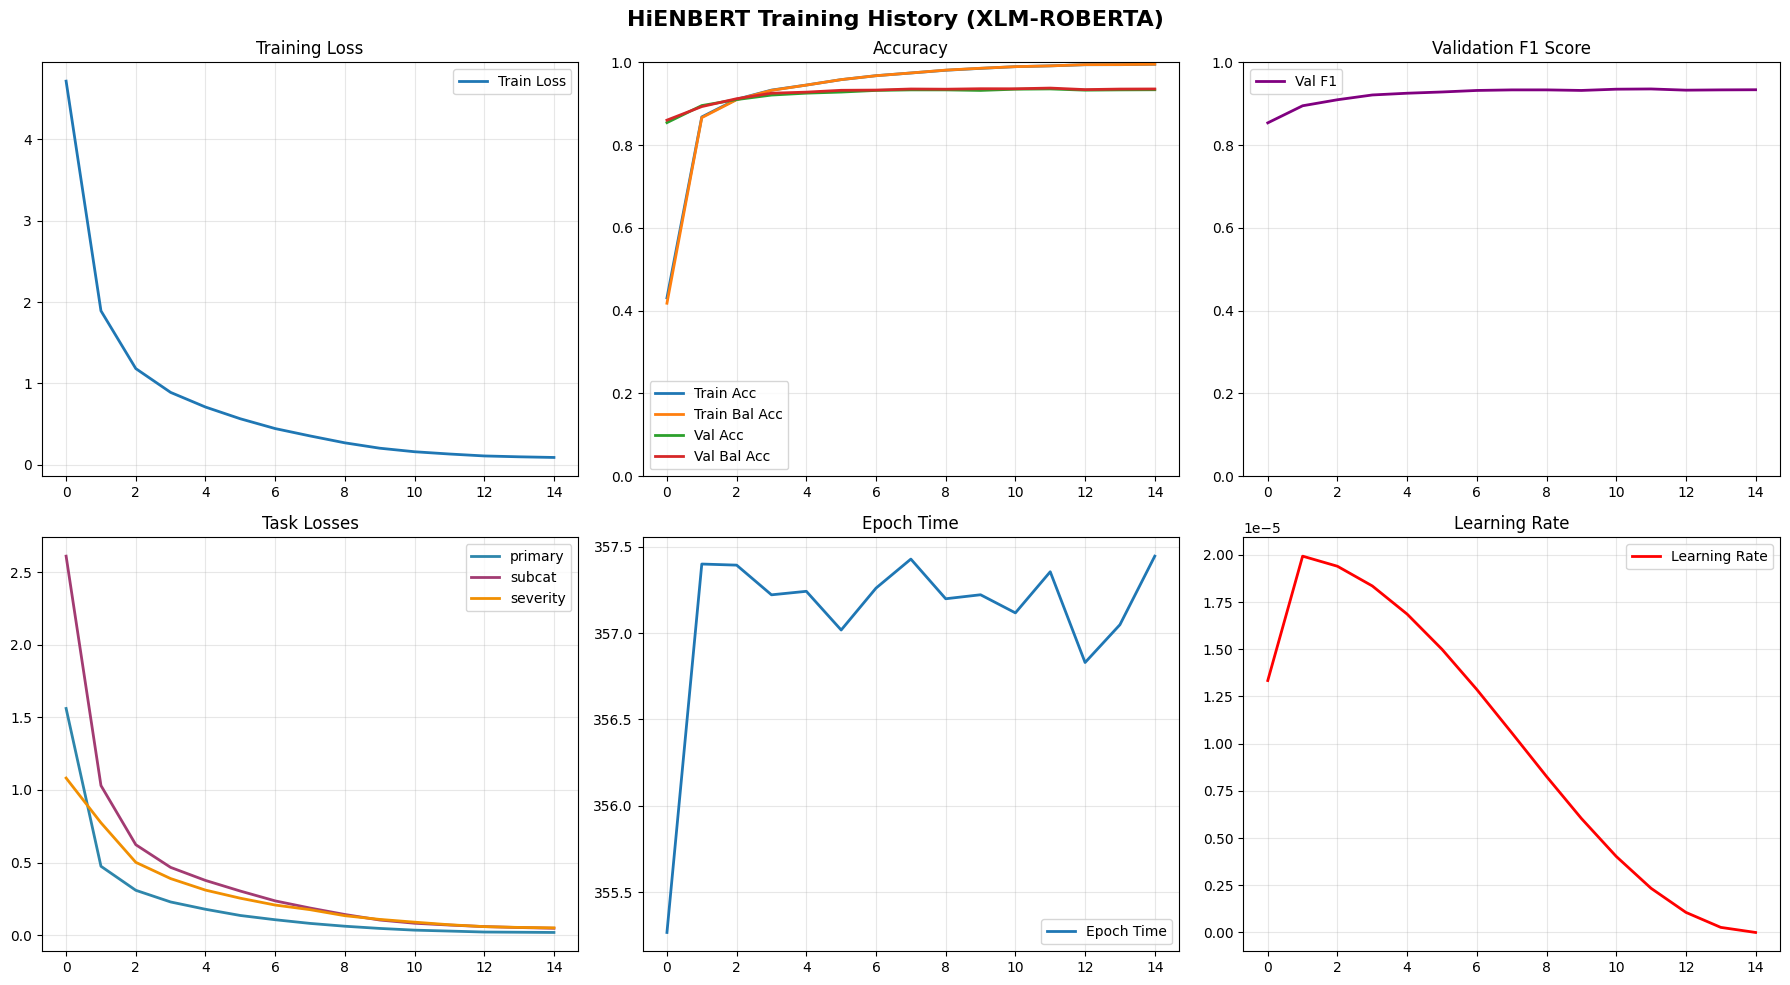

In [12]:
# ============================================================================
# CELL 12: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_optimized_history(train_history, val_history, save_path=None):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
    axes[0, 1].set_title('Accuracy')
    axes[0, 1].set_ylim(0, 1)
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    
    # F1 Score
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score')
    axes[0, 2].set_ylim(0, 1)
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    
    # Task losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task Losses')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
    axes[1, 1].set_title('Epoch Time')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()})', fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_optimized_history(train_history, val_history, save_path=f"{Config.VISUALIZATION_DIR}/training_history.png")

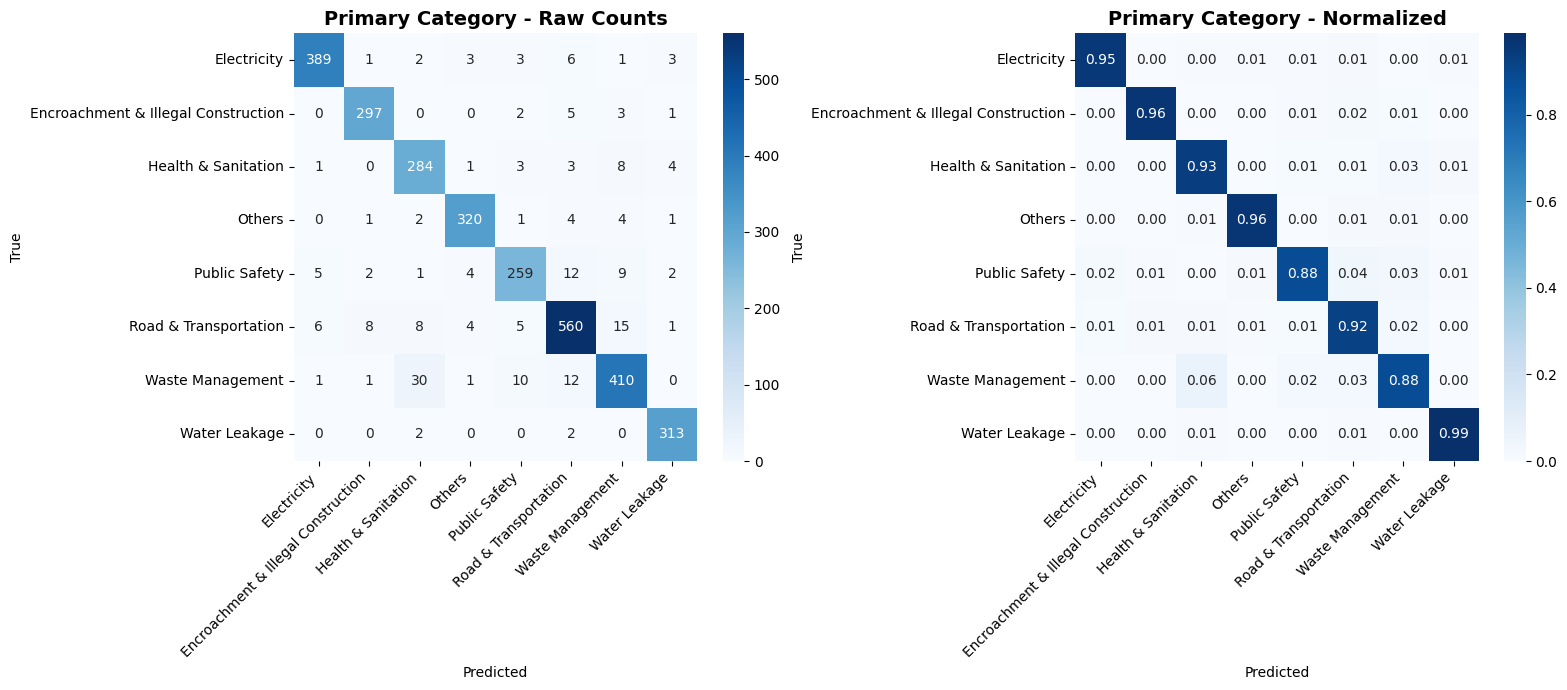

✅ Confusion matrix saved


In [13]:
# ============================================================================
# CELL 13: CONFUSION MATRIX
# ============================================================================

def plot_confusion_matrix_optimized(y_true, y_pred, class_names, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrix
class_names = preprocessor.le_primary.classes_
plot_confusion_matrix_optimized(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

print(f"✅ Confusion matrix saved")

✓ Using Devanagari font: Nirmala UI

RUNNING MULTILINGUAL SHAP ANALYSIS

VERIFYING DATASET COLUMNS
Available columns:
  - Sy_No
  - complaint_title
  - text_en
  - Hindi
  - Hinglish
  - category_primary
  - category_secondary
  - severity
  - Model_Name
  - text
  - primary_label
  - subcat_label
  - severity_label
  - sentiment_score

✓ Found 'text_en': 3036 non-empty samples

✓ Found 'Hindi': 3036 non-empty samples

✓ Found 'Hinglish': 3036 non-empty samples
✓ Using Devanagari font: Nirmala UI

MULTILINGUAL SHAP EXPLAINABLE AI (XAI) ANALYSIS

Extracting language-specific data...
✓ Found English texts: 3036
✓ Found Hindi texts: 3036
✓ Found Hinglish texts: 3036

Language data distribution:
  english: 3036 samples
    Sample: The Tender Sure footpath of St. Marks Road has been dug up by Sobha Builders. Please ensure that the...
  hindi: 3036 samples
    Sample: सेंट मार्क्स रोड के टेंडर श्योर फुटपाथ को शोभा बिल्डर्स ने खोद दिया है। कृपया सुनिश्चित करें कि अपूर...
  hinglish: 3036 samp

PartitionExplainer explainer: 31it [00:56,  1.88s/it]                        


✓ english SHAP values computed

Calculating english token importance...

Top english SHAP Features:
    token  mean_abs_shap  frequency
    black       0.139063          1
 electric       0.136783          3
      Gar       0.135634          1
   toilet       0.114224          1
      dra       0.110553          1
     pipe       0.107669          3
Municipal       0.104126          1
     Fire       0.098212          1
    libra       0.096181          1
    flood       0.092451          1
      Mas       0.087942          1
    Spark       0.086566          1
    spray       0.081709          1
 cleaning       0.078648          1
     ball       0.077647          1
✓ Saved english plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\english\english_shap_importance.png

ANALYZING HINDI TEXTS
Analyzing 30 hindi samples
  Sample 1: यह स्ट्रीट लाइट किसी काम की नहीं है क्योंकि यह बहुत ऊंचाई पर लगी है इसलिए उचित रोशनी

PartitionExplainer explainer: 31it [00:53,  2.04s/it]                        


✓ hindi SHAP values computed

Calculating hindi token importance...

Top hindi SHAP Features:
  token  mean_abs_shap  frequency
 शौचालय       0.228226          1
  बिजली       0.172368          5
   बाढ़       0.094616          1
    ालय       0.093685          1
   कचरा       0.092643          4
   पानी       0.081652          6
 पुस्तक       0.080720          1
यातायात       0.071926          1
निगरानी       0.064113          1
     शन       0.060510          1
     जल       0.058222          4
   सड़क       0.057952         10
     एम       0.056604          1
   फेंक       0.055346          1
   गायब       0.054814          1
✓ Saved hindi plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\hindi\hindi_shap_importance.png

ANALYZING HINGLISH TEXTS
Analyzing 30 hinglish samples
  Sample 1: Yeh street light kisi kaam ki nahi hai kyunki yeh bahut unchai par lagi hai isliye uchit roshni nahi hai. Ise nayi LED lig

PartitionExplainer explainer: 31it [00:59,  2.38s/it]                        


✓ hinglish SHAP values computed

Calculating hinglish token importance...

Top hinglish SHAP Features:
    token  mean_abs_shap  frequency
    libra       0.136196          1
    spray       0.135334          1
     pipe       0.128059          2
    power       0.102095          1
      out       0.096452          1
    Owner       0.096143          1
    kabel       0.092138          1
municipal       0.084756          1
    group       0.082581          1
     road       0.081949          4
    black       0.078961          1
   office       0.077118          2
     park       0.074911          2
structura       0.073823          1
 cleaning       0.072189          1
✓ Saved hinglish plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\hinglish\hinglish_shap_importance.png

CREATING COMBINED MULTILINGUAL FIGURE
✓ Saved combined multilingual figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_C

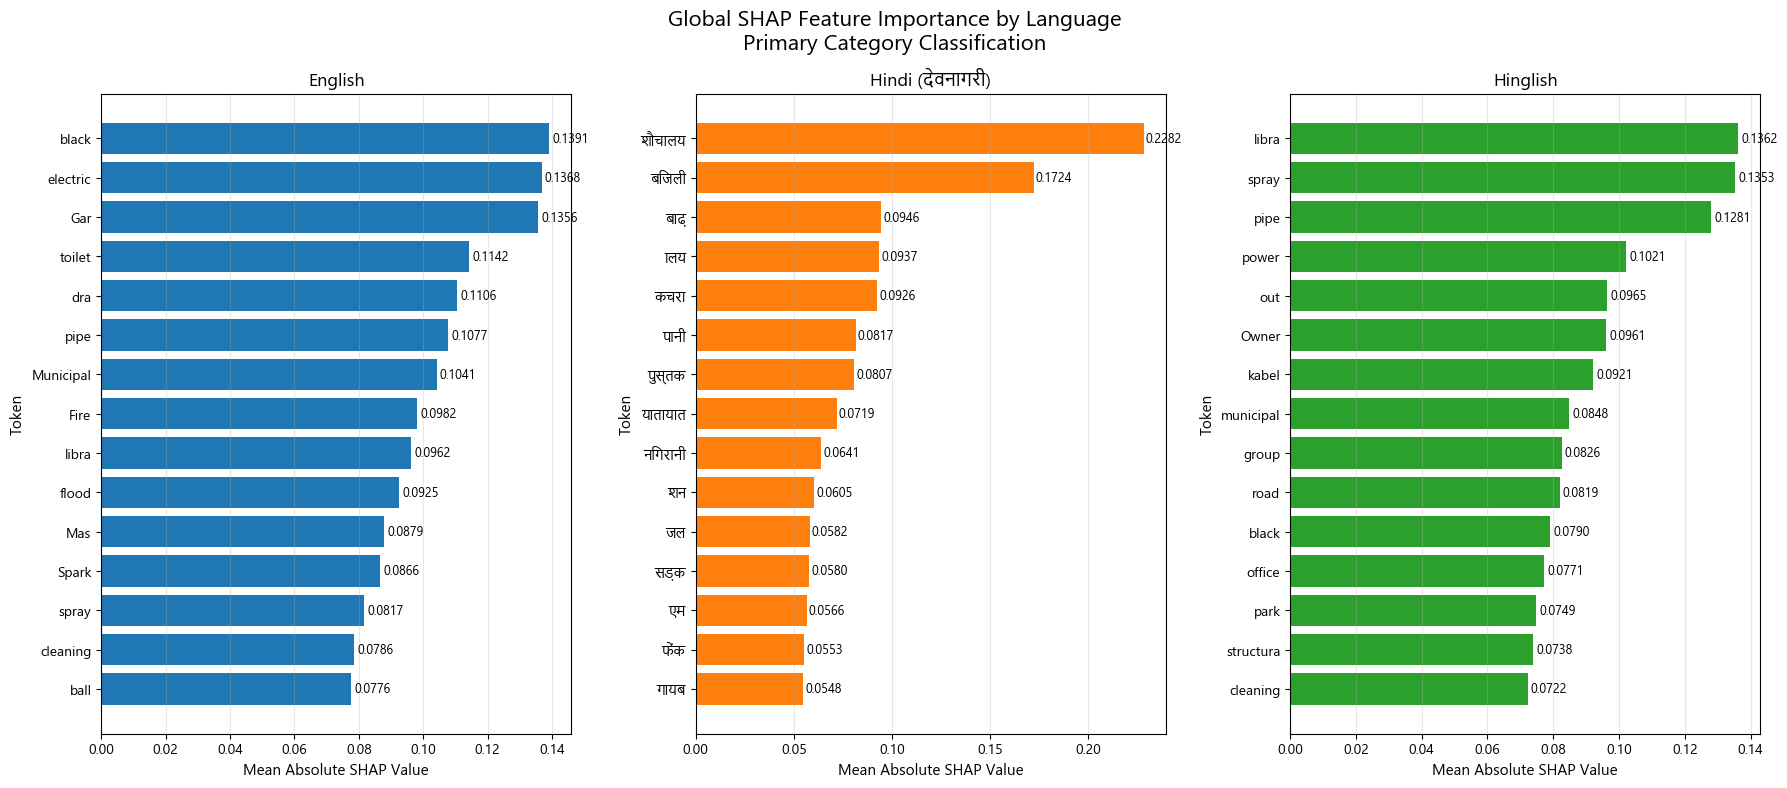

✓ Saved metadata: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\shap_metadata.json

MULTILINGUAL SHAP ANALYSIS COMPLETE
Languages analyzed: 3
  - english: 30 samples, 599 unique tokens
  - hindi: 30 samples, 603 unique tokens
  - hinglish: 30 samples, 656 unique tokens

Output directory: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap
✓ IEEE Access figure saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\ieee_access_figure.pdf


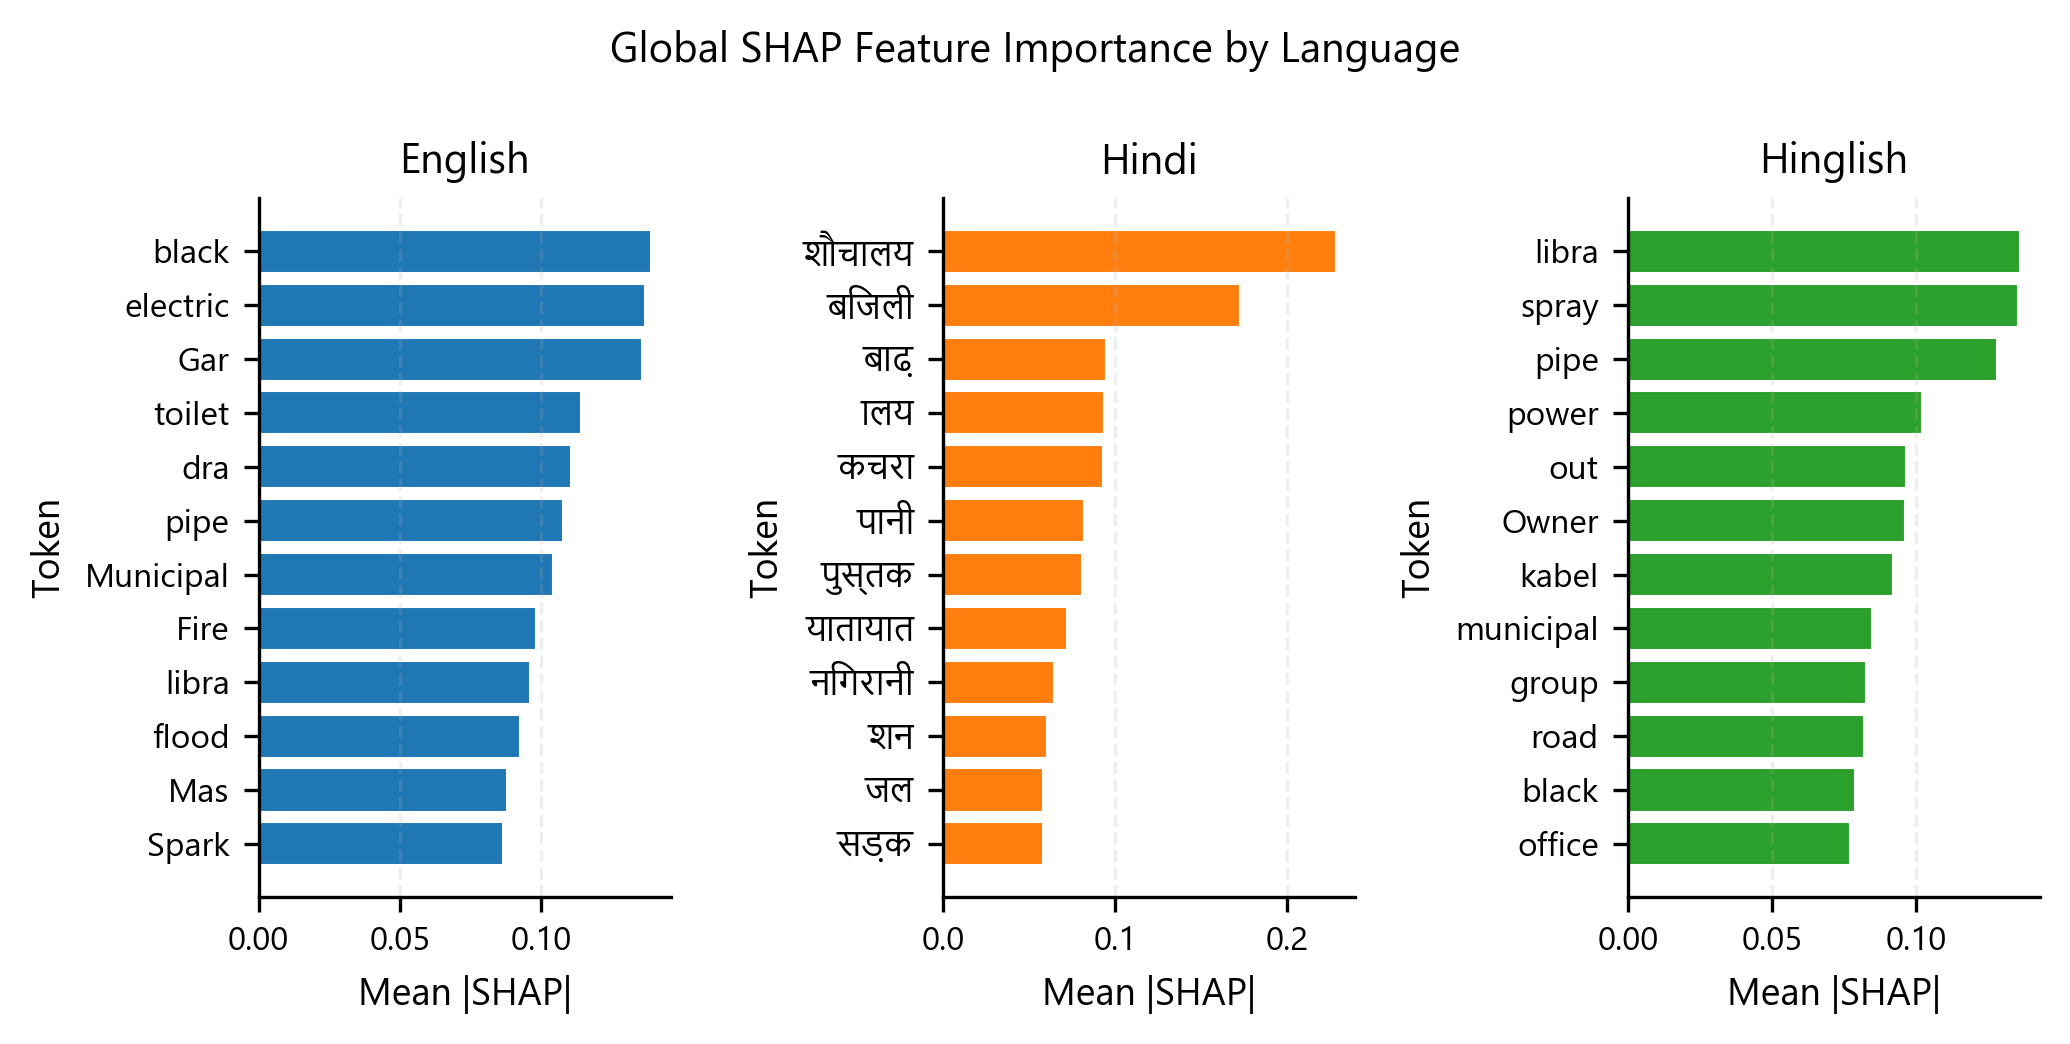


✓ SHAP ANALYSIS COMPLETED SUCCESSFULLY
Results saved in: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap


In [14]:
# ============================================================================
# CELL 14: SHAP XAI ANALYSIS (CORRECTED FOR YOUR DATASET STRUCTURE)
# ============================================================================

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
import torch
import os
import re
import pickle
import json
import shap
from matplotlib import rcParams
import unicodedata

# ============================================================================
# FONT CONFIGURATION FOR DEVANAGARI
# ============================================================================

def setup_devanagari_fonts():
    """
    Setup matplotlib to properly render Devanagari (Hindi) text.
    """
    devanagari_fonts = [
        'Noto Sans Devanagari',
        'Noto Sans Devanagari UI',
        'Nirmala UI',
        'Mangal',
        'Arial Unicode MS',
        'DejaVu Sans',
        'FreeSerif',
        'Liberation Serif'
    ]
    
    available_fonts = [f.name for f in fm.fontManager.ttflist]
    
    for font in devanagari_fonts:
        if font in available_fonts:
            rcParams['font.family'] = font
            plt.rcParams['font.family'] = font
            print(f"✓ Using Devanagari font: {font}")
            return font
    
    # Fallback
    for font in available_fonts:
        devanagari_keywords = ['devanagari', 'hindi', 'noto', 'nirmala', 'mangal', 'unicode']
        if any(keyword in font.lower() for keyword in devanagari_keywords):
            rcParams['font.family'] = font
            plt.rcParams['font.family'] = font
            print(f"✓ Using Devanagari font: {font}")
            return font
    
    print("⚠ No Devanagari font found. Text may show as boxes.")
    rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.family'] = 'sans-serif'
    return None

setup_devanagari_fonts()

# ============================================================================
# LANGUAGE-SPECIFIC DATA EXTRACTION
# ============================================================================

def extract_language_specific_data(test_df):
    """
    Extract language-specific texts from the dataset.
    Your dataset has separate columns: text_en, Hindi, Hinglish
    """
    language_data = {
        'english': [],
        'hindi': [],
        'hinglish': []
    }
    
    # Check which language columns exist
    if 'text_en' in test_df.columns:
        english_texts = test_df['text_en'].fillna('').astype(str).tolist()
        language_data['english'] = [t for t in english_texts if t.strip()]
        print(f"✓ Found English texts: {len(language_data['english'])}")
    
    if 'Hindi' in test_df.columns:
        hindi_texts = test_df['Hindi'].fillna('').astype(str).tolist()
        language_data['hindi'] = [t for t in hindi_texts if t.strip()]
        print(f"✓ Found Hindi texts: {len(language_data['hindi'])}")
    
    if 'Hinglish' in test_df.columns:
        hinglish_texts = test_df['Hinglish'].fillna('').astype(str).tolist()
        language_data['hinglish'] = [t for t in hinglish_texts if t.strip()]
        print(f"✓ Found Hinglish texts: {len(language_data['hinglish'])}")
    
    # If no language-specific columns found, try to use the combined 'text' column
    if all(len(v) == 0 for v in language_data.values()):
        print("⚠ No language-specific columns found. Using combined 'text' column.")
        if 'text' in test_df.columns:
            all_texts = test_df['text'].fillna('').astype(str).tolist()
            # Categorize by language detection
            for text in all_texts:
                if text.strip():
                    lang = detect_language(text)
                    language_data[lang].append(text)
    
    return language_data

def detect_language(text):
    """
    Detect if text is English, Hindi, or Hinglish.
    """
    devanagari_pattern = re.compile(r'[\u0900-\u097F]')
    devanagari_chars = re.findall(r'[\u0900-\u097F]', text)
    
    if devanagari_chars:
        total_chars = len(re.sub(r'[\s\d\W]', '', text))
        if total_chars > 0:
            devanagari_ratio = len(devanagari_chars) / total_chars
            if devanagari_ratio > 0.3:
                return 'hindi'
            else:
                return 'hinglish'
    return 'english'

# ============================================================================
# TOKEN CLEANING FOR DEVANAGARI
# ============================================================================

def clean_token_for_display(token):
    """
    Clean token for proper display, especially for Devanagari.
    """
    if not token:
        return None
    
    # Remove special tokens
    if token in ["[CLS]", "[SEP]", "[PAD]", "[UNK]"]:
        return None
    
    # Handle BPE tokens
    if token.startswith("##"):
        token = token[2:]
    
    # Remove any non-printable characters
    token = ''.join(char for char in token if unicodedata.category(char)[0] != 'C')
    
    # For Devanagari, ensure proper rendering
    if any('\u0900' <= char <= '\u097F' for char in token):
        return token.strip()
    
    # For English/Hinglish, keep as-is
    return token.strip()

# ============================================================================
# ENHANCED SHAP ANALYSIS FUNCTION
# ============================================================================

def run_shap_analysis_multilingual(
    model,
    tokenizer,
    test_df,
    device,
    class_names,
    save_dir
):
    """
    SHAP Explainable AI analysis for multilingual civic complaint
    classification using language-specific columns from the dataset.
    """

    print("\n" + "=" * 80)
    print("MULTILINGUAL SHAP EXPLAINABLE AI (XAI) ANALYSIS")
    print("=" * 80)

    try:
        import shap
        import re
        import pickle
        import json

        # --------------------------------------------------------------------
        # CREATE OUTPUT DIRECTORIES
        # --------------------------------------------------------------------
        
        multilingual_dir = os.path.join(save_dir, "multilingual_shap")
        os.makedirs(multilingual_dir, exist_ok=True)
        
        # --------------------------------------------------------------------
        # SHAP CONFIGURATION
        # --------------------------------------------------------------------
        
        SAMPLES_PER_LANGUAGE = 30
        MAX_LENGTH = 128
        TOP_TOKENS = 15

        # --------------------------------------------------------------------
        # EXTRACT LANGUAGE-SPECIFIC TEXTS
        # --------------------------------------------------------------------
        
        print("\nExtracting language-specific data...")
        language_data = extract_language_specific_data(test_df)
        
        print("\nLanguage data distribution:")
        for lang, texts in language_data.items():
            print(f"  {lang}: {len(texts)} samples")
            if len(texts) > 0:
                print(f"    Sample: {texts[0][:100]}...")

        # --------------------------------------------------------------------
        # SHAP PREDICTION FUNCTION
        # --------------------------------------------------------------------

        def shap_predict(texts):
            """
            SHAP-compatible prediction function.
            """
            model.eval()

            if isinstance(texts, str):
                texts = [texts]

            texts = [str(text) for text in texts]
            predictions = []

            BATCH_SIZE = 32

            for start in range(0, len(texts), BATCH_SIZE):
                batch_texts = texts[start:start + BATCH_SIZE]

                encoded = tokenizer(
                    batch_texts,
                    truncation=True,
                    padding=True,
                    max_length=MAX_LENGTH,
                    return_tensors="pt"
                )

                input_ids = encoded["input_ids"].to(device)
                attention_mask = encoded["attention_mask"].to(device)

                sentiment = torch.zeros(input_ids.shape[0], device=device)

                with torch.no_grad():
                    primary_logits, _, _ = model(
                        input_ids,
                        attention_mask,
                        sentiment
                    )
                    probabilities = torch.softmax(primary_logits, dim=1)

                predictions.append(probabilities.detach().cpu().numpy())

            return np.vstack(predictions)

        # --------------------------------------------------------------------
        # CREATE SHAP EXPLAINER
        # --------------------------------------------------------------------
        
        print("\nCreating SHAP Text Explainer...")
        masker = shap.maskers.Text(tokenizer)
        explainer = shap.Explainer(shap_predict, masker)
        print("✓ SHAP Text Explainer created")

        # ====================================================================
        # ANALYZE EACH LANGUAGE SEPARATELY
        # ====================================================================
        
        language_results = {}
        language_importance_dfs = {}
        
        for language, texts in language_data.items():
            if len(texts) < 2:
                print(f"\n⚠ Skipping {language}: insufficient samples ({len(texts)})")
                continue
                
            print("\n" + "=" * 80)
            print(f"ANALYZING {language.upper()} TEXTS")
            print("=" * 80)
            
            # Select samples
            n_samples = min(SAMPLES_PER_LANGUAGE, len(texts))
            rng = np.random.RandomState(42)
            indices = rng.choice(len(texts), size=n_samples, replace=False)
            selected_texts = [texts[i] for i in indices]
            
            print(f"Analyzing {len(selected_texts)} {language} samples")
            
            # Print sample texts for verification
            for i, text in enumerate(selected_texts[:3]):
                print(f"  Sample {i+1}: {text[:150]}...")
            
            # Compute SHAP values
            print(f"\nComputing {language} SHAP values...")
            shap_values = explainer(selected_texts, max_evals=500)
            print(f"✓ {language} SHAP values computed")
            
            # Save raw SHAP values
            lang_dir = os.path.join(multilingual_dir, language)
            os.makedirs(lang_dir, exist_ok=True)
            
            shap_pkl = os.path.join(lang_dir, f"shap_values.pkl")
            with open(shap_pkl, "wb") as f:
                pickle.dump(shap_values, f)
            
            # Calculate global token importance
            print(f"\nCalculating {language} token importance...")
            token_scores = {}
            
            for sample_idx in range(len(shap_values)):
                explanation = shap_values[sample_idx]
                tokens = [str(token).strip() for token in explanation.data]
                values = explanation.values
                
                # Handle multiclass output
                if values.ndim == 2:
                    token_contributions = np.mean(np.abs(values), axis=1)
                else:
                    token_contributions = np.abs(values)
                
                # Process each token
                for token, score in zip(tokens, token_contributions):
                    cleaned_token = clean_token_for_display(token)
                    
                    if not cleaned_token:
                        continue
                    
                    # For Hindi, specifically look for Devanagari tokens
                    if language == 'hindi':
                        has_devanagari = any('\u0900' <= char <= '\u097F' for char in cleaned_token)
                        # Keep tokens that have Devanagari or are meaningful words
                        if has_devanagari or len(cleaned_token) > 2:
                            if cleaned_token not in token_scores:
                                token_scores[cleaned_token] = []
                            token_scores[cleaned_token].append(float(score))
                    else:
                        # For English and Hinglish, keep all meaningful tokens
                        if len(cleaned_token) > 1:
                            if cleaned_token not in token_scores:
                                token_scores[cleaned_token] = []
                            token_scores[cleaned_token].append(float(score))
            
            # Create importance dataframe
            importance_rows = []
            for token, scores in token_scores.items():
                importance_rows.append({
                    "token": token,
                    "mean_abs_shap": float(np.mean(scores)),
                    "frequency": len(scores)
                })
            
            importance_df = pd.DataFrame(importance_rows)
            if not importance_df.empty:
                importance_df = importance_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
            else:
                print(f"⚠ No tokens found for {language}")
                continue
            
            # Save importance CSV
            importance_csv = os.path.join(lang_dir, "token_importance.csv")
            importance_df.to_csv(importance_csv, index=False, encoding="utf-8")
            
            # Store results
            language_results[language] = {
                'shap_values': shap_values,
                'texts': selected_texts,
                'importance_df': importance_df
            }
            language_importance_dfs[language] = importance_df
            
            # Print top tokens with language-specific display
            print(f"\nTop {language} SHAP Features:")
            if not importance_df.empty:
                top_df = importance_df.head(TOP_TOKENS)
                print(top_df.to_string(index=False))
            
            # Create language-specific visualization
            plt.figure(figsize=(12, 8))
            
            top_df = importance_df.head(TOP_TOKENS).sort_values('mean_abs_shap')
            tokens = top_df['token'].tolist()
            values = top_df['mean_abs_shap'].tolist()
            
            color = '#1f77b4' if language == 'english' else '#ff7f0e' if language == 'hindi' else '#2ca02c'
            bars = plt.barh(tokens, values, color=color)
            
            plt.xlabel('Mean Absolute SHAP Value', fontsize=12)
            plt.ylabel('Token', fontsize=12)
            plt.title(f'SHAP Feature Importance - {language.upper()}', fontsize=14, fontweight='bold')
            plt.grid(True, axis='x', alpha=0.3)
            
            # Add value labels
            for bar, value in zip(bars, values):
                plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, 
                        f'{value:.4f}', va='center', fontsize=10)
            
            plt.tight_layout()
            lang_plot = os.path.join(lang_dir, f"{language}_shap_importance.png")
            plt.savefig(lang_plot, dpi=300, bbox_inches='tight', facecolor='white')
            plt.close()
            
            print(f"✓ Saved {language} plot: {lang_plot}")
        
        # ====================================================================
        # CREATE COMBINED MULTILINGUAL FIGURE
        # ====================================================================
        
        if len(language_results) >= 2:
            print("\n" + "=" * 80)
            print("CREATING COMBINED MULTILINGUAL FIGURE")
            print("=" * 80)
            
            # Create combined figure with 3 subplots
            fig, axes = plt.subplots(1, 3, figsize=(18, 8))
            fig.suptitle('Global SHAP Feature Importance by Language\nPrimary Category Classification', 
                        fontsize=16, fontweight='bold')
            
            # Color mapping for languages
            colors = {
                'english': '#1f77b4',
                'hindi': '#ff7f0e',
                'hinglish': '#2ca02c'
            }
            
            language_names = {
                'english': 'English',
                'hindi': 'Hindi (देवनागरी)',
                'hinglish': 'Hinglish'
            }
            
            for idx, (language, importance_df) in enumerate(language_importance_dfs.items()):
                if idx >= 3:
                    break
                    
                ax = axes[idx]
                
                # Get top tokens
                top_df = importance_df.head(TOP_TOKENS).sort_values('mean_abs_shap')
                tokens = top_df['token'].tolist()
                values = top_df['mean_abs_shap'].tolist()
                
                # Create bar chart
                bars = ax.barh(tokens, values, color=colors.get(language, '#333333'))
                
                # Customize subplot
                ax.set_xlabel('Mean Absolute SHAP Value', fontsize=11)
                ax.set_ylabel('Token', fontsize=11)
                ax.set_title(language_names.get(language, language), fontsize=13, fontweight='bold')
                ax.grid(True, axis='x', alpha=0.3)
                
                # Add value labels
                for bar, value in zip(bars, values):
                    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, 
                           f'{value:.4f}', va='center', fontsize=9)
            
            # Hide any unused subplots
            for idx in range(len(language_results), 3):
                axes[idx].set_visible(False)
            
            plt.tight_layout()
            
            # Save combined figure
            combined_plot = os.path.join(multilingual_dir, "multilingual_shap_comparison.png")
            plt.savefig(combined_plot, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"✓ Saved combined multilingual figure: {combined_plot}")
            
            # Also save as PDF for IEEE Access
            combined_pdf = os.path.join(multilingual_dir, "multilingual_shap_comparison.pdf")
            plt.savefig(combined_pdf, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"✓ Saved combined multilingual PDF: {combined_pdf}")
            
            plt.show()
            plt.close()
        
        # ====================================================================
        # SAVE METADATA
        # ====================================================================
        
        metadata = {
            "model": Config.BASE_MODEL,
            "analysis": "Multilingual SHAP Text Explainability",
            "task": "Primary Category Classification",
            "languages_analyzed": list(language_results.keys()),
            "samples_per_language": SAMPLES_PER_LANGUAGE,
            "number_of_classes": len(class_names),
            "classes": [str(x) for x in class_names],
            "max_length": MAX_LENGTH,
            "font_used": rcParams['font.family'],
            "interpretation": {
                "positive_shap": "Token increases the model output for the explained class.",
                "negative_shap": "Token decreases the model output for the explained class.",
                "global_importance": "Mean absolute SHAP value across analyzed test samples."
            }
        }
        
        metadata_path = os.path.join(multilingual_dir, "shap_metadata.json")
        with open(metadata_path, "w", encoding="utf-8") as f:
            json.dump(metadata, f, indent=4, ensure_ascii=False)
        
        print(f"✓ Saved metadata: {metadata_path}")
        
        # ====================================================================
        # FINAL SUMMARY
        # ====================================================================
        
        print("\n" + "=" * 80)
        print("MULTILINGUAL SHAP ANALYSIS COMPLETE")
        print("=" * 80)
        print(f"Languages analyzed: {len(language_results)}")
        for language, results in language_results.items():
            print(f"  - {language}: {len(results['texts'])} samples, {len(results['importance_df'])} unique tokens")
        print(f"\nOutput directory: {multilingual_dir}")
        
        return {
            "language_results": language_results,
            "combined_figure": combined_plot if 'combined_plot' in locals() else None,
            "metadata": metadata
        }

    except ImportError as e:
        print("\nSHAP library is not installed.")
        print("Install using: pip install shap")
        return None
    except Exception as e:
        print("\n" + "=" * 80)
        print("SHAP ANALYSIS FAILED")
        print("=" * 80)
        print(f"Error: {e}")
        import traceback
        traceback.print_exc()
        return None


# ============================================================================
# CREATE IEEE ACCESS QUALITY FIGURE
# ============================================================================

def create_ieee_figure(shap_results, save_path=None):
    """
    Create a publication-quality figure for IEEE Access.
    """
    if not shap_results or 'language_results' not in shap_results:
        print("No SHAP results available for figure creation")
        return
    
    language_results = shap_results['language_results']
    
    if len(language_results) < 2:
        print("Insufficient language results for combined figure")
        return
    
    # Create figure with IEEE Access specifications
    fig_width = 7.0
    fig_height = 3.5
    
    fig, axes = plt.subplots(1, 3, figsize=(fig_width, fig_height), dpi=300)
    fig.suptitle('Global SHAP Feature Importance by Language', 
                fontsize=10, fontweight='bold')
    
    colors = {
        'english': '#1f77b4',
        'hindi': '#ff7f0e',
        'hinglish': '#2ca02c'
    }
    
    language_names = {
        'english': 'English',
        'hindi': 'Hindi',
        'hinglish': 'Hinglish'
    }
    
    TOP_TOKENS_FIGURE = 12
    
    for idx, (language, results) in enumerate(language_results.items()):
        if idx >= 3:
            break
        
        importance_df = results['importance_df']
        if importance_df is None or importance_df.empty:
            print(f"⚠ No importance data for {language}")
            continue
            
        ax = axes[idx]
        
        top_df = importance_df.head(TOP_TOKENS_FIGURE).sort_values('mean_abs_shap')
        tokens = top_df['token'].tolist()
        values = top_df['mean_abs_shap'].tolist()
        
        # Create bars with professional styling
        bars = ax.barh(tokens, values, color=colors.get(language, '#333333'), 
                      edgecolor='white', linewidth=0.5)
        
        ax.set_xlabel('Mean |SHAP|', fontsize=9)
        ax.set_ylabel('Token', fontsize=9)
        ax.set_title(language_names.get(language, language), fontsize=10, fontweight='bold')
        ax.grid(True, axis='x', alpha=0.2, linestyle='--')
        ax.tick_params(labelsize=8)
        
        # Remove top and right spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    # Hide any unused subplots
    for idx in range(len(language_results), 3):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✓ IEEE Access figure saved: {save_path}")
    
    plt.show()
    plt.close()


# ============================================================================
# VERIFY DATASET COLUMNS
# ============================================================================

def verify_dataset_columns(test_df):
    """
    Verify the columns available in the dataset.
    """
    print("\n" + "=" * 80)
    print("VERIFYING DATASET COLUMNS")
    print("=" * 80)
    
    print("Available columns:")
    for col in test_df.columns:
        print(f"  - {col}")
    
    # Check for language-specific columns
    lang_cols = ['text_en', 'Hindi', 'Hinglish']
    found_cols = []
    for col in lang_cols:
        if col in test_df.columns:
            found_cols.append(col)
            non_empty = (test_df[col].fillna('').astype(str).str.strip() != '').sum()
            print(f"\n✓ Found '{col}': {non_empty} non-empty samples")
        else:
            print(f"\n✗ '{col}' not found")
    
    return found_cols


# ============================================================================
# RUN MULTILINGUAL SHAP ANALYSIS
# ============================================================================

print("\n" + "=" * 80)
print("RUNNING MULTILINGUAL SHAP ANALYSIS")
print("=" * 80)

# First verify dataset columns
found_columns = verify_dataset_columns(test_df)

# Ensure fonts are properly configured
setup_devanagari_fonts()

# Run the analysis
shap_results = run_shap_analysis_multilingual(
    model=model,
    tokenizer=tokenizer,
    test_df=test_df,
    device=Config.DEVICE,
    class_names=class_names,
    save_dir=Config.SHAP_DIR
)

# Create IEEE Access quality figure
if shap_results:
    ieee_fig_dir = os.path.join(Config.SHAP_DIR, "multilingual_shap")
    os.makedirs(ieee_fig_dir, exist_ok=True)
    ieee_fig_path = os.path.join(ieee_fig_dir, "ieee_access_figure.pdf")
    create_ieee_figure(shap_results, ieee_fig_path)
    
    print("\n" + "=" * 80)
    print("✓ SHAP ANALYSIS COMPLETED SUCCESSFULLY")
    print("=" * 80)
    print(f"Results saved in: {ieee_fig_dir}")

In [11]:
# ============================================================================
# DEFINE CLASS NAMES BEFORE SHAP ANALYSIS
# ============================================================================

# Get class names from your label encoder
if 'category_primary' in test_df.columns:
    # If you have the label encoder from preprocessing
    if hasattr(preprocessor, 'le_primary'):
        class_names = preprocessor.le_primary.classes_.tolist()
    else:
        # Or get unique values from the column
        class_names = test_df['category_primary'].unique().tolist()
        class_names = [str(c) for c in class_names if pd.notna(c)]
else:
    # Fallback: use integer class names
    class_names = [str(i) for i in range(test_df['primary_label'].nunique())]

print(f"Class names: {class_names}")
print(f"Number of classes: {len(class_names)}")

Class names: ['Electricity', 'Encroachment & Illegal Construction', 'Health & Sanitation', 'Others', 'Public Safety', 'Road & Transportation', 'Waste Management', 'Water Leakage']
Number of classes: 8


✓ Using Devanagari font: Nirmala UI

RUNNING MULTILINGUAL SHAP ANALYSIS (GLOBAL + LOCAL)
✓ Found 8 classes from test data
Classes: ['Encroachment & Illegal Construction', 'Electricity', 'Waste Management', 'Public Safety', 'Others', 'Road & Transportation', 'Water Leakage', 'Health & Sanitation']

VERIFYING DATASET COLUMNS
Available columns:
  - Sy_No
  - complaint_title
  - text_en
  - Hindi
  - Hinglish
  - category_primary
  - category_secondary
  - severity
  - Model_Name
  - text
  - primary_label
  - subcat_label
  - severity_label
  - sentiment_score

✓ Found 'text_en': 3036 non-empty samples

✓ Found 'Hindi': 3036 non-empty samples

✓ Found 'Hinglish': 3036 non-empty samples
✓ Using Devanagari font: Nirmala UI

MULTILINGUAL SHAP EXPLAINABLE AI (XAI) ANALYSIS
GLOBAL + LOCAL EXPLANATIONS

Extracting language-specific data...
✓ Found English texts: 3036
✓ Found Hindi texts: 3036
✓ Found Hinglish texts: 3036

Language data distribution:
  english: 3036 samples
    Sample: The Tende

PartitionExplainer explainer: 31it [00:53,  2.13s/it]                        


✓ english global SHAP values computed

Calculating english global token importance...

Top english Global SHAP Features:
   token  mean_abs_shap  frequency
  toilet       0.220570          1
     dra       0.173676          1
    pipe       0.121277          3
    Fire       0.118077          1
     Was       0.115797          1
   power       0.110937          2
electric       0.101246          3
   libra       0.099745          1
     Gar       0.084701          1
 traffic       0.082567          2
     Dra       0.080318          1
   water       0.077353          9
cleaning       0.074513          1
   spray       0.073641          1
   black       0.070573          1
✓ Saved english global SHAP plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\global\english\english_global_shap.png

LOCAL SHAP - ENGLISH TEXTS
Analyzing 5 english samples for local SHAP

Computing english local SHAP values...
✓ english local

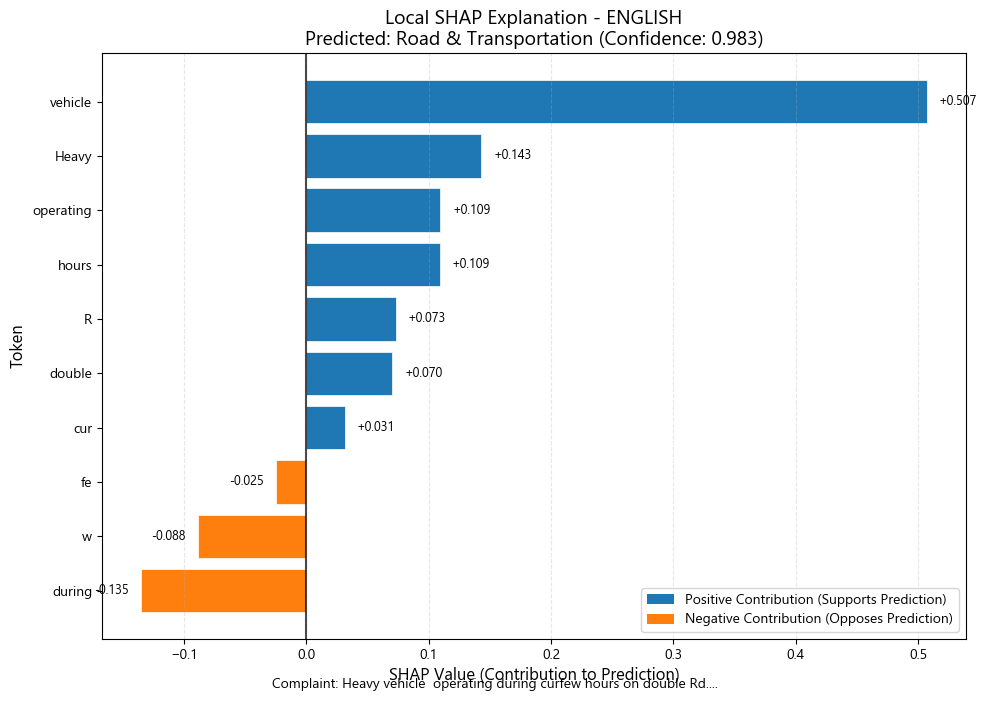

  Sample 1:
    Predicted: Road & Transportation (conf: 0.9826)
    Top positive: vehicle(+0.507), Heavy(+0.143), operating(+0.109)
    Top negative: during(-0.135), w(-0.088), fe(-0.025)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\english\local_explanation_sample_2.png


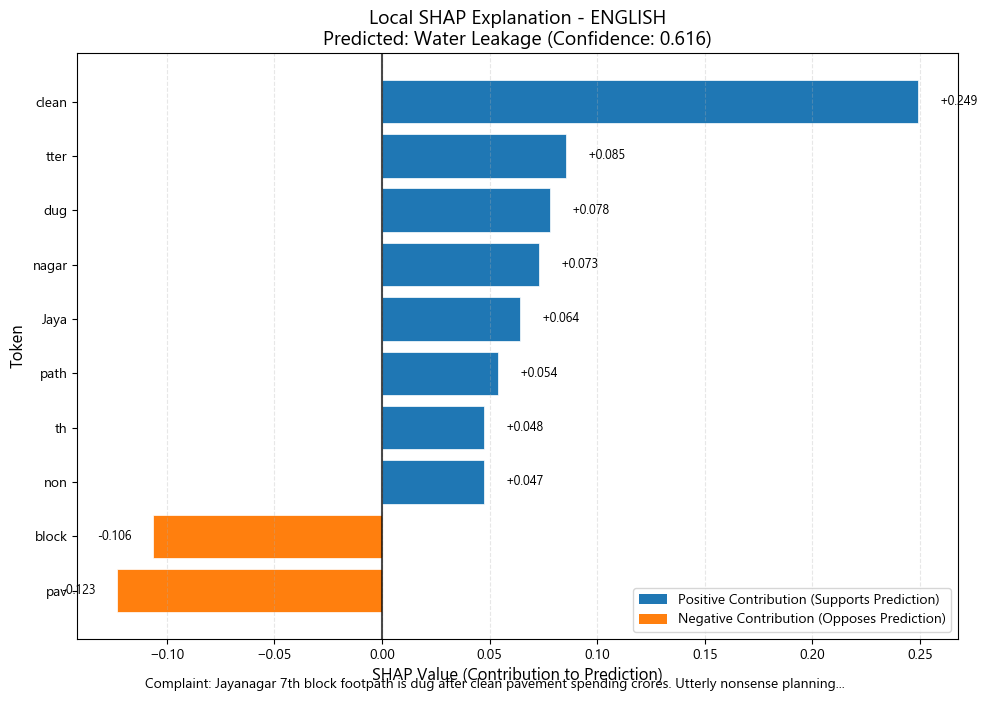

  Sample 2:
    Predicted: Water Leakage (conf: 0.6156)
    Top positive: clean(+0.249), tter(+0.085), dug(+0.078)
    Top negative: pav(-0.123), block(-0.106), ly(-0.042)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\english\local_explanation_sample_3.png


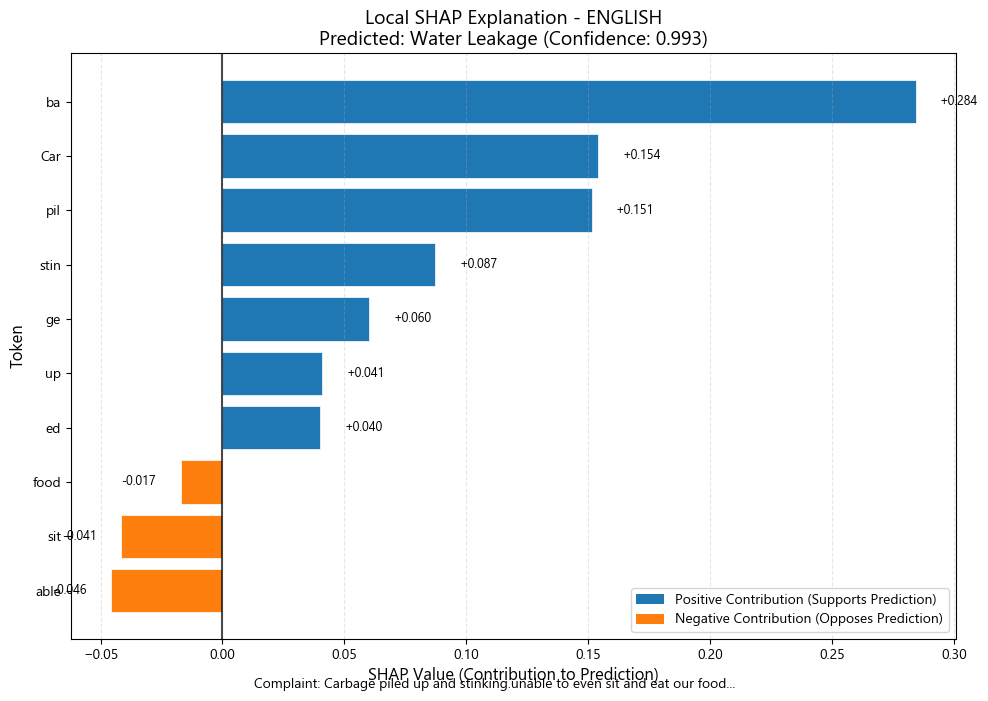

  Sample 3:
    Predicted: Water Leakage (conf: 0.9928)
    Top positive: ba(+0.284), Car(+0.154), pil(+0.151)
    Top negative: able(-0.046), sit(-0.041), food(-0.017)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\english\local_explanation_sample_4.png


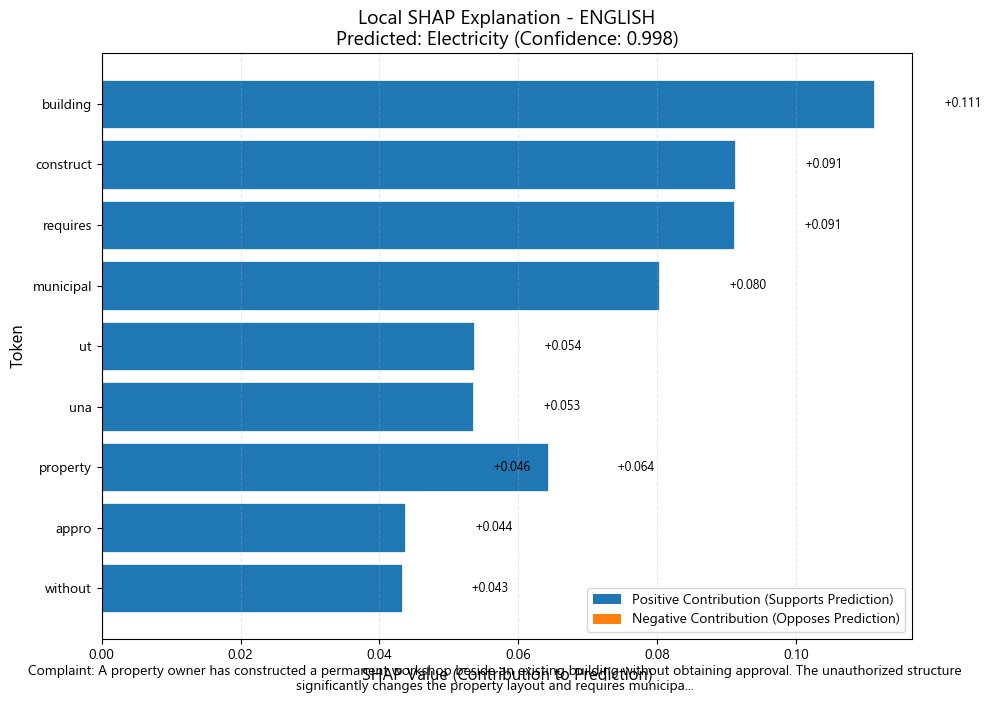

  Sample 4:
    Predicted: Electricity (conf: 0.9979)
    Top positive: building(+0.111), construct(+0.091), requires(+0.091)
    Top negative: workshop(-0.037), changes(-0.037), .(-0.013)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\english\local_explanation_sample_5.png


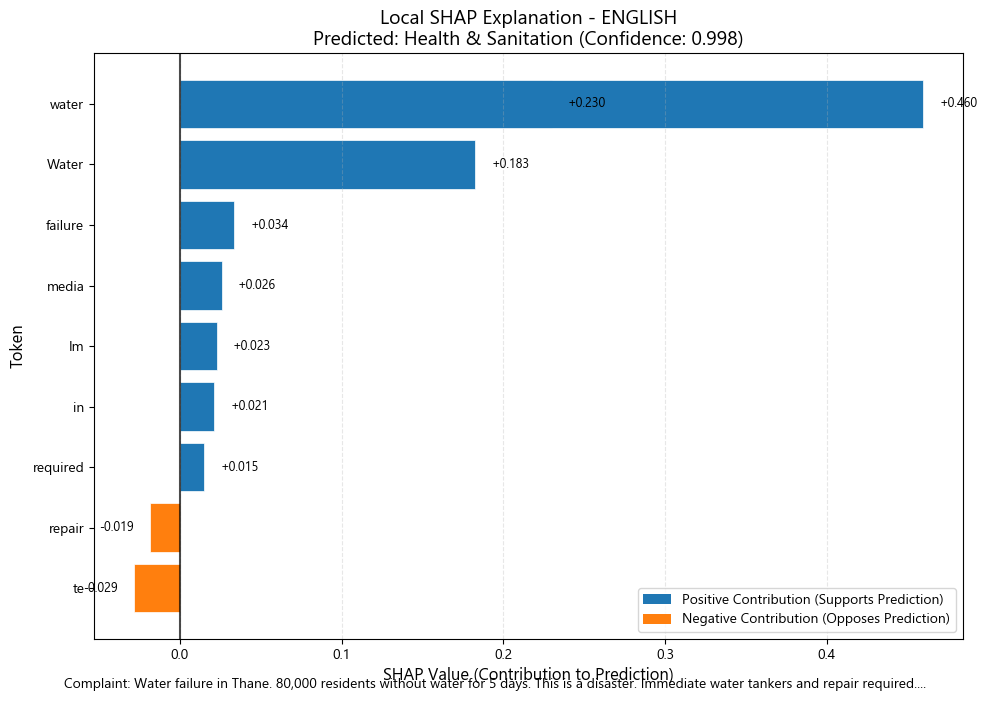

  Sample 5:
    Predicted: Health & Sanitation (conf: 0.9979)
    Top positive: water(+0.460), water(+0.230), Water(+0.183)
    Top negative: te(-0.029), repair(-0.019), s(-0.013)
✓ Saved local summary: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\english\local_explanation_summary.csv

GLOBAL SHAP - HINDI TEXTS
Analyzing 30 hindi samples for global SHAP

Computing hindi global SHAP values...


PartitionExplainer explainer: 31it [00:55,  2.21s/it]                        


✓ hindi global SHAP values computed

Calculating hindi global token importance...

Top hindi Global SHAP Features:
   token  mean_abs_shap  frequency
  शौचालय       0.205695          1
   बिजली       0.150997          5
    वाहन       0.121977          1
    कचरा       0.116849          4
    बाढ़       0.089977          1
 यातायात       0.088097          1
    पानी       0.087304          6
परियोजना       0.072882          1
    सड़क       0.068540         10
अतिक्रमण       0.054127          1
 आपूर्ति       0.051837          5
  पुस्तक       0.051433          1
   निकास       0.050192          1
दुर्घटना       0.048300          1
      जल       0.047788          4
✓ Saved hindi global SHAP plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\global\hindi\hindi_global_shap.png

LOCAL SHAP - HINDI TEXTS
Analyzing 5 hindi samples for local SHAP

Computing hindi local SHAP values...
✓ hindi local SHAP values compute

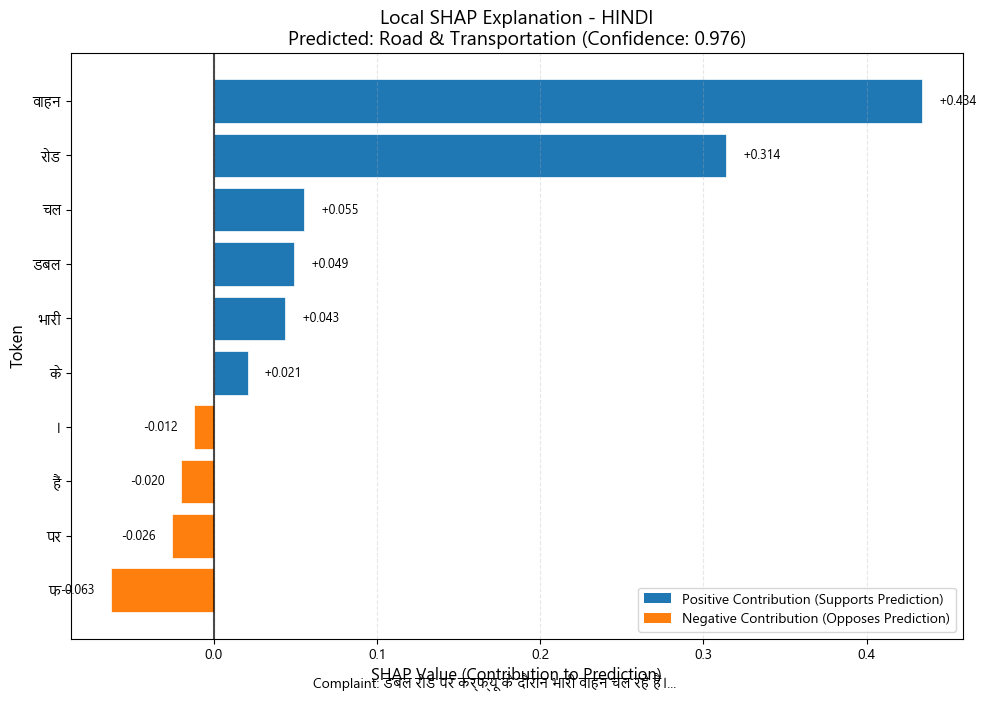

  Sample 1:
    Predicted: Road & Transportation (conf: 0.9761)
    Top positive: वाहन(+0.434), रोड(+0.314), चल(+0.055)
    Top negative: फ(-0.063), पर(-0.026), हैं(-0.020)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hindi\local_explanation_sample_2.png


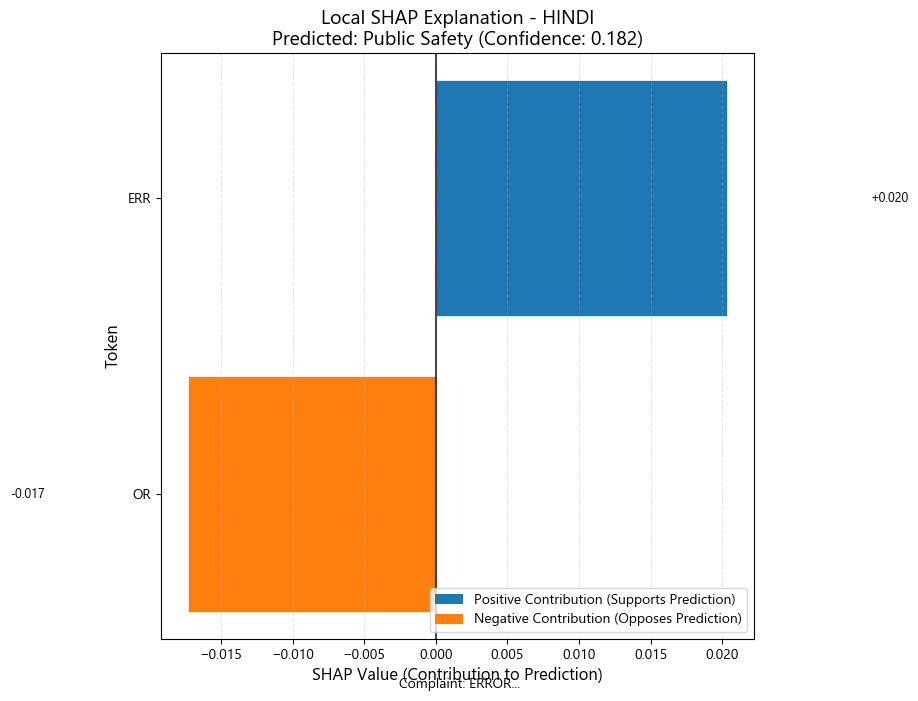

  Sample 2:
    Predicted: Public Safety (conf: 0.1817)
    Top positive: ERR(+0.020)
    Top negative: OR(-0.017)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hindi\local_explanation_sample_3.png


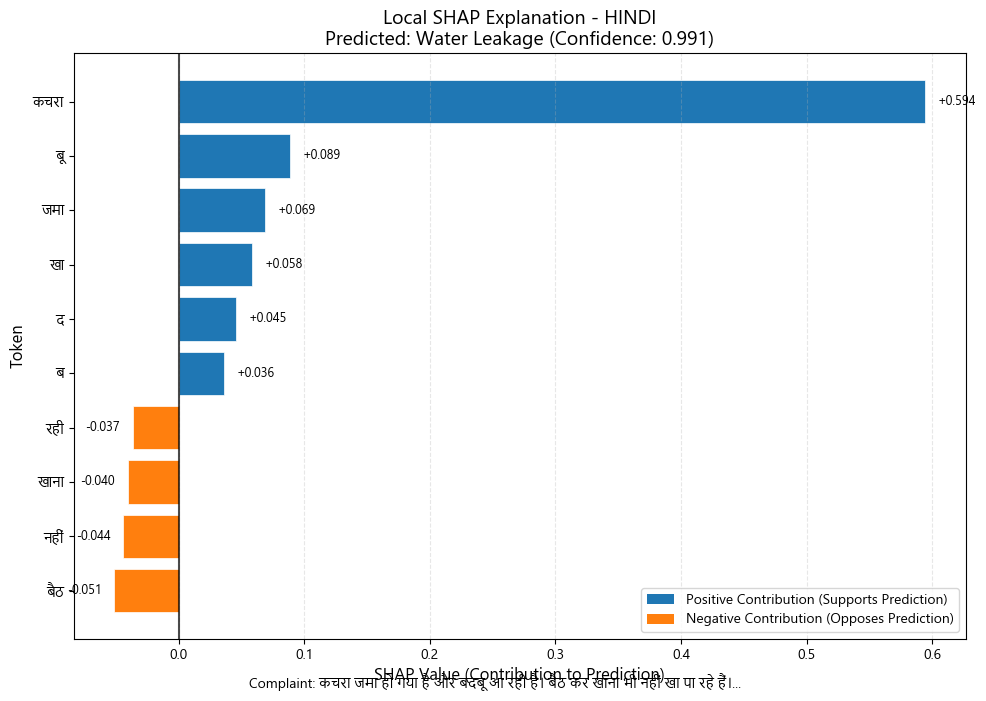

  Sample 3:
    Predicted: Water Leakage (conf: 0.9905)
    Top positive: कचरा(+0.594), बू(+0.089), जमा(+0.069)
    Top negative: बैठ(-0.051), नहीं(-0.044), खाना(-0.040)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hindi\local_explanation_sample_4.png


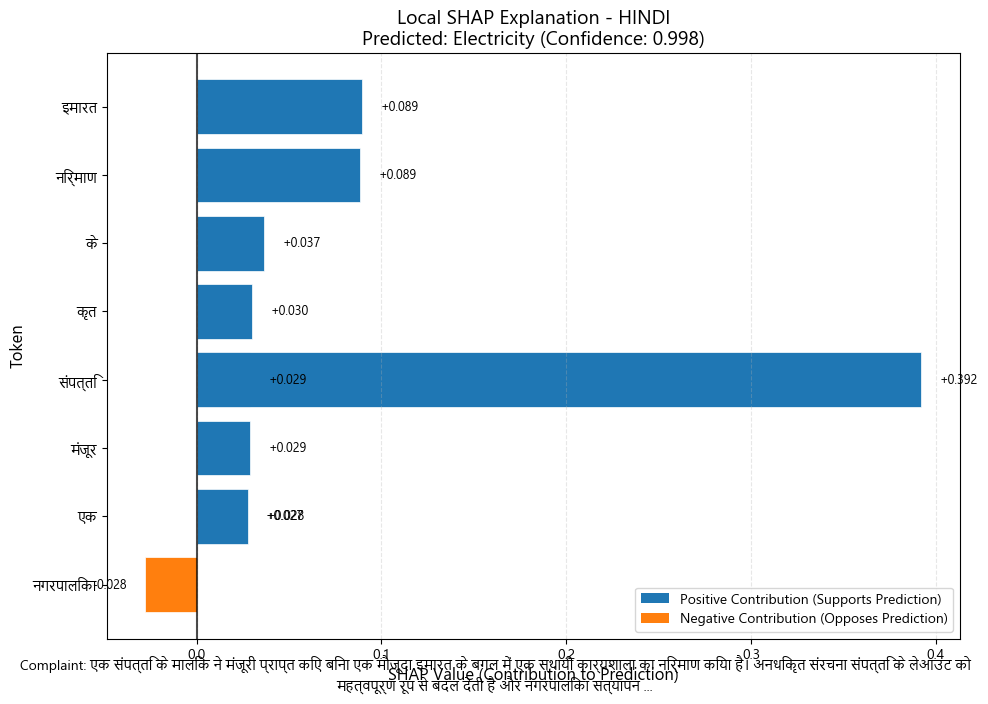

  Sample 4:
    Predicted: Electricity (conf: 0.9981)
    Top positive: संपत्ति(+0.392), इमारत(+0.089), निर्माण(+0.089)
    Top negative: नगरपालिका(-0.028), शाला(-0.023), बदल(-0.021)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hindi\local_explanation_sample_5.png


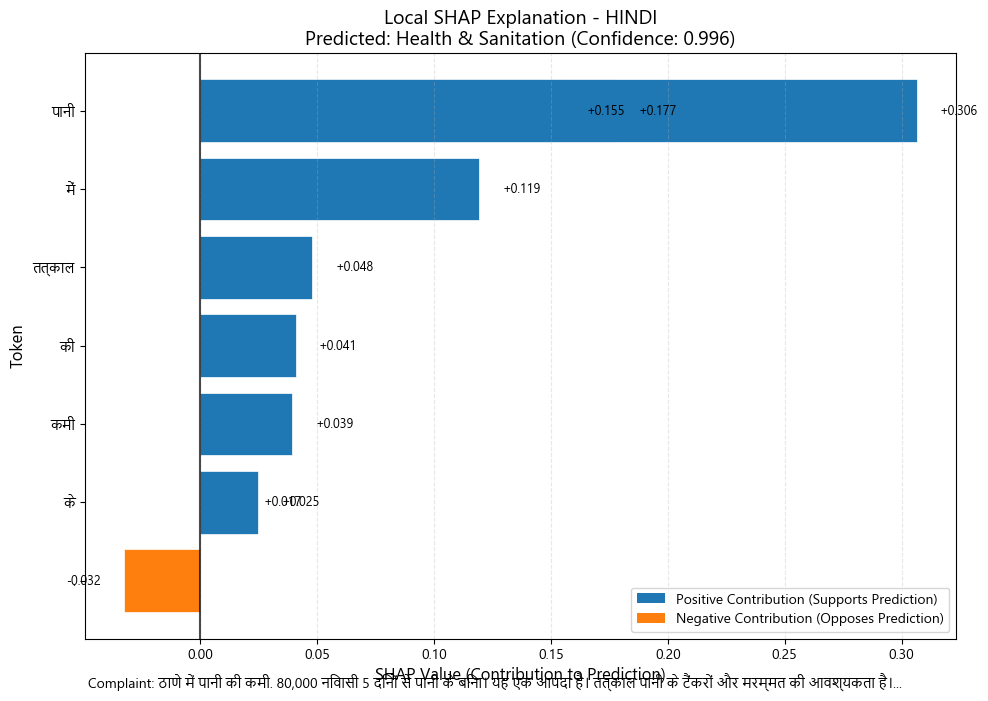

  Sample 5:
    Predicted: Health & Sanitation (conf: 0.9964)
    Top positive: पानी(+0.306), पानी(+0.177), पानी(+0.155)
    Top negative: .(-0.032), निवासी(-0.016), ठाणे(-0.004)
✓ Saved local summary: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hindi\local_explanation_summary.csv

GLOBAL SHAP - HINGLISH TEXTS
Analyzing 30 hinglish samples for global SHAP

Computing hinglish global SHAP values...


PartitionExplainer explainer: 31it [00:52,  2.10s/it]                        


✓ hinglish global SHAP values computed

Calculating hinglish global token importance...

Top hinglish Global SHAP Features:
    token  mean_abs_shap  frequency
    libra       0.171506          1
     pipe       0.153965          2
structure       0.125975          1
  traffic       0.094290          1
    power       0.092328          1
     park       0.085140          2
 vehicles       0.081980          1
     pest       0.081524          1
 cleaning       0.072867          1
 electric       0.072762          1
emergency       0.063996          1
     road       0.061052          4
    spray       0.060203          1
      wer       0.060088          1
 approved       0.058484          1
✓ Saved hinglish global SHAP plot: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\global\hinglish\hinglish_global_shap.png

LOCAL SHAP - HINGLISH TEXTS
Analyzing 5 hinglish samples for local SHAP

Computing hinglish local SHAP 

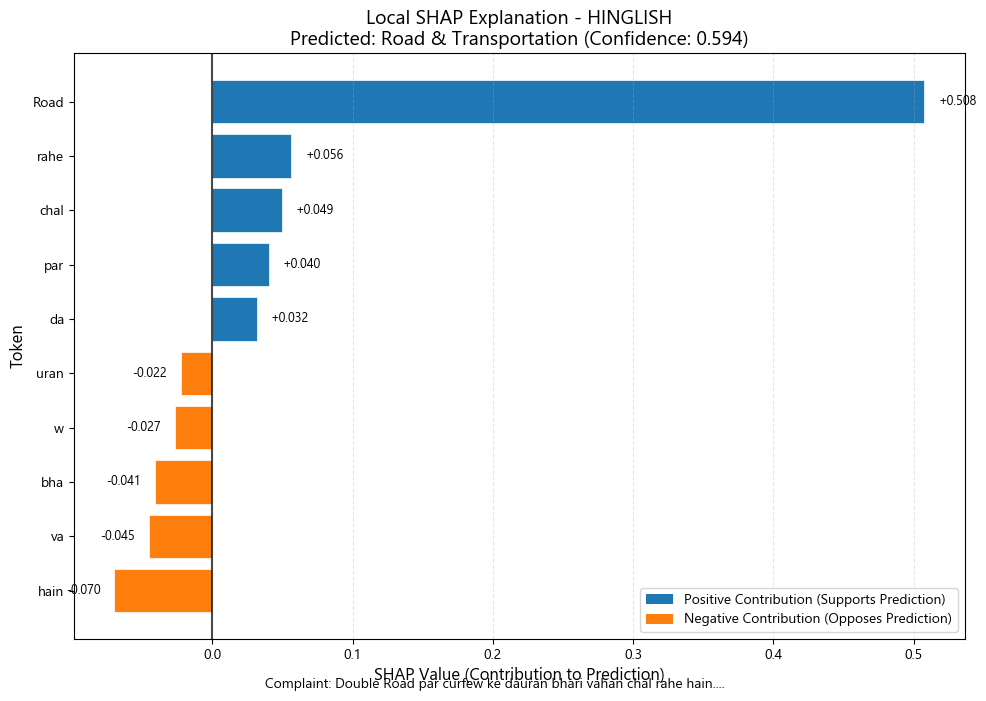

  Sample 1:
    Predicted: Road & Transportation (conf: 0.5940)
    Top positive: Road(+0.508), rahe(+0.056), chal(+0.049)
    Top negative: hain(-0.070), va(-0.045), bha(-0.041)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hinglish\local_explanation_sample_2.png


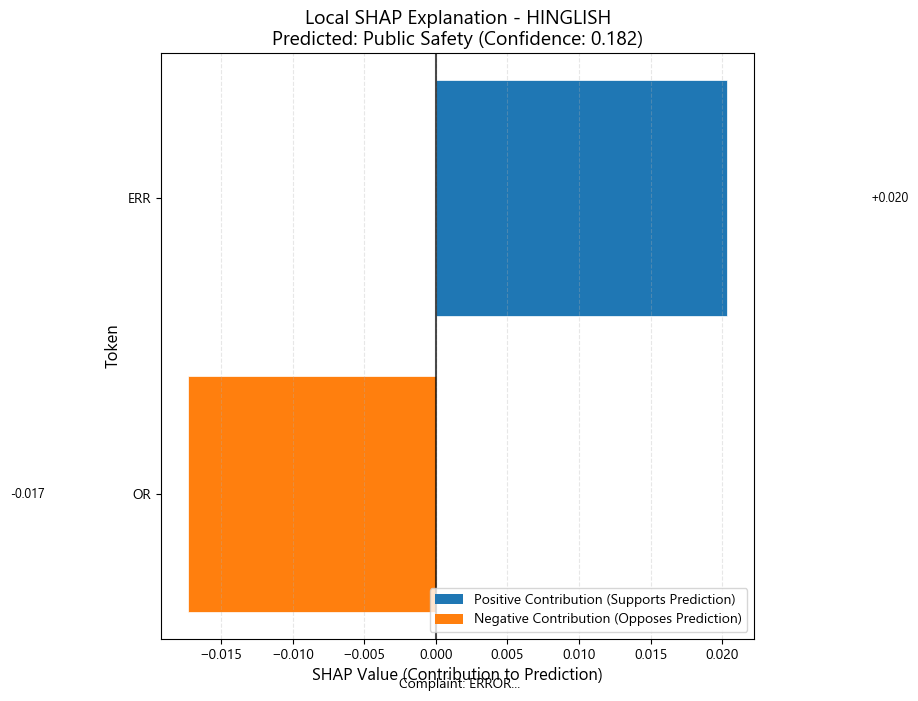

  Sample 2:
    Predicted: Public Safety (conf: 0.1817)
    Top positive: ERR(+0.020)
    Top negative: OR(-0.017)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hinglish\local_explanation_sample_3.png


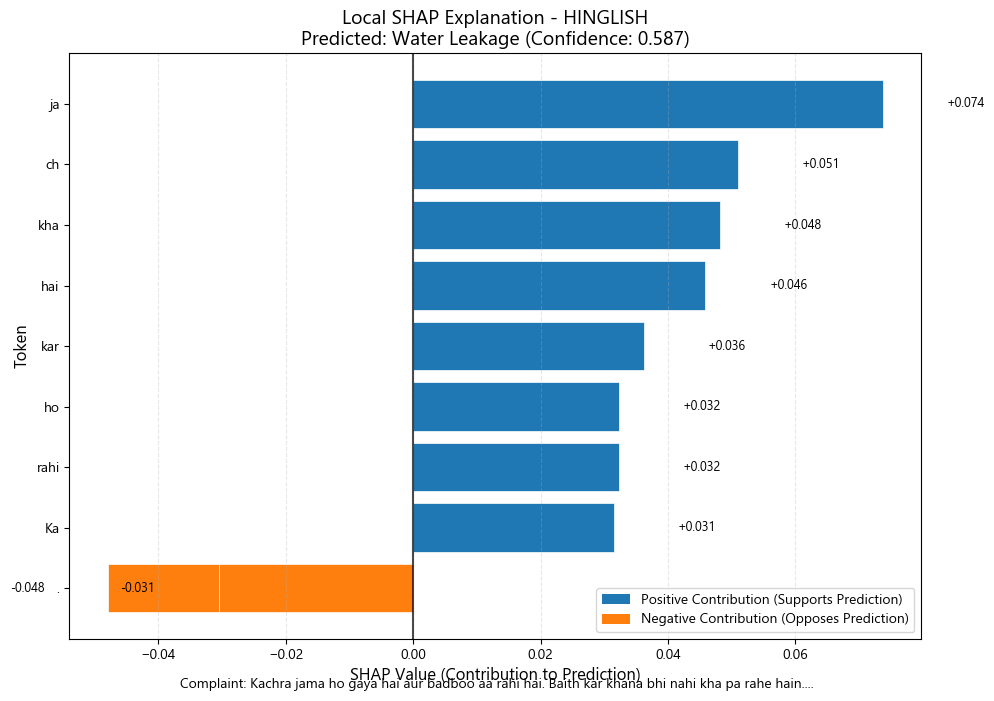

  Sample 3:
    Predicted: Water Leakage (conf: 0.5865)
    Top positive: ja(+0.074), ch(+0.051), kha(+0.048)
    Top negative: .(-0.048), .(-0.031), khan(-0.020)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hinglish\local_explanation_sample_4.png


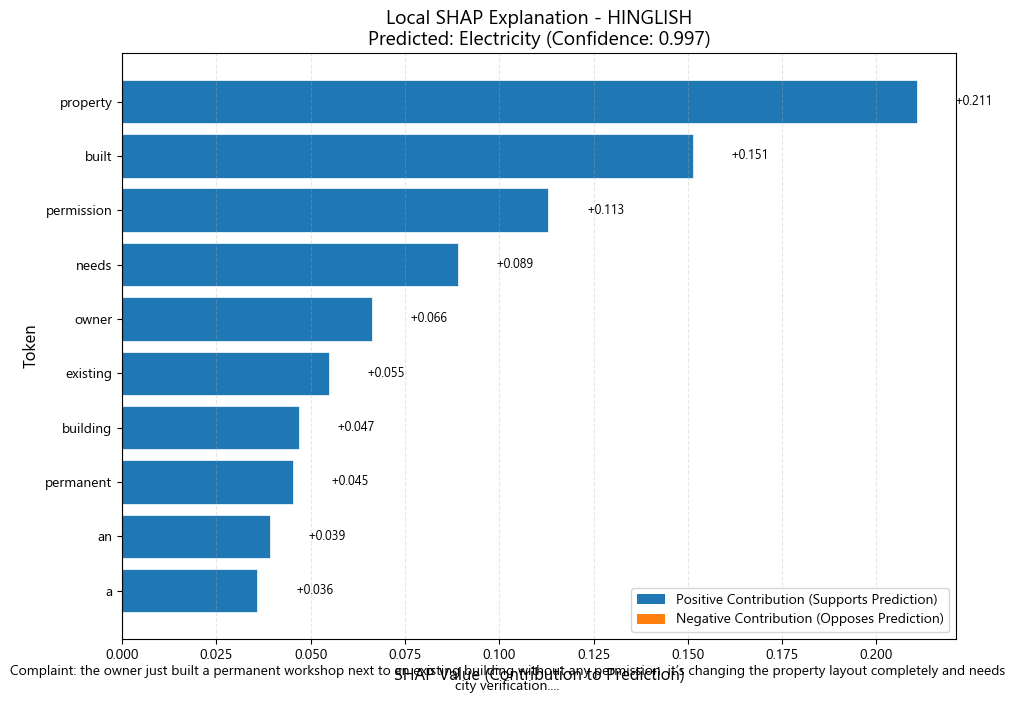

  Sample 4:
    Predicted: Electricity (conf: 0.9970)
    Top positive: property(+0.211), built(+0.151), permission(+0.113)
    Top negative: changing(-0.023), just(-0.023), and(-0.019)
✓ Saved local explanation figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hinglish\local_explanation_sample_5.png


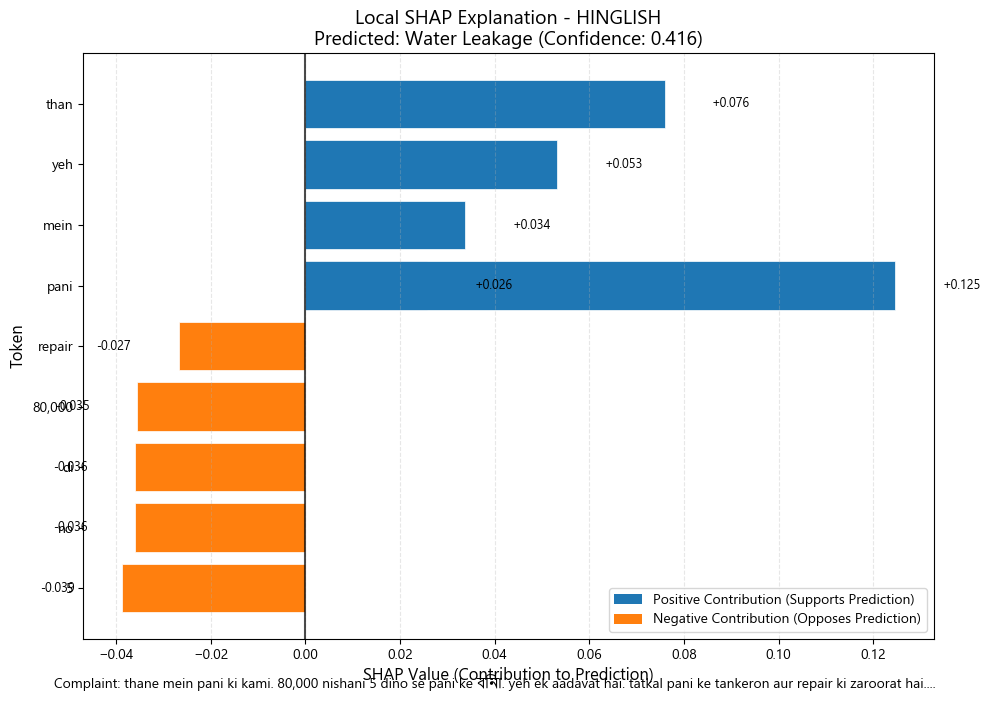

  Sample 5:
    Predicted: Water Leakage (conf: 0.4161)
    Top positive: pani(+0.125), than(+0.076), yeh(+0.053)
    Top negative: 5(-0.039), no(-0.036), di(-0.036)
✓ Saved local summary: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\hinglish\local_explanation_summary.csv

CREATING COMBINED GLOBAL MULTILINGUAL FIGURE
✓ Saved combined global multilingual figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\multilingual_global_shap_comparison.png
✓ Saved combined global multilingual PDF: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\multilingual_global_shap_comparison.pdf


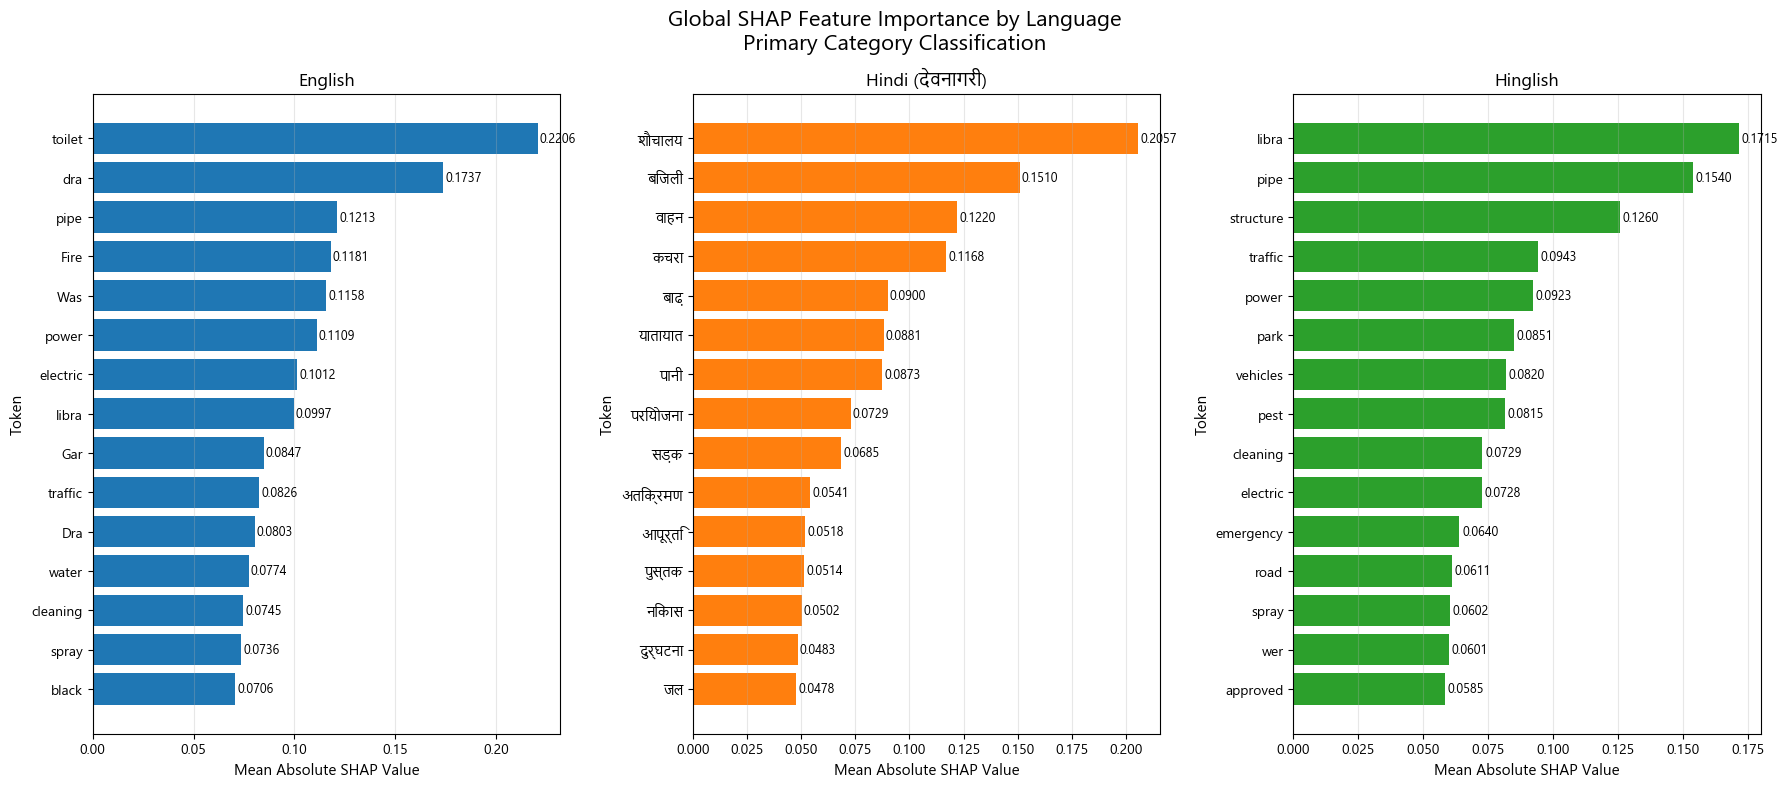


CREATING COMBINED LOCAL MULTILINGUAL FIGURE
✓ Saved combined local explanation figure: combined_local_explanations.png


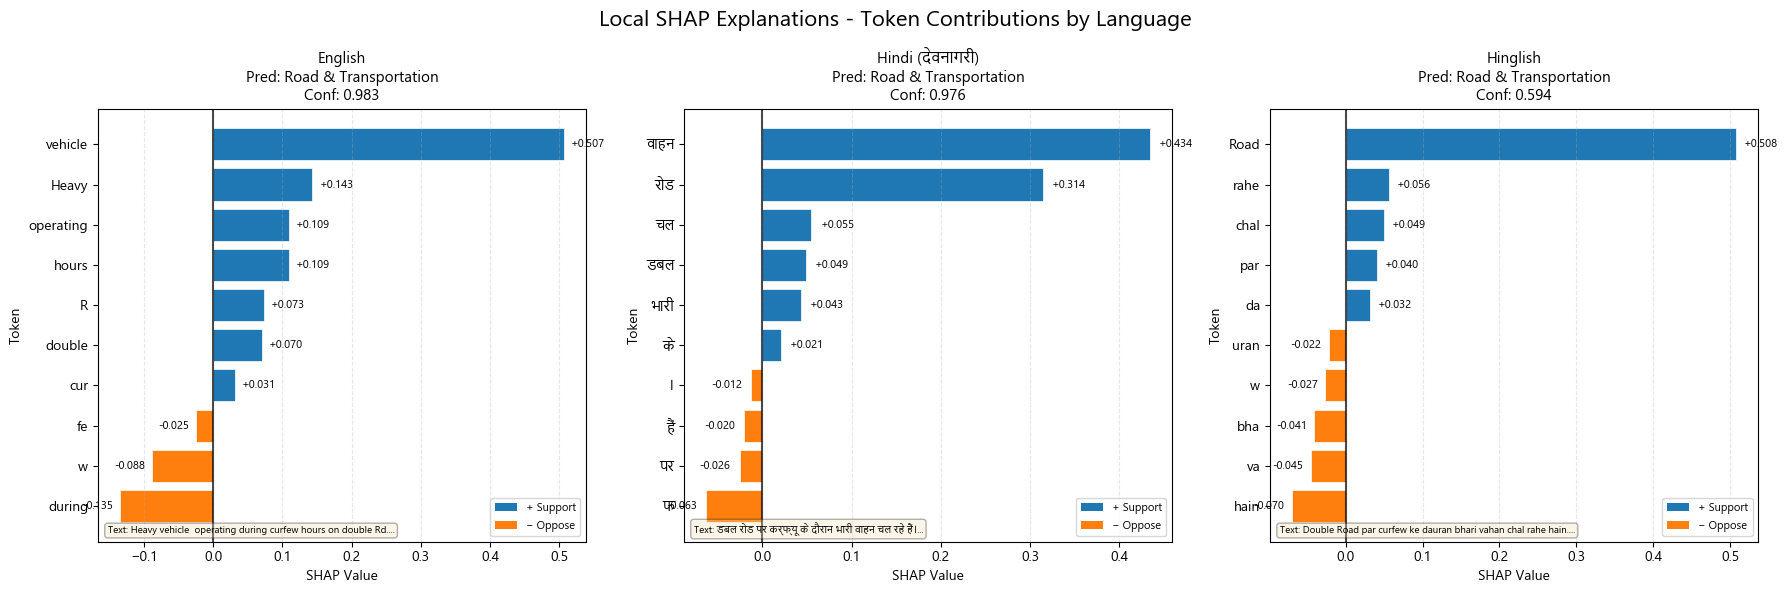

✓ Saved local explanations table: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local\local_explanations_table.txt
✓ Saved metadata: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\shap_metadata.json

MULTILINGUAL SHAP ANALYSIS COMPLETE
Languages analyzed: 3
  - english:
      Global: 30 samples, 599 unique tokens
      Local: 5 samples analyzed
  - hindi:
      Global: 30 samples, 603 unique tokens
      Local: 5 samples analyzed
  - hinglish:
      Global: 30 samples, 656 unique tokens
      Local: 5 samples analyzed

Output directories:
  Global: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\global
  Local: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local
✓ IEEE Access figure saved: C:\Users

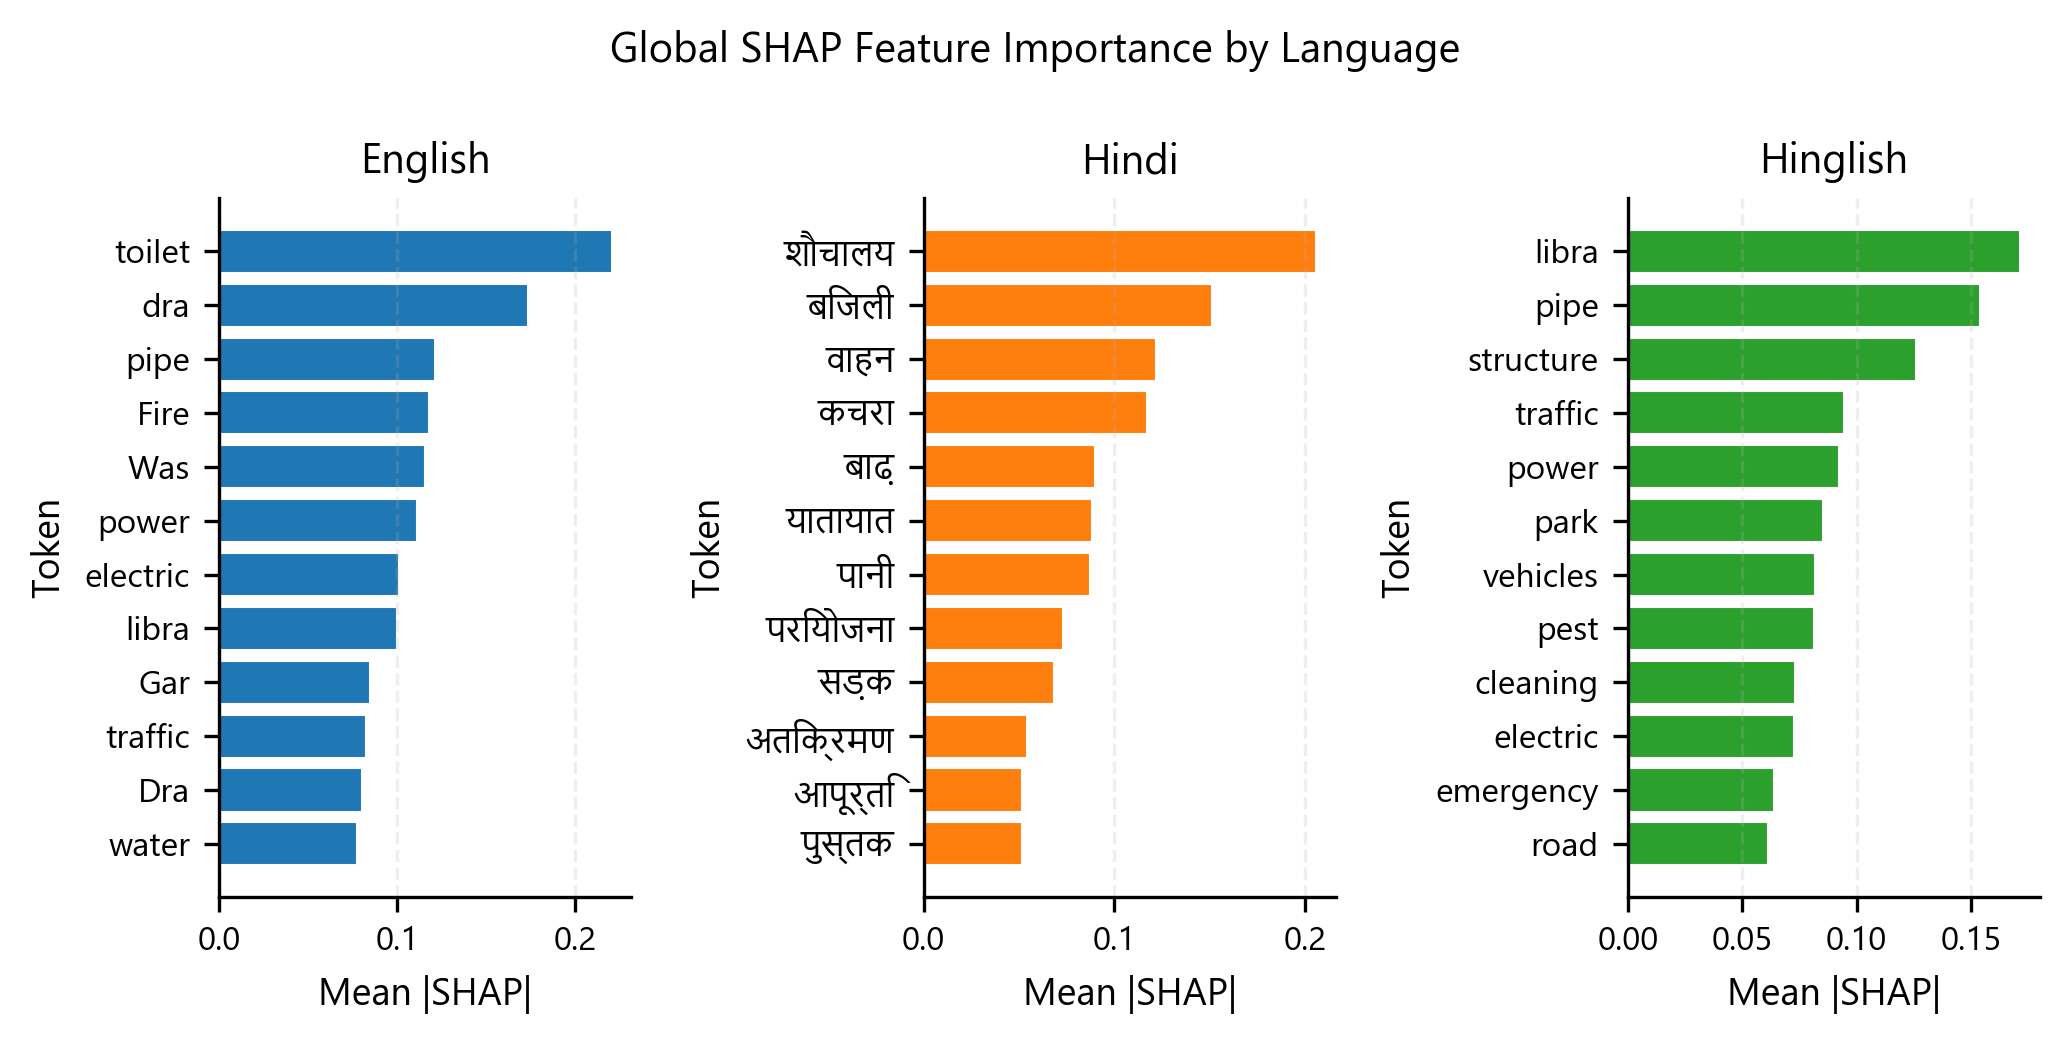


✓ SHAP ANALYSIS COMPLETED SUCCESSFULLY
Global SHAP results: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\global
Local SHAP results: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\local
IEEE figure: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\shap_explanations\multilingual_shap\ieee_access_figure.pdf


In [16]:
# ============================================================================
# CELL 14: SHAP XAI ANALYSIS WITH GLOBAL AND LOCAL EXPLANATIONS (IMPROVED)
# ============================================================================

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
import torch
import os
import re
import pickle
import json
import shap
from matplotlib import rcParams
import unicodedata
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# FONT CONFIGURATION FOR DEVANAGARI
# ============================================================================

def setup_devanagari_fonts():
    """
    Setup matplotlib to properly render Devanagari (Hindi) text.
    """
    devanagari_fonts = [
        'Noto Sans Devanagari',
        'Noto Sans Devanagari UI',
        'Nirmala UI',
        'Mangal',
        'Arial Unicode MS',
        'DejaVu Sans',
        'FreeSerif',
        'Liberation Serif'
    ]
    
    available_fonts = [f.name for f in fm.fontManager.ttflist]
    
    for font in devanagari_fonts:
        if font in available_fonts:
            rcParams['font.family'] = font
            plt.rcParams['font.family'] = font
            print(f"✓ Using Devanagari font: {font}")
            return font
    
    # Fallback
    for font in available_fonts:
        devanagari_keywords = ['devanagari', 'hindi', 'noto', 'nirmala', 'mangal', 'unicode']
        if any(keyword in font.lower() for keyword in devanagari_keywords):
            rcParams['font.family'] = font
            plt.rcParams['font.family'] = font
            print(f"✓ Using Devanagari font: {font}")
            return font
    
    print("⚠ No Devanagari font found. Text may show as boxes.")
    rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.family'] = 'sans-serif'
    return None

setup_devanagari_fonts()

# ============================================================================
# LANGUAGE-SPECIFIC DATA EXTRACTION
# ============================================================================

def extract_language_specific_data(test_df):
    """
    Extract language-specific texts from the dataset.
    Your dataset has separate columns: text_en, Hindi, Hinglish
    """
    language_data = {
        'english': [],
        'hindi': [],
        'hinglish': []
    }
    
    # Check which language columns exist
    if 'text_en' in test_df.columns:
        english_texts = test_df['text_en'].fillna('').astype(str).tolist()
        language_data['english'] = [t for t in english_texts if t.strip()]
        print(f"✓ Found English texts: {len(language_data['english'])}")
    
    if 'Hindi' in test_df.columns:
        hindi_texts = test_df['Hindi'].fillna('').astype(str).tolist()
        language_data['hindi'] = [t for t in hindi_texts if t.strip()]
        print(f"✓ Found Hindi texts: {len(language_data['hindi'])}")
    
    if 'Hinglish' in test_df.columns:
        hinglish_texts = test_df['Hinglish'].fillna('').astype(str).tolist()
        language_data['hinglish'] = [t for t in hinglish_texts if t.strip()]
        print(f"✓ Found Hinglish texts: {len(language_data['hinglish'])}")
    
    # If no language-specific columns found, try to use the combined 'text' column
    if all(len(v) == 0 for v in language_data.values()):
        print("⚠ No language-specific columns found. Using combined 'text' column.")
        if 'text' in test_df.columns:
            all_texts = test_df['text'].fillna('').astype(str).tolist()
            # Categorize by language detection
            for text in all_texts:
                if text.strip():
                    lang = detect_language(text)
                    language_data[lang].append(text)
    
    return language_data

def detect_language(text):
    """
    Detect if text is English, Hindi, or Hinglish.
    """
    devanagari_pattern = re.compile(r'[\u0900-\u097F]')
    devanagari_chars = re.findall(r'[\u0900-\u097F]', text)
    
    if devanagari_chars:
        total_chars = len(re.sub(r'[\s\d\W]', '', text))
        if total_chars > 0:
            devanagari_ratio = len(devanagari_chars) / total_chars
            if devanagari_ratio > 0.3:
                return 'hindi'
            else:
                return 'hinglish'
    return 'english'

# ============================================================================
# TOKEN CLEANING FOR DEVANAGARI
# ============================================================================

def clean_token_for_display(token):
    """
    Clean token for proper display, especially for Devanagari.
    """
    if not token:
        return None
    
    # Remove special tokens
    if token in ["[CLS]", "[SEP]", "[PAD]", "[UNK]"]:
        return None
    
    # Handle BPE tokens
    if token.startswith("##"):
        token = token[2:]
    
    # Remove any non-printable characters
    token = ''.join(char for char in token if unicodedata.category(char)[0] != 'C')
    
    # For Devanagari, ensure proper rendering
    if any('\u0900' <= char <= '\u097F' for char in token):
        return token.strip()
    
    # For English/Hinglish, keep as-is
    return token.strip()

# ============================================================================
# LOCAL SHAP EXPLANATION FUNCTIONS
# ============================================================================

def extract_class_values(explanation, class_index):
    """
    Extract token-level SHAP values for a particular output class.
    """
    values = explanation.values
    
    if values.ndim == 1:
        return values
    
    if values.ndim == 2:
        if class_index < values.shape[1]:
            return values[:, class_index]
    
    return values

def get_predicted_class(probabilities, class_names):
    """
    Get predicted class and confidence.
    """
    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])
    return predicted_index, predicted_class, confidence

def create_local_explanation_table(explanation, predicted_index, class_names, top_k=10):
    """
    Create a detailed table of token contributions for local explanation.
    """
    tokens = [str(token).strip() for token in explanation.data]
    shap_values = extract_class_values(explanation, predicted_index)
    
    # Create dataframe
    token_df = pd.DataFrame({
        'token': tokens,
        'shap_value': shap_values
    })
    
    # Clean tokens
    token_df['cleaned_token'] = token_df['token'].apply(clean_token_for_display)
    token_df = token_df[token_df['cleaned_token'].notna()]
    token_df['abs_shap'] = token_df['shap_value'].abs()
    
    # Sort by absolute SHAP value
    token_df = token_df.sort_values('abs_shap', ascending=False).reset_index(drop=True)
    
    # Get top contributing tokens
    top_positive = token_df[token_df['shap_value'] > 0].head(top_k)
    top_negative = token_df[token_df['shap_value'] < 0].head(top_k)
    
    return token_df, top_positive, top_negative

# ============================================================================
# IMPROVED LOCAL EXPLANATION FIGURE - COMBINED POSITIVE + NEGATIVE
# ============================================================================

def create_combined_local_explanation_figure(top_tokens, predicted_class, confidence, text, language, save_path=None):
    """
    Create a clean local explanation figure with both positive and negative contributions
    in a single bar chart with color coding.
    """
    # Prepare data
    tokens = []
    values = []
    colors = []
    
    for token, value in top_tokens:
        tokens.append(token)
        values.append(value)
        if value > 0:
            colors.append('#1f77b4')  # Blue for positive
        else:
            colors.append('#ff7f0e')  # Orange for negative
    
    # Sort by value (negative to positive)
    sorted_data = sorted(zip(tokens, values, colors), key=lambda x: x[1])
    tokens = [x[0] for x in sorted_data]
    values = [x[1] for x in sorted_data]
    colors = [x[2] for x in sorted_data]
    
    # Create figure
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # Create horizontal bar chart
    bars = ax.barh(tokens, values, color=colors, edgecolor='white', linewidth=0.5)
    
    # Add vertical line at 0
    ax.axvline(0, linewidth=1.5, color='black', alpha=0.7)
    
    # Add labels on bars with + or - signs
    for bar, value in zip(bars, values):
        if value > 0:
            ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, 
                   f'+{value:.3f}', va='center', fontsize=9, fontweight='bold')
        else:
            ax.text(bar.get_width() - 0.01, bar.get_y() + bar.get_height()/2, 
                   f'{value:.3f}', va='center', ha='right', fontsize=9, fontweight='bold')
    
    # Set labels and title
    ax.set_xlabel('SHAP Value (Contribution to Prediction)', fontsize=12)
    ax.set_ylabel('Token', fontsize=12)
    ax.set_title(f'Local SHAP Explanation - {language.upper()}\n'
                f'Predicted: {predicted_class} (Confidence: {confidence:.3f})', 
                fontsize=14, fontweight='bold')
    
    # Add grid
    ax.grid(True, axis='x', alpha=0.3, linestyle='--')
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#1f77b4', label='Positive Contribution (Supports Prediction)'),
        Patch(facecolor='#ff7f0e', label='Negative Contribution (Opposes Prediction)')
    ]
    ax.legend(handles=legend_elements, loc='lower right')
    
    # Add complaint text as footnote
    plt.figtext(0.5, 0.01, f'Complaint: {text[:200]}...', 
                ha='center', fontsize=10, style='italic', wrap=True)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.08)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✓ Saved local explanation figure: {save_path}")
    
    plt.show()
    plt.close()

# ============================================================================
# COMBINED LOCAL FIGURE - ALL LANGUAGES HORIZONTALLY
# ============================================================================

def create_horizontal_local_figure(language_local_data, class_names, save_path=None):
    """
    Create a combined local explanation figure with all languages horizontally.
    Each language shows positive and negative contributions in a single bar chart.
    """
    # Determine figure size
    num_languages = len(language_local_data)
    fig_width = 6 * num_languages
    fig_height = 6
    
    fig, axes = plt.subplots(1, num_languages, figsize=(fig_width, fig_height))
    if num_languages == 1:
        axes = [axes]
    
    fig.suptitle('Local SHAP Explanations - Token Contributions by Language', 
                fontsize=16, fontweight='bold')
    
    # Color mapping
    colors = {
        'english': '#1f77b4',
        'hindi': '#ff7f0e',
        'hinglish': '#2ca02c'
    }
    
    language_names = {
        'english': 'English',
        'hindi': 'Hindi (देवनागरी)',
        'hinglish': 'Hinglish'
    }
    
    TOP_TOKENS_LOCAL = 10
    
    for idx, (language, data) in enumerate(language_local_data.items()):
        if idx >= num_languages:
            break
            
        ax = axes[idx]
        
        # Get token contributions
        token_contrib = data.get('token_contributions', {})
        predicted_class = data.get('predicted_class', 'Unknown')
        confidence = data.get('confidence', 0)
        text = data.get('text', '')
        
        if not token_contrib:
            ax.text(0.5, 0.5, f'No token contributions\nfor {language}', 
                   ha='center', va='center', transform=ax.transAxes)
            ax.set_title(language_names.get(language, language), fontsize=12, fontweight='bold')
            continue
        
        # Sort by absolute value and take top tokens
        sorted_tokens = sorted(token_contrib.items(), key=lambda x: abs(x[1]), reverse=True)[:TOP_TOKENS_LOCAL]
        
        tokens = []
        values = []
        bar_colors = []
        
        for token, value in sorted_tokens:
            tokens.append(token)
            values.append(value)
            if value > 0:
                bar_colors.append('#1f77b4')  # Blue for positive
            else:
                bar_colors.append('#ff7f0e')  # Orange for negative
        
        # Sort by value (negative to positive for better visualization)
        sorted_data = sorted(zip(tokens, values, bar_colors), key=lambda x: x[1])
        tokens = [x[0] for x in sorted_data]
        values = [x[1] for x in sorted_data]
        bar_colors = [x[2] for x in sorted_data]
        
        # Create horizontal bar chart
        bars = ax.barh(tokens, values, color=bar_colors, edgecolor='white', linewidth=0.5)
        
        # Add vertical line at 0
        ax.axvline(0, linewidth=1.5, color='black', alpha=0.7)
        
        # Add labels on bars with + or - signs
        for bar, value in zip(bars, values):
            if value > 0:
                ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, 
                       f'+{value:.3f}', va='center', fontsize=8, fontweight='bold')
            else:
                ax.text(bar.get_width() - 0.01, bar.get_y() + bar.get_height()/2, 
                       f'{value:.3f}', va='center', ha='right', fontsize=8, fontweight='bold')
        
        # Set labels and title
        ax.set_xlabel('SHAP Value', fontsize=10)
        ax.set_ylabel('Token', fontsize=10)
        ax.set_title(f'{language_names.get(language, language)}\nPred: {predicted_class}\nConf: {confidence:.3f}', 
                    fontsize=11, fontweight='bold')
        ax.grid(True, axis='x', alpha=0.3, linestyle='--')
        
        # Add legend for this subplot
        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor='#1f77b4', label='+ Support'),
            Patch(facecolor='#ff7f0e', label='− Oppose')
        ]
        ax.legend(handles=legend_elements, loc='lower right', fontsize=8)
        
        # Add short text preview
        ax.text(0.02, 0.02, f'Text: {text[:100]}...', 
               transform=ax.transAxes, fontsize=7, style='italic',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
    
    # Hide any unused subplots
    for idx in range(len(language_local_data), num_languages):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✓ Saved combined local explanation figure: {save_path}")
    
    plt.show()
    plt.close()

# ============================================================================
# ENHANCED SHAP ANALYSIS WITH GLOBAL AND LOCAL
# ============================================================================

def run_shap_analysis_multilingual(
    model,
    tokenizer,
    test_df,
    device,
    class_names,
    save_dir
):
    """
    SHAP Explainable AI analysis with both GLOBAL and LOCAL explanations.
    """

    print("\n" + "=" * 80)
    print("MULTILINGUAL SHAP EXPLAINABLE AI (XAI) ANALYSIS")
    print("GLOBAL + LOCAL EXPLANATIONS")
    print("=" * 80)

    try:
        import shap
        import re
        import pickle
        import json

        # --------------------------------------------------------------------
        # CREATE OUTPUT DIRECTORIES
        # --------------------------------------------------------------------
        
        multilingual_dir = os.path.join(save_dir, "multilingual_shap")
        global_dir = os.path.join(multilingual_dir, "global")
        local_dir = os.path.join(multilingual_dir, "local")
        
        os.makedirs(multilingual_dir, exist_ok=True)
        os.makedirs(global_dir, exist_ok=True)
        os.makedirs(local_dir, exist_ok=True)
        
        # --------------------------------------------------------------------
        # SHAP CONFIGURATION
        # --------------------------------------------------------------------
        
        GLOBAL_SAMPLES = 30
        LOCAL_SAMPLES = 5
        MAX_LENGTH = 128
        TOP_TOKENS = 15
        LOCAL_TOP_TOKENS = 10

        # --------------------------------------------------------------------
        # EXTRACT LANGUAGE-SPECIFIC TEXTS
        # --------------------------------------------------------------------
        
        print("\nExtracting language-specific data...")
        language_data = extract_language_specific_data(test_df)
        
        print("\nLanguage data distribution:")
        for lang, texts in language_data.items():
            print(f"  {lang}: {len(texts)} samples")
            if len(texts) > 0:
                print(f"    Sample: {texts[0][:100]}...")

        # --------------------------------------------------------------------
        # SHAP PREDICTION FUNCTION
        # --------------------------------------------------------------------

        def shap_predict(texts):
            """
            SHAP-compatible prediction function.
            """
            model.eval()

            if isinstance(texts, str):
                texts = [texts]

            texts = [str(text) for text in texts]
            predictions = []

            BATCH_SIZE = 32

            for start in range(0, len(texts), BATCH_SIZE):
                batch_texts = texts[start:start + BATCH_SIZE]

                encoded = tokenizer(
                    batch_texts,
                    truncation=True,
                    padding=True,
                    max_length=MAX_LENGTH,
                    return_tensors="pt"
                )

                input_ids = encoded["input_ids"].to(device)
                attention_mask = encoded["attention_mask"].to(device)

                sentiment = torch.zeros(input_ids.shape[0], device=device)

                with torch.no_grad():
                    primary_logits, _, _ = model(
                        input_ids,
                        attention_mask,
                        sentiment
                    )
                    probabilities = torch.softmax(primary_logits, dim=1)

                predictions.append(probabilities.detach().cpu().numpy())

            return np.vstack(predictions)

        # --------------------------------------------------------------------
        # CREATE SHAP EXPLAINER
        # --------------------------------------------------------------------
        
        print("\nCreating SHAP Text Explainer...")
        masker = shap.maskers.Text(tokenizer)
        explainer = shap.Explainer(shap_predict, masker)
        print("✓ SHAP Text Explainer created")

        # ====================================================================
        # GLOBAL SHAP ANALYSIS PER LANGUAGE
        # ====================================================================
        
        print("\n" + "=" * 80)
        print("GLOBAL SHAP ANALYSIS PER LANGUAGE")
        print("=" * 80)
        
        language_results = {}
        language_importance_dfs = {}
        language_local_data = {}
        
        for language, texts in language_data.items():
            if len(texts) < 2:
                print(f"\n⚠ Skipping {language}: insufficient samples ({len(texts)})")
                continue
                
            print("\n" + "=" * 80)
            print(f"GLOBAL SHAP - {language.upper()} TEXTS")
            print("=" * 80)
            
            # Select samples for global SHAP
            n_samples = min(GLOBAL_SAMPLES, len(texts))
            rng = np.random.RandomState(42)
            indices = rng.choice(len(texts), size=n_samples, replace=False)
            selected_texts = [texts[i] for i in indices]
            
            print(f"Analyzing {len(selected_texts)} {language} samples for global SHAP")
            
            # Compute SHAP values for global analysis
            print(f"\nComputing {language} global SHAP values...")
            global_shap_values = explainer(selected_texts, max_evals=500)
            print(f"✓ {language} global SHAP values computed")
            
            # Save raw SHAP values
            lang_global_dir = os.path.join(global_dir, language)
            os.makedirs(lang_global_dir, exist_ok=True)
            
            shap_pkl = os.path.join(lang_global_dir, f"global_shap_values.pkl")
            with open(shap_pkl, "wb") as f:
                pickle.dump(global_shap_values, f)
            
            # Calculate global token importance
            print(f"\nCalculating {language} global token importance...")
            token_scores = {}
            
            for sample_idx in range(len(global_shap_values)):
                explanation = global_shap_values[sample_idx]
                tokens = [str(token).strip() for token in explanation.data]
                values = explanation.values
                
                # Handle multiclass output
                if values.ndim == 2:
                    token_contributions = np.mean(np.abs(values), axis=1)
                else:
                    token_contributions = np.abs(values)
                
                # Process each token
                for token, score in zip(tokens, token_contributions):
                    cleaned_token = clean_token_for_display(token)
                    
                    if not cleaned_token:
                        continue
                    
                    # For Hindi, specifically look for Devanagari tokens
                    if language == 'hindi':
                        has_devanagari = any('\u0900' <= char <= '\u097F' for char in cleaned_token)
                        if has_devanagari or len(cleaned_token) > 2:
                            if cleaned_token not in token_scores:
                                token_scores[cleaned_token] = []
                            token_scores[cleaned_token].append(float(score))
                    else:
                        # For English and Hinglish, keep all meaningful tokens
                        if len(cleaned_token) > 1:
                            if cleaned_token not in token_scores:
                                token_scores[cleaned_token] = []
                            token_scores[cleaned_token].append(float(score))
            
            # Create importance dataframe
            importance_rows = []
            for token, scores in token_scores.items():
                importance_rows.append({
                    "token": token,
                    "mean_abs_shap": float(np.mean(scores)),
                    "frequency": len(scores)
                })
            
            importance_df = pd.DataFrame(importance_rows)
            if not importance_df.empty:
                importance_df = importance_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
            else:
                print(f"⚠ No tokens found for {language}")
                continue
            
            # Save importance CSV
            importance_csv = os.path.join(lang_global_dir, "global_token_importance.csv")
            importance_df.to_csv(importance_csv, index=False, encoding="utf-8")
            
            # Store results
            language_results[language] = {
                'shap_values': global_shap_values,
                'texts': selected_texts,
                'importance_df': importance_df
            }
            language_importance_dfs[language] = importance_df
            
            # Print top tokens
            print(f"\nTop {language} Global SHAP Features:")
            if not importance_df.empty:
                top_df = importance_df.head(TOP_TOKENS)
                print(top_df.to_string(index=False))
            
            # Create global SHAP visualization
            plt.figure(figsize=(12, 8))
            
            top_df = importance_df.head(TOP_TOKENS).sort_values('mean_abs_shap')
            tokens = top_df['token'].tolist()
            values = top_df['mean_abs_shap'].tolist()
            
            color = '#1f77b4' if language == 'english' else '#ff7f0e' if language == 'hindi' else '#2ca02c'
            bars = plt.barh(tokens, values, color=color)
            
            plt.xlabel('Mean Absolute SHAP Value', fontsize=12)
            plt.ylabel('Token', fontsize=12)
            plt.title(f'Global SHAP Feature Importance - {language.upper()}', fontsize=14, fontweight='bold')
            plt.grid(True, axis='x', alpha=0.3)
            
            # Add value labels
            for bar, value in zip(bars, values):
                plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, 
                        f'{value:.4f}', va='center', fontsize=10)
            
            plt.tight_layout()
            lang_plot = os.path.join(lang_global_dir, f"{language}_global_shap.png")
            plt.savefig(lang_plot, dpi=300, bbox_inches='tight', facecolor='white')
            plt.close()
            
            print(f"✓ Saved {language} global SHAP plot: {lang_plot}")
            
            # ================================================================
            # LOCAL SHAP ANALYSIS FOR THIS LANGUAGE
            # ================================================================
            
            print(f"\n" + "=" * 80)
            print(f"LOCAL SHAP - {language.upper()} TEXTS")
            print("=" * 80)
            
            # Select samples for local SHAP
            local_n = min(LOCAL_SAMPLES, len(texts))
            local_rng = np.random.RandomState(123)
            local_indices = local_rng.choice(len(texts), size=local_n, replace=False)
            local_texts = [texts[i] for i in local_indices]
            
            print(f"Analyzing {len(local_texts)} {language} samples for local SHAP")
            
            # Compute SHAP values for local analysis
            print(f"\nComputing {language} local SHAP values...")
            local_shap_values = explainer(local_texts, max_evals=500)
            print(f"✓ {language} local SHAP values computed")
            
            # Save local SHAP values
            lang_local_dir = os.path.join(local_dir, language)
            os.makedirs(lang_local_dir, exist_ok=True)
            
            local_pkl = os.path.join(lang_local_dir, f"local_shap_values.pkl")
            with open(local_pkl, "wb") as f:
                pickle.dump(local_shap_values, f)
            
            # Process each local sample
            local_records = []
            best_sample_data = None
            
            for i in range(len(local_shap_values)):
                text = local_texts[i]
                
                # Get prediction
                probabilities = shap_predict([text])[0]
                predicted_index, predicted_class, confidence = get_predicted_class(probabilities, class_names)
                
                # Get explanation
                explanation = local_shap_values[i]
                token_df, top_positive, top_negative = create_local_explanation_table(
                    explanation, predicted_index, class_names, top_k=LOCAL_TOP_TOKENS
                )
                
                # Save token contributions CSV
                safe_class = re.sub(r"[^A-Za-z0-9_-]+", "_", predicted_class)
                token_csv = os.path.join(lang_local_dir, f"sample_{i+1}_{safe_class}_tokens.csv")
                token_df.to_csv(token_csv, index=False, encoding="utf-8")
                
                # Create combined local explanation figure (positive + negative in one chart)
                combined_tokens = []
                for _, row in token_df.head(LOCAL_TOP_TOKENS).iterrows():
                    if row['shap_value'] != 0:
                        combined_tokens.append((row['cleaned_token'], row['shap_value']))
                
                local_fig_path = os.path.join(lang_local_dir, f"local_explanation_sample_{i+1}.png")
                create_combined_local_explanation_figure(
                    top_tokens=combined_tokens,
                    predicted_class=predicted_class,
                    confidence=confidence,
                    text=text,
                    language=language,
                    save_path=local_fig_path
                )
                
                # Create token contribution dictionary for combined figure
                token_contributions = {}
                for _, row in token_df.head(LOCAL_TOP_TOKENS).iterrows():
                    token_contributions[row['cleaned_token']] = row['shap_value']
                
                # Store the first sample's data for combined figure
                if i == 0:
                    best_sample_data = {
                        'text': text,
                        'predicted_class': predicted_class,
                        'confidence': confidence,
                        'token_contributions': token_contributions
                    }
                
                # Create strings for printing
                pos_tokens = []
                for t, v in zip(top_positive['cleaned_token'].tolist()[:3], top_positive['shap_value'].tolist()[:3]):
                    pos_tokens.append(f"{t}(+{v:.3f})")
                pos_str = ", ".join(pos_tokens) if pos_tokens else "None"
                
                neg_tokens = []
                for t, v in zip(top_negative['cleaned_token'].tolist()[:3], top_negative['shap_value'].tolist()[:3]):
                    neg_tokens.append(f"{t}({v:.3f})")
                neg_str = ", ".join(neg_tokens) if neg_tokens else "None"
                
                # Store local summary
                local_records.append({
                    "sample": i + 1,
                    "language": language,
                    "text": text,
                    "predicted_class": predicted_class,
                    "confidence": confidence,
                    "top_positive_tokens": top_positive['cleaned_token'].tolist()[:5],
                    "top_positive_values": top_positive['shap_value'].round(6).tolist()[:5],
                    "top_negative_tokens": top_negative['cleaned_token'].tolist()[:5],
                    "top_negative_values": top_negative['shap_value'].round(6).tolist()[:5]
                })
                
                print(f"  Sample {i+1}:")
                print(f"    Predicted: {predicted_class} (conf: {confidence:.4f})")
                print(f"    Top positive: {pos_str}")
                print(f"    Top negative: {neg_str}")
            
            # Save local summary
            local_summary_df = pd.DataFrame(local_records)
            local_summary_path = os.path.join(lang_local_dir, "local_explanation_summary.csv")
            local_summary_df.to_csv(local_summary_path, index=False, encoding="utf-8")
            print(f"✓ Saved local summary: {local_summary_path}")
            
            # Store local data for combined figure
            if best_sample_data:
                language_local_data[language] = best_sample_data
        
        # ====================================================================
        # CREATE COMBINED GLOBAL MULTILINGUAL FIGURE (HORIZONTAL)
        # ====================================================================
        
        if len(language_results) >= 2:
            print("\n" + "=" * 80)
            print("CREATING COMBINED GLOBAL MULTILINGUAL FIGURE")
            print("=" * 80)
            
            # Create combined figure with 3 subplots horizontally
            fig, axes = plt.subplots(1, 3, figsize=(18, 8))
            fig.suptitle('Global SHAP Feature Importance by Language\nPrimary Category Classification', 
                        fontsize=16, fontweight='bold')
            
            colors = {
                'english': '#1f77b4',
                'hindi': '#ff7f0e',
                'hinglish': '#2ca02c'
            }
            
            language_names = {
                'english': 'English',
                'hindi': 'Hindi (देवनागरी)',
                'hinglish': 'Hinglish'
            }
            
            for idx, (language, importance_df) in enumerate(language_importance_dfs.items()):
                if idx >= 3:
                    break
                    
                ax = axes[idx]
                
                top_df = importance_df.head(TOP_TOKENS).sort_values('mean_abs_shap')
                tokens = top_df['token'].tolist()
                values = top_df['mean_abs_shap'].tolist()
                
                bars = ax.barh(tokens, values, color=colors.get(language, '#333333'))
                
                ax.set_xlabel('Mean Absolute SHAP Value', fontsize=11)
                ax.set_ylabel('Token', fontsize=11)
                ax.set_title(language_names.get(language, language), fontsize=13, fontweight='bold')
                ax.grid(True, axis='x', alpha=0.3)
                
                for bar, value in zip(bars, values):
                    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, 
                           f'{value:.4f}', va='center', fontsize=9)
            
            for idx in range(len(language_results), 3):
                axes[idx].set_visible(False)
            
            plt.tight_layout()
            
            combined_plot = os.path.join(multilingual_dir, "multilingual_global_shap_comparison.png")
            plt.savefig(combined_plot, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"✓ Saved combined global multilingual figure: {combined_plot}")
            
            combined_pdf = os.path.join(multilingual_dir, "multilingual_global_shap_comparison.pdf")
            plt.savefig(combined_pdf, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"✓ Saved combined global multilingual PDF: {combined_pdf}")
            
            plt.show()
            plt.close()
            
            # ================================================================
            # CREATE COMBINED LOCAL MULTILINGUAL FIGURE (HORIZONTAL)
            # ================================================================
            
            if len(language_local_data) >= 2:
                print("\n" + "=" * 80)
                print("CREATING COMBINED LOCAL MULTILINGUAL FIGURE")
                print("=" * 80)
                
                combined_local_path = "combined_local_explanations.png"
                create_horizontal_local_figure(
                    language_local_data, 
                    class_names, 
                    save_path=combined_local_path
                )
            
            # ================================================================
            # CREATE TEXT-BASED LOCAL EXPLANATIONS TABLE
            # ================================================================
            
            local_table_path = os.path.join(local_dir, "local_explanations_table.txt")
            with open(local_table_path, "w", encoding="utf-8") as f:
                f.write("=" * 80 + "\n")
                f.write("LOCAL SHAP EXPLANATIONS - TOKEN CONTRIBUTIONS\n")
                f.write("=" * 80 + "\n\n")
                
                for language, data in language_local_data.items():
                    f.write(f"\n{language.upper()} - Sample Explanation\n")
                    f.write("-" * 50 + "\n")
                    f.write(f"Complaint: {data.get('text', 'N/A')[:200]}...\n")
                    f.write(f"Predicted: {data.get('predicted_class', 'N/A')}\n")
                    f.write(f"Confidence: {data.get('confidence', 0):.4f}\n")
                    
                    f.write("\nToken Contributions:\n")
                    token_contrib = data.get('token_contributions', {})
                    if token_contrib:
                        # Sort by absolute value
                        sorted_tokens = sorted(token_contrib.items(), key=lambda x: abs(x[1]), reverse=True)
                        
                        f.write("\n  Positive Contributions (Support):\n")
                        has_positive = False
                        for token, value in sorted_tokens:
                            if value > 0:
                                f.write(f"    + {token}: +{value:.4f}\n")
                                has_positive = True
                        if not has_positive:
                            f.write("    None\n")
                        
                        f.write("\n  Negative Contributions (Oppose):\n")
                        has_negative = False
                        for token, value in sorted_tokens:
                            if value < 0:
                                f.write(f"    - {token}: {value:.4f}\n")
                                has_negative = True
                        if not has_negative:
                            f.write("    None\n")
                    else:
                        f.write("  No token contributions available\n")
                    
                    f.write("\n" + "-" * 50 + "\n")
            
            print(f"✓ Saved local explanations table: {local_table_path}")
        
        # ====================================================================
        # SAVE METADATA
        # ====================================================================
        
        metadata = {
            "model": Config.BASE_MODEL,
            "analysis": "Multilingual SHAP Text Explainability (Global + Local)",
            "task": "Primary Category Classification",
            "languages_analyzed": list(language_results.keys()),
            "global_samples_per_language": GLOBAL_SAMPLES,
            "local_samples_per_language": LOCAL_SAMPLES,
            "number_of_classes": len(class_names),
            "classes": [str(x) for x in class_names],
            "max_length": MAX_LENGTH,
            "font_used": rcParams['font.family'],
            "interpretation": {
                "global_importance": "Mean absolute SHAP value across analyzed test samples.",
                "local_positive_shap": "Token increases the model output for the predicted class.",
                "local_negative_shap": "Token decreases the model output for the predicted class."
            }
        }
        
        metadata_path = os.path.join(multilingual_dir, "shap_metadata.json")
        with open(metadata_path, "w", encoding="utf-8") as f:
            json.dump(metadata, f, indent=4, ensure_ascii=False)
        
        print(f"✓ Saved metadata: {metadata_path}")
        
        # ====================================================================
        # FINAL SUMMARY
        # ====================================================================
        
        print("\n" + "=" * 80)
        print("MULTILINGUAL SHAP ANALYSIS COMPLETE")
        print("=" * 80)
        print(f"Languages analyzed: {len(language_results)}")
        for language, results in language_results.items():
            print(f"  - {language}:")
            print(f"      Global: {len(results['texts'])} samples, {len(results['importance_df'])} unique tokens")
            print(f"      Local: {LOCAL_SAMPLES} samples analyzed")
        print(f"\nOutput directories:")
        print(f"  Global: {global_dir}")
        print(f"  Local: {local_dir}")
        
        return {
            "language_results": language_results,
            "combined_global_figure": combined_plot if 'combined_plot' in locals() else None,
            "combined_local_figure": combined_local_path if 'combined_local_path' in locals() else None,
            "global_dir": global_dir,
            "local_dir": local_dir,
            "metadata": metadata
        }

    except ImportError as e:
        print("\nSHAP library is not installed.")
        print("Install using: pip install shap")
        return None
    except Exception as e:
        print("\n" + "=" * 80)
        print("SHAP ANALYSIS FAILED")
        print("=" * 80)
        print(f"Error: {e}")
        import traceback
        traceback.print_exc()
        return None


# ============================================================================
# CREATE IEEE ACCESS QUALITY FIGURE
# ============================================================================

def create_ieee_figure(shap_results, save_path=None):
    """
    Create a publication-quality figure for IEEE Access.
    """
    if not shap_results or 'language_results' not in shap_results:
        print("No SHAP results available for figure creation")
        return
    
    language_results = shap_results['language_results']
    
    if len(language_results) < 2:
        print("Insufficient language results for combined figure")
        return
    
    # Create figure with IEEE Access specifications
    fig_width = 7.0
    fig_height = 3.5
    
    fig, axes = plt.subplots(1, 3, figsize=(fig_width, fig_height), dpi=300)
    fig.suptitle('Global SHAP Feature Importance by Language', 
                fontsize=10, fontweight='bold')
    
    colors = {
        'english': '#1f77b4',
        'hindi': '#ff7f0e',
        'hinglish': '#2ca02c'
    }
    
    language_names = {
        'english': 'English',
        'hindi': 'Hindi',
        'hinglish': 'Hinglish'
    }
    
    TOP_TOKENS_FIGURE = 12
    
    for idx, (language, results) in enumerate(language_results.items()):
        if idx >= 3:
            break
        
        importance_df = results['importance_df']
        if importance_df is None or importance_df.empty:
            print(f"⚠ No importance data for {language}")
            continue
            
        ax = axes[idx]
        
        top_df = importance_df.head(TOP_TOKENS_FIGURE).sort_values('mean_abs_shap')
        tokens = top_df['token'].tolist()
        values = top_df['mean_abs_shap'].tolist()
        
        bars = ax.barh(tokens, values, color=colors.get(language, '#333333'), 
                      edgecolor='white', linewidth=0.5)
        
        ax.set_xlabel('Mean |SHAP|', fontsize=9)
        ax.set_ylabel('Token', fontsize=9)
        ax.set_title(language_names.get(language, language), fontsize=10, fontweight='bold')
        ax.grid(True, axis='x', alpha=0.2, linestyle='--')
        ax.tick_params(labelsize=8)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    for idx in range(len(language_results), 3):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"✓ IEEE Access figure saved: {save_path}")
    
    plt.show()
    plt.close()


# ============================================================================
# VERIFY DATASET COLUMNS
# ============================================================================

def verify_dataset_columns(test_df):
    """
    Verify the columns available in the dataset.
    """
    print("\n" + "=" * 80)
    print("VERIFYING DATASET COLUMNS")
    print("=" * 80)
    
    print("Available columns:")
    for col in test_df.columns:
        print(f"  - {col}")
    
    # Check for language-specific columns
    lang_cols = ['text_en', 'Hindi', 'Hinglish']
    found_cols = []
    for col in lang_cols:
        if col in test_df.columns:
            found_cols.append(col)
            non_empty = (test_df[col].fillna('').astype(str).str.strip() != '').sum()
            print(f"\n✓ Found '{col}': {non_empty} non-empty samples")
        else:
            print(f"\n✗ '{col}' not found")
    
    return found_cols


# ============================================================================
# RUN MULTILINGUAL SHAP ANALYSIS WITH GLOBAL + LOCAL
# ============================================================================

print("\n" + "=" * 80)
print("RUNNING MULTILINGUAL SHAP ANALYSIS (GLOBAL + LOCAL)")
print("=" * 80)

# Define class names
if 'category_primary' in test_df.columns:
    class_names = test_df['category_primary'].unique().tolist()
    class_names = [str(c) for c in class_names if pd.notna(c)]
    print(f"✓ Found {len(class_names)} classes from test data")
elif hasattr(preprocessor, 'le_primary'):
    class_names = preprocessor.le_primary.classes_.tolist()
    print(f"✓ Found {len(class_names)} classes from label encoder")
else:
    class_names = [str(i) for i in range(test_df['primary_label'].nunique())]
    print(f"✓ Using {len(class_names)} integer class names")

print(f"Classes: {class_names}")

# First verify dataset columns
found_columns = verify_dataset_columns(test_df)

# Ensure fonts are properly configured
setup_devanagari_fonts()

# Run the analysis
shap_results = run_shap_analysis_multilingual(
    model=model,
    tokenizer=tokenizer,
    test_df=test_df,
    device=Config.DEVICE,
    class_names=class_names,
    save_dir=Config.SHAP_DIR
)

# Create IEEE Access quality figure
if shap_results:
    ieee_fig_dir = os.path.join(Config.SHAP_DIR, "multilingual_shap")
    os.makedirs(ieee_fig_dir, exist_ok=True)
    ieee_fig_path = os.path.join(ieee_fig_dir, "ieee_access_figure.pdf")
    create_ieee_figure(shap_results, ieee_fig_path)
    
    print("\n" + "=" * 80)
    print("✓ SHAP ANALYSIS COMPLETED SUCCESSFULLY")
    print("=" * 80)
    print(f"Global SHAP results: {shap_results['global_dir']}")
    print(f"Local SHAP results: {shap_results['local_dir']}")
    print(f"IEEE figure: {ieee_fig_path}")


STARTING ENHANCED ABLATION STUDY
Model Config: Hidden=768, Primary=8, Subcat=24, Severity=3

ENHANCED ABLATION STUDY

Evaluating: baseline


  Primary Accuracy: 0.0685
  Primary F1 (weighted): 0.0862
  Overall Accuracy: 0.1444
  Overall F1: 0.1432

Evaluating: attention_pooling


  Primary Accuracy: 0.1831
  Primary F1 (weighted): 0.1368
  Overall Accuracy: 0.1891
  Overall F1: 0.1460

Evaluating: deeper_shared


  Primary Accuracy: 0.0853
  Primary F1 (weighted): 0.0791
  Overall Accuracy: 0.1077
  Overall F1: 0.0991

Evaluating: multi_head_attention


  Primary Accuracy: 0.1973
  Primary F1 (weighted): 0.1900
  Overall Accuracy: 0.1991
  Overall F1: 0.1898

Evaluating: ensemble_heads


  Primary Accuracy: 0.0326
  Primary F1 (weighted): 0.0304
  Overall Accuracy: 0.1476
  Overall F1: 0.1406

Evaluating: contrastive_head


  Primary Accuracy: 0.1966
  Primary F1 (weighted): 0.1826
  Overall Accuracy: 0.1977
  Overall F1: 0.1900

Evaluating: dropout_0.1


  Primary Accuracy: 0.1140
  Primary F1 (weighted): 0.1147
  Overall Accuracy: 0.1879
  Overall F1: 0.1699

Evaluating: dropout_0.3


  Primary Accuracy: 0.0939
  Primary F1 (weighted): 0.0549
  Overall Accuracy: 0.1400
  Overall F1: 0.1218

Evaluating: dropout_0.4


  Primary Accuracy: 0.1512
  Primary F1 (weighted): 0.1448
  Overall Accuracy: 0.1513
  Overall F1: 0.1434

Evaluating: dropout_0.5


  Primary Accuracy: 0.1334
  Primary F1 (weighted): 0.1313
  Overall Accuracy: 0.1719
  Overall F1: 0.1617
✓ Visualization saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/enhanced_ablation_study.png


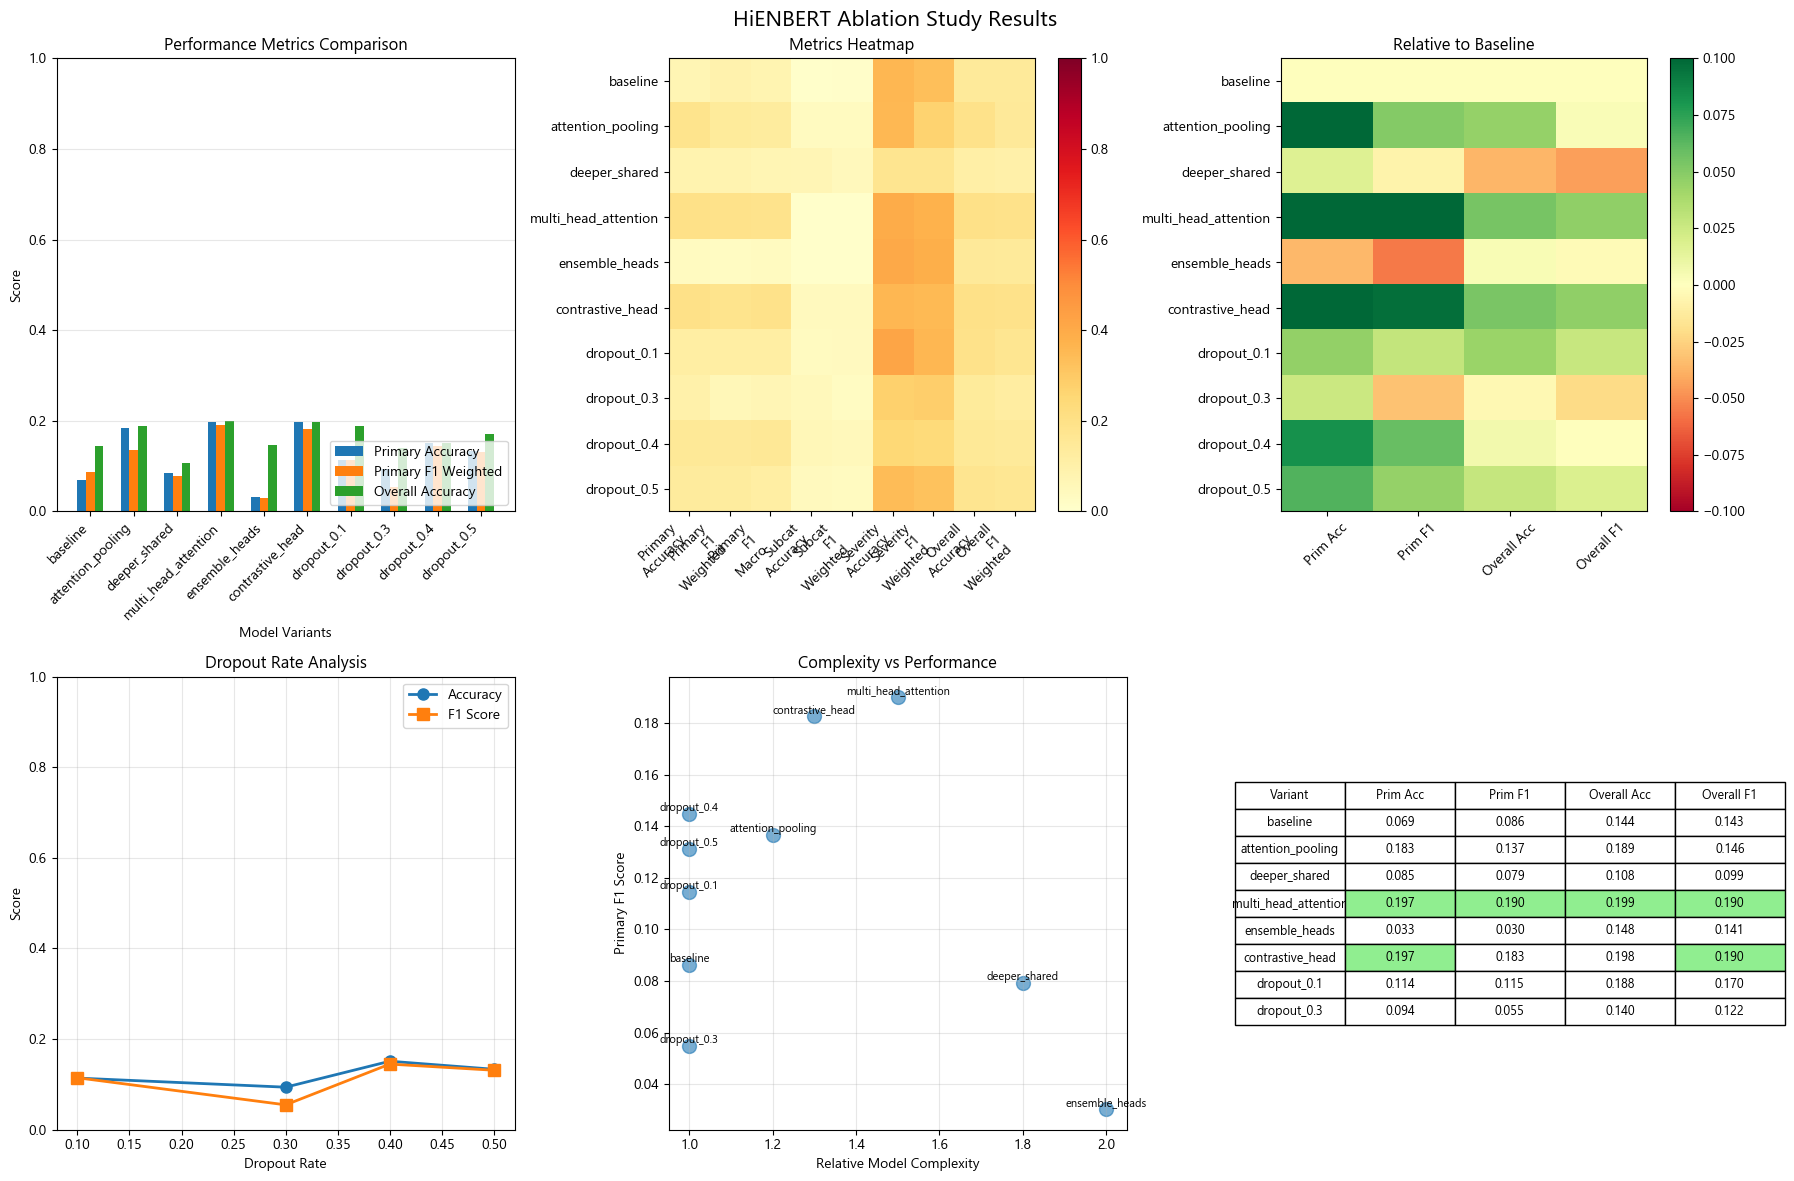


ABLATION STUDY DETAILED REPORT

Best Performing Variants:
  primary_accuracy: multi_head_attention (0.1973)
  primary_f1_weighted: multi_head_attention (0.1900)
  overall_accuracy: multi_head_attention (0.1991)
  overall_f1_weighted: contrastive_head (0.1900)

Improvements over Baseline:
  attention_pooling: primary_accuracy: +0.1146, primary_f1_weighted: +0.0506, overall_accuracy: +0.0447
  deeper_shared: primary_accuracy: +0.0168, primary_f1_weighted: -0.0071, overall_accuracy: -0.0367
  multi_head_attention: primary_accuracy: +0.1288, primary_f1_weighted: +0.1039, overall_accuracy: +0.0547
  ensemble_heads: primary_accuracy: -0.0359, primary_f1_weighted: -0.0558, overall_accuracy: +0.0032
  contrastive_head: primary_accuracy: +0.1281, primary_f1_weighted: +0.0965, overall_accuracy: +0.0534
  dropout_0.1: primary_accuracy: +0.0455, primary_f1_weighted: +0.0285, overall_accuracy: +0.0435
  dropout_0.3: primary_accuracy: +0.0254, primary_f1_weighted: -0.0313, overall_accuracy: -0.0044

In [15]:
# ============================================================================
# CELL 15: ENHANCED ABLATION STUDY (COMPLETELY FIXED)
# ============================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from collections import defaultdict
import pandas as pd
import json
import os

# ============================================================================
# DATASET CLASS DEFINED AT MODULE LEVEL (FIXES PICKLING ISSUE)
# ============================================================================

class AblationDataset(Dataset):
    """Dataset class for ablation study - defined at module level for pickling"""
    def __init__(self, data, tokenizer, max_length=128, include_labels=True):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.include_labels = include_labels
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        
        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'sentiment': torch.tensor(0.0, dtype=torch.float)
        }
        
        if self.include_labels and 'primary_label' in row:
            item['primary'] = torch.tensor(row['primary_label'], dtype=torch.long)
            if 'subcat_label' in row:
                item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
            if 'severity_label' in row:
                item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)
        
        return item

# ============================================================================
# MODEL VARIANTS DEFINED AT MODULE LEVEL
# ============================================================================

class BaselineModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

class AttentionPoolingModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1)
        )
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state
        
        attention_weights = self.attention(hidden_states)
        attention_weights = F.softmax(attention_weights, dim=1)
        pooled = torch.sum(hidden_states * attention_weights, dim=1)
        
        x = self.dropout(pooled)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

class DeeperSharedModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.shared_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size, hidden_size),
                nn.LayerNorm(hidden_size),
                nn.GELU(),
                nn.Dropout(dropout)
            ) for _ in range(3)
        ])
        
        self.fc_primary = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, n_primary)
        )
        self.fc_subcat = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, n_subcat)
        )
        self.fc_severity = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, n_severity)
        )
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        
        x = cls
        for layer in self.shared_layers:
            x = layer(x) + x
        
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

class MultiHeadAttentionModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.self_attn = nn.MultiheadAttention(hidden_size, num_heads=8, dropout=dropout, batch_first=True)
        self.layer_norm = nn.LayerNorm(hidden_size)
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state
        
        attn_output, _ = self.self_attn(hidden_states, hidden_states, hidden_states)
        attn_output = self.layer_norm(attn_output + hidden_states)
        cls = attn_output[:, 0, :]
        
        x = self.dropout(cls)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

class EnsembleHeadsModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.num_heads = 3
        
        self.primary_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size, hidden_size // 2),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_size // 2, n_primary)
            ) for _ in range(self.num_heads)
        ])
        
        self.subcat_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size, hidden_size // 2),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_size // 2, n_subcat)
            ) for _ in range(self.num_heads)
        ])
        
        self.severity_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size, hidden_size // 2),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_size // 2, n_severity)
            ) for _ in range(self.num_heads)
        ])
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls)
        
        primary_logits = torch.stack([head(x) for head in self.primary_heads]).mean(0)
        subcat_logits = torch.stack([head(x) for head in self.subcat_heads]).mean(0)
        severity_logits = torch.stack([head(x) for head in self.severity_heads]).mean(0)
        
        return primary_logits, subcat_logits, severity_logits

class ContrastiveModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        self.projection = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 128)
        )
        
        self.fc_primary = nn.Linear(hidden_size + 128, n_primary)
        self.fc_subcat = nn.Linear(hidden_size + 128, n_subcat)
        self.fc_severity = nn.Linear(hidden_size + 128, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        
        x = self.dropout(cls)
        proj = self.projection(x)
        combined = torch.cat([x, proj], dim=1)
        
        return self.fc_primary(combined), self.fc_subcat(combined), self.fc_severity(combined)

class DropoutVariantModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout):
        super().__init__()
        self.base = base_model
        hidden_size = 768
        if hasattr(self.base, 'config'):
            hidden_size = self.base.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

# ============================================================================
# ENHANCED ABLATION STUDY CLASS
# ============================================================================

class EnhancedAblationStudy:
    """Enhanced ablation study with comprehensive architectural variants"""
    
    def __init__(self, base_model, tokenizer, test_df, device, train_df=None):
        self.base_model = base_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.train_df = train_df
        self.device = device
        self.results = {}
        self.detailed_results = defaultdict(dict)
        
        # Get model configuration
        self.base = base_model.base if hasattr(base_model, 'base') else base_model
        
        self.hidden_size = 768
        if hasattr(self.base, 'config'):
            self.hidden_size = self.base.config.hidden_size
        
        self.n_primary = base_model.n_primary if hasattr(base_model, 'n_primary') else 0
        self.n_subcat = base_model.n_subcat if hasattr(base_model, 'n_subcat') else 0
        self.n_severity = base_model.n_severity if hasattr(base_model, 'n_severity') else 0
        
        print(f"Model Config: Hidden={self.hidden_size}, "
              f"Primary={self.n_primary}, Subcat={self.n_subcat}, Severity={self.n_severity}")
        
        # Use num_workers=0 on Windows to avoid pickling issues
        self.num_workers = 0 if os.name == 'nt' else 2
        
        self._prepare_data()
    
    def _prepare_data(self):
        """Prepare test data - using module-level Dataset class"""
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, 
            batch_size=64, 
            shuffle=False, 
            num_workers=self.num_workers
        )
        
        if self.train_df is not None:
            self.train_dataset = AblationDataset(self.train_df, self.tokenizer)
            self.train_loader = DataLoader(
                self.train_dataset, 
                batch_size=64, 
                shuffle=False, 
                num_workers=self.num_workers
            )
    
    def evaluate_model(self, model, description="", dataloader=None):
        """Comprehensive evaluation with detailed metrics"""
        model.eval()
        
        all_primary_preds = []
        all_primary_labels = []
        all_subcat_preds = []
        all_subcat_labels = []
        all_severity_preds = []
        all_severity_labels = []
        
        loader = dataloader if dataloader else self.test_loader
        
        with torch.no_grad():
            for batch in tqdm(loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                
                # Primary predictions
                preds = torch.argmax(p1, dim=1)
                all_primary_preds.extend(preds.cpu().numpy())
                if 'primary' in batch:
                    all_primary_labels.extend(batch['primary'].cpu().numpy())
                
                # Subcategory predictions
                if 'subcat' in batch:
                    preds2 = torch.argmax(p2, dim=1)
                    all_subcat_preds.extend(preds2.cpu().numpy())
                    all_subcat_labels.extend(batch['subcat'].cpu().numpy())
                
                # Severity predictions
                if 'severity' in batch:
                    preds3 = torch.argmax(p3, dim=1)
                    all_severity_preds.extend(preds3.cpu().numpy())
                    all_severity_labels.extend(batch['severity'].cpu().numpy())
        
        # Calculate metrics
        metrics = {}
        
        if all_primary_labels:
            metrics['primary_accuracy'] = accuracy_score(all_primary_labels, all_primary_preds)
            metrics['primary_f1_weighted'] = f1_score(all_primary_labels, all_primary_preds, average='weighted', zero_division=0)
            metrics['primary_f1_macro'] = f1_score(all_primary_labels, all_primary_preds, average='macro', zero_division=0)
            metrics['primary_f1_micro'] = f1_score(all_primary_labels, all_primary_preds, average='micro', zero_division=0)
        
        if all_subcat_labels:
            metrics['subcat_accuracy'] = accuracy_score(all_subcat_labels, all_subcat_preds)
            metrics['subcat_f1_weighted'] = f1_score(all_subcat_labels, all_subcat_preds, average='weighted', zero_division=0)
        
        if all_severity_labels:
            metrics['severity_accuracy'] = accuracy_score(all_severity_labels, all_severity_preds)
            metrics['severity_f1_weighted'] = f1_score(all_severity_labels, all_severity_preds, average='weighted', zero_division=0)
        
        # Overall metrics
        metrics['overall_accuracy'] = np.mean([
            metrics.get('primary_accuracy', 0),
            metrics.get('subcat_accuracy', 0),
            metrics.get('severity_accuracy', 0)
        ])
        
        metrics['overall_f1_weighted'] = np.mean([
            metrics.get('primary_f1_weighted', 0),
            metrics.get('subcat_f1_weighted', 0),
            metrics.get('severity_f1_weighted', 0)
        ])
        
        return metrics
    
    # ========================================================================
    # MODEL CREATION METHODS
    # ========================================================================
    
    def _create_baseline(self):
        return BaselineModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_attention_pooling(self):
        return AttentionPoolingModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_deeper_shared(self):
        return DeeperSharedModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_multi_head_attention(self):
        return MultiHeadAttentionModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_ensemble_heads(self):
        return EnsembleHeadsModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_contrastive_head(self):
        return ContrastiveModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout=0.2
        )
    
    def _create_dropout_variant(self, dropout_rate):
        return DropoutVariantModel(
            self.base, self.n_primary, self.n_subcat, self.n_severity, dropout_rate
        )
    
    # ========================================================================
    # RUN ABLATION STUDY
    # ========================================================================
    
    def run_study(self):
        """Run comprehensive ablation study with all variants"""
        print("\n" + "="*80)
        print("ENHANCED ABLATION STUDY")
        print("="*80)
        
        # Define model variants as tuples (name, creator_function)
        variants = [
            ('baseline', self._create_baseline),
            ('attention_pooling', self._create_attention_pooling),
            ('deeper_shared', self._create_deeper_shared),
            ('multi_head_attention', self._create_multi_head_attention),
            ('ensemble_heads', self._create_ensemble_heads),
            ('contrastive_head', self._create_contrastive_head),
        ]
        
        # Add dropout variants
        for dropout_rate in [0.1, 0.3, 0.4, 0.5]:
            variants.append(
                (f'dropout_{dropout_rate}', 
                 lambda d=dropout_rate: self._create_dropout_variant(d))
            )
        
        # Evaluate each variant
        for name, builder in variants:
            print(f"\n{'='*60}")
            print(f"Evaluating: {name}")
            print('='*60)
            
            try:
                model = builder()
                model = model.to(self.device)
                
                # Evaluate on test set
                metrics = self.evaluate_model(model, name)
                self.results[name] = metrics
                
                # Print results
                print(f"  Primary Accuracy: {metrics.get('primary_accuracy', 0):.4f}")
                print(f"  Primary F1 (weighted): {metrics.get('primary_f1_weighted', 0):.4f}")
                print(f"  Overall Accuracy: {metrics.get('overall_accuracy', 0):.4f}")
                print(f"  Overall F1: {metrics.get('overall_f1_weighted', 0):.4f}")
                
                # Store detailed results
                self.detailed_results[name] = metrics
                
                # Clean up GPU memory
                del model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                
            except Exception as e:
                print(f"  ✗ Failed: {e}")
                import traceback
                traceback.print_exc()
        
        return self.results
    
    # ========================================================================
    # VISUALIZATION
    # ========================================================================
    
    def visualize_results(self, save_path=None):
        """Create comprehensive visualization of ablation results"""
        if not self.results:
            print("No results to visualize")
            return
        
        # Prepare data
        variants = list(self.results.keys())
        
        # Create figure with subplots
        fig = plt.figure(figsize=(18, 12))
        
        # 1. Main metrics comparison
        ax1 = plt.subplot(2, 3, 1)
        x = np.arange(len(variants))
        width = 0.2
        
        for i, metric in enumerate(['primary_accuracy', 'primary_f1_weighted', 'overall_accuracy']):
            values = [self.results[v].get(metric, 0) for v in variants]
            ax1.bar(x + i*width, values, width, label=metric.replace('_', ' ').title())
        
        ax1.set_xlabel('Model Variants')
        ax1.set_ylabel('Score')
        ax1.set_title('Performance Metrics Comparison', fontsize=12, fontweight='bold')
        ax1.set_xticks(x + width)
        ax1.set_xticklabels(variants, rotation=45, ha='right')
        ax1.legend(loc='lower right')
        ax1.grid(True, alpha=0.3, axis='y')
        ax1.set_ylim(0, 1)
        
        # 2. Heatmap of all metrics
        ax2 = plt.subplot(2, 3, 2)
        all_metrics = ['primary_accuracy', 'primary_f1_weighted', 'primary_f1_macro',
                      'subcat_accuracy', 'subcat_f1_weighted', 'severity_accuracy', 
                      'severity_f1_weighted', 'overall_accuracy', 'overall_f1_weighted']
        
        metric_data = []
        for variant in variants:
            row = [self.results[variant].get(m, 0) for m in all_metrics]
            metric_data.append(row)
        
        im = ax2.imshow(metric_data, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
        ax2.set_xticks(np.arange(len(all_metrics)))
        ax2.set_xticklabels([m.replace('_', '\n').title() for m in all_metrics], rotation=45, ha='right')
        ax2.set_yticks(np.arange(len(variants)))
        ax2.set_yticklabels(variants)
        ax2.set_title('Metrics Heatmap', fontsize=12, fontweight='bold')
        plt.colorbar(im, ax=ax2)
        
        # 3. Relative performance compared to baseline
        ax3 = plt.subplot(2, 3, 3)
        baseline_metrics = self.results.get('baseline', {})
        
        if baseline_metrics:
            relative_data = []
            for variant in variants:
                if variant == 'baseline':
                    relative_data.append([0] * 4)
                else:
                    rel = [
                        self.results[variant].get('primary_accuracy', 0) - baseline_metrics.get('primary_accuracy', 0),
                        self.results[variant].get('primary_f1_weighted', 0) - baseline_metrics.get('primary_f1_weighted', 0),
                        self.results[variant].get('overall_accuracy', 0) - baseline_metrics.get('overall_accuracy', 0),
                        self.results[variant].get('overall_f1_weighted', 0) - baseline_metrics.get('overall_f1_weighted', 0)
                    ]
                    relative_data.append(rel)
            
            rel_array = np.array(relative_data)
            im2 = ax3.imshow(rel_array, cmap='RdYlGn', aspect='auto', vmin=-0.1, vmax=0.1)
            ax3.set_xticks(np.arange(4))
            ax3.set_xticklabels(['Prim Acc', 'Prim F1', 'Overall Acc', 'Overall F1'], rotation=45)
            ax3.set_yticks(np.arange(len(variants)))
            ax3.set_yticklabels(variants)
            ax3.set_title('Relative to Baseline', fontsize=12, fontweight='bold')
            plt.colorbar(im2, ax=ax3)
        
        # 4. Dropout analysis
        ax4 = plt.subplot(2, 3, 4)
        dropout_variants = [v for v in variants if v.startswith('dropout_')]
        if dropout_variants:
            dropout_rates = [float(v.split('_')[1]) for v in dropout_variants]
            dropout_acc = [self.results[v].get('primary_accuracy', 0) for v in dropout_variants]
            dropout_f1 = [self.results[v].get('primary_f1_weighted', 0) for v in dropout_variants]
            
            ax4.plot(dropout_rates, dropout_acc, 'o-', label='Accuracy', linewidth=2, markersize=8)
            ax4.plot(dropout_rates, dropout_f1, 's-', label='F1 Score', linewidth=2, markersize=8)
            ax4.set_xlabel('Dropout Rate')
            ax4.set_ylabel('Score')
            ax4.set_title('Dropout Rate Analysis', fontsize=12, fontweight='bold')
            ax4.legend()
            ax4.grid(True, alpha=0.3)
            ax4.set_ylim(0, 1)
        
        # 5. Model complexity vs performance
        ax5 = plt.subplot(2, 3, 5)
        model_complexities = {
            'baseline': 1.0,
            'attention_pooling': 1.2,
            'deeper_shared': 1.8,
            'multi_head_attention': 1.5,
            'ensemble_heads': 2.0,
            'contrastive_head': 1.3,
            'dropout_0.1': 1.0,
            'dropout_0.3': 1.0,
            'dropout_0.4': 1.0,
            'dropout_0.5': 1.0
        }
        
        complexity_scores = []
        performance_scores = []
        variant_labels = []
        
        for variant in variants:
            if variant in model_complexities:
                complexity_scores.append(model_complexities[variant])
                performance_scores.append(self.results[variant].get('primary_f1_weighted', 0))
                variant_labels.append(variant)
        
        ax5.scatter(complexity_scores, performance_scores, s=100, alpha=0.6)
        for i, label in enumerate(variant_labels):
            ax5.annotate(label, (complexity_scores[i], performance_scores[i]), 
                        fontsize=8, ha='center', va='bottom')
        ax5.set_xlabel('Relative Model Complexity')
        ax5.set_ylabel('Primary F1 Score')
        ax5.set_title('Complexity vs Performance', fontsize=12, fontweight='bold')
        ax5.grid(True, alpha=0.3)
        
        # 6. Summary table
        ax6 = plt.subplot(2, 3, 6)
        ax6.axis('tight')
        ax6.axis('off')
        
        # Create summary table
        table_data = [['Variant', 'Prim Acc', 'Prim F1', 'Overall Acc', 'Overall F1']]
        for variant in variants[:8]:  # Limit to top 8 variants
            row = [
                variant[:20],
                f"{self.results[variant].get('primary_accuracy', 0):.3f}",
                f"{self.results[variant].get('primary_f1_weighted', 0):.3f}",
                f"{self.results[variant].get('overall_accuracy', 0):.3f}",
                f"{self.results[variant].get('overall_f1_weighted', 0):.3f}"
            ]
            table_data.append(row)
        
        table = ax6.table(cellText=table_data, loc='center', cellLoc='center')
        table.auto_set_font_size(False)
        table.set_fontsize(9)
        table.scale(1.2, 1.5)
        
        # Highlight best scores
        for i in range(1, len(table_data)):
            for j in range(1, 5):
                max_val = max(float(table_data[k][j]) for k in range(1, len(table_data)))
                if float(table_data[i][j]) == max_val:
                    table[(i, j)].set_facecolor('#90EE90')
        
        plt.suptitle(f'HiENBERT Ablation Study Results', fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"✓ Visualization saved to: {save_path}")
        
        plt.show()
        plt.close()
    
    def generate_report(self):
        """Generate a detailed report of the ablation study"""
        print("\n" + "="*80)
        print("ABLATION STUDY DETAILED REPORT")
        print("="*80)
        
        if not self.results:
            print("No results available!")
            return {}
        
        # Find best performing variants
        best_variants = {}
        metrics = ['primary_accuracy', 'primary_f1_weighted', 'overall_accuracy', 'overall_f1_weighted']
        
        for metric in metrics:
            best = max(self.results.items(), key=lambda x: x[1].get(metric, 0))
            best_variants[metric] = best
        
        print("\nBest Performing Variants:")
        for metric, (variant, scores) in best_variants.items():
            print(f"  {metric}: {variant} ({scores.get(metric, 0):.4f})")
        
        # Calculate improvements
        if 'baseline' in self.results:
            baseline = self.results['baseline']
            print("\nImprovements over Baseline:")
            for variant, scores in self.results.items():
                if variant != 'baseline':
                    improvements = []
                    for metric in ['primary_accuracy', 'primary_f1_weighted', 'overall_accuracy']:
                        diff = scores.get(metric, 0) - baseline.get(metric, 0)
                        improvements.append(f"{metric}: {diff:+.4f}")
                    print(f"  {variant}: {', '.join(improvements)}")
        
        return best_variants


# ============================================================================
# RUN ENHANCED ABLATION STUDY
# ============================================================================

print("\n" + "="*80)
print("STARTING ENHANCED ABLATION STUDY")
print("="*80)

try:
    # Create ablation study instance
    ablation = EnhancedAblationStudy(
        base_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE,
        train_df=train_df if 'train_df' in locals() else None
    )
    
    # Run the study
    ablation_results = ablation.run_study()
    
    # Visualize results
    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/enhanced_ablation_study.png"
    )
    
    # Generate detailed report
    best_variants = ablation.generate_report()
    
    # Print summary
    print("\n" + "="*80)
    print("ABLATION STUDY SUMMARY")
    print("="*80)
    
    if 'baseline' in ablation_results and ablation_results:
        baseline_f1 = ablation_results['baseline']['primary_f1_weighted']
        print(f"\nBaseline F1: {baseline_f1:.4f}")
        
        for name, metrics in ablation_results.items():
            if name != 'baseline':
                change = metrics.get('primary_f1_weighted', 0) - baseline_f1
                status = "✓ IMPROVED" if change > 0 else "✗ WORSE"
                print(f"  {name:20s}: {metrics.get('primary_f1_weighted', 0):.4f} ({change:+.4f}) {status}")
    else:
        print("No baseline results available for comparison")
    
    # Save best model configuration
    if ablation_results:
        best_model_config = {
            'best_variants': best_variants if best_variants else {},
            'results': ablation_results
        }
        
        os.makedirs(Config.SHAP_DIR, exist_ok=True)
        with open(f"{Config.SHAP_DIR}/best_model_config.json", "w") as f:
            json.dump(best_model_config, f, indent=4)
        
        print(f"\n✓ Best model configuration saved to: {Config.SHAP_DIR}/best_model_config.json")
    
    print("\n✓ Ablation study completed successfully!")
    
except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [17]:
# ============================================================================
# CELL 16: COMPLETE SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print(f"HIENBERT COMPLETE SUMMARY ({Config.BASE_MODEL.upper()})")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)


HIENBERT COMPLETE SUMMARY (XLM-ROBERTA)

1. DATASET STATISTICS:
   Training: 14165, Validation: 3035, Test: 3036
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 278,661,155
   Hidden Size: 768
   Dropout: 0.3

3. TEST PERFORMANCE:
   accuracy: 0.9328
   balanced_accuracy: 0.9357
   f1_macro: 0.9342
   f1_weighted: 0.9328
   precision: 0.9332
   recall: 0.9328
   cohen_kappa: 0.9224
   mcc: 0.9225

4. BEST VALIDATION:
   F1: 0.9357, Balanced Accuracy: 0.9378

5. TRAINING TIME:
   Total: 90.0 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!



STARTING ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Has Subcategory labels: True
  Has Severity labels: True

ABLATION STUDY (INFERENCE-ONLY, REAL TRAINED WEIGHTS)

Evaluating: BASELINE


  Primary Accuracy: 0.9328
  Primary F1: 0.9328
  Subcat Accuracy: 0.8669
  Severity Accuracy: 0.8943
  Overall Accuracy: 0.8980

Evaluating: NO_SHARED_LAYER


  Primary Accuracy: 0.1080
  Primary F1: 0.0877
  Subcat Accuracy: 0.0366
  Severity Accuracy: 0.3040
  Overall Accuracy: 0.1495

Evaluating: SHARED_NO_ACTIVATION


  Primary Accuracy: 0.9312
  Primary F1: 0.9312
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8964

Evaluating: MEAN_POOLING


  Primary Accuracy: 0.9335
  Primary F1: 0.9333
  Subcat Accuracy: 0.8630
  Severity Accuracy: 0.8910
  Overall Accuracy: 0.8958

Evaluating: LAST_TOKEN_POOLING


  Primary Accuracy: 0.9351
  Primary F1: 0.9350
  Subcat Accuracy: 0.8630
  Severity Accuracy: 0.8936
  Overall Accuracy: 0.8972
✓ Visualization saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/correct_ablation_study.png


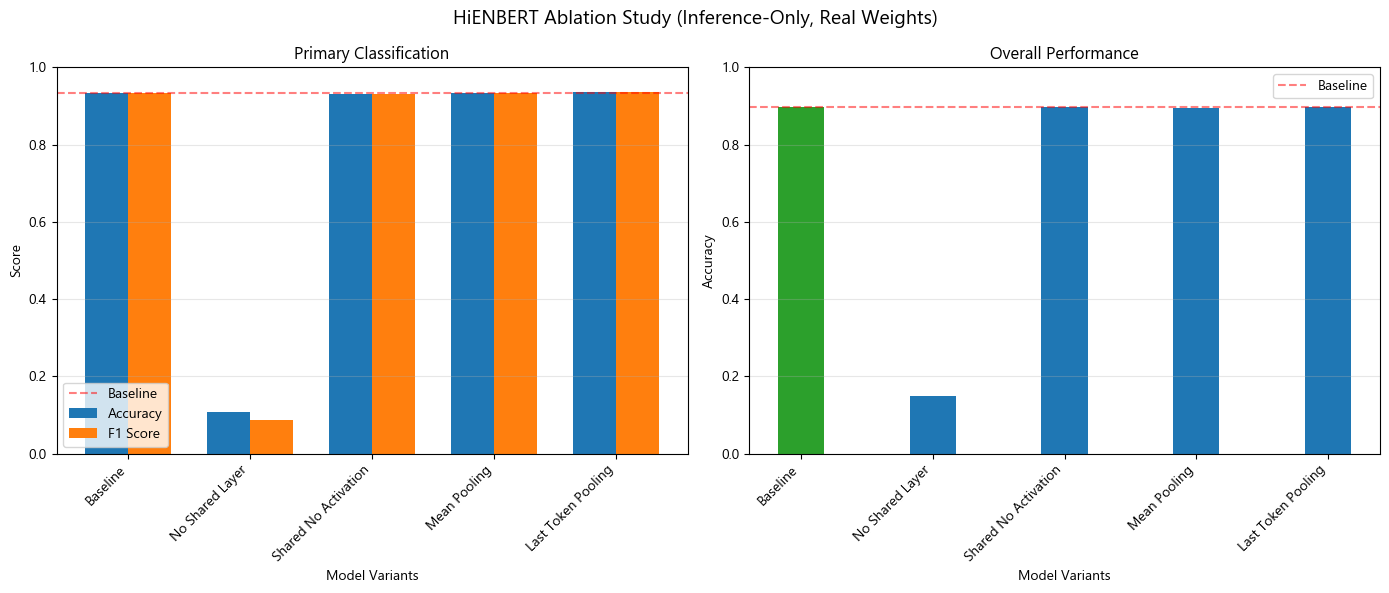


ABLATION STUDY REPORT

Baseline (Original Model):
  Primary Accuracy: 0.9328
  Primary F1: 0.9328
  Severity Accuracy: 0.8943
  Overall Accuracy: 0.8980

--------------------------------------------------------------------------------
Ablation Results (Change from Baseline):
--------------------------------------------------------------------------------

NO SHARED LAYER:
  Primary Acc: 0.1080 (-0.8248) ✗ DEGRADED
  Overall Acc: 0.1495 (-0.7485)

SHARED NO ACTIVATION:
  Primary Acc: 0.9312 (-0.0016) ✗ DEGRADED
  Overall Acc: 0.8964 (-0.0016)

MEAN POOLING:
  Primary Acc: 0.9335 (+0.0007) ✓ IMPROVED
  Overall Acc: 0.8958 (-0.0022)

LAST TOKEN POOLING:
  Primary Acc: 0.9351 (+0.0023) ✓ IMPROVED
  Overall Acc: 0.8972 (-0.0008)

✓ Results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results/correct_ablation_results.json

✓ Ablation study completed successfully!


In [28]:
# ============================================================================
# CELL 15 (CORRECTED): ABLATION STUDY FOR OptimizedHiEnBERT
# ============================================================================
#
# WHY THIS VERSION IS DIFFERENT FROM YOUR ORIGINAL CELL 15:
#
# Your trained model (see Cell 6 / the model-loading cell) is:
#   cls = base(...).last_hidden_state[:, 0, :]
#   x   = gelu(shared(cls))     <-- self.shared: nn.Linear(hidden, hidden)
#   x   = dropout(x)
#   return fc_primary(x), fc_subcat(x), fc_severity(x)
#
# None of the old variants referenced `self.shared` at all, so
# "no_shared_layer" / "no_dropout" / "higher_dropout" / "no_attention"
# were all silently the SAME architecture (cls -> dropout -> heads) with
# no shared layer in any of them.
#
# Separately, `evaluate_model()` calls `model.eval()`, and in eval mode
# nn.Dropout is a no-op. That means:
#   - no_dropout / higher_dropout can NEVER differ from baseline at
#     inference time (dropout only acts during training) -> removed.
#   - frozen_bert (requires_grad=False) never differs from baseline either,
#     since nothing calls .backward() in an eval-only study -> removed.
#   - deeper_shared inserted two brand-new nn.Linear layers with random
#     (untrained) weights and evaluated them immediately. That measures
#     "how bad random weights are," not whether a deeper shared block
#     would help -> removed (needs an actual training loop; see note below).
#
# What's left below are ablations that (a) reuse the real trained weights,
# (b) actually change the forward pass at inference time, and therefore
# (c) produce numbers that mean something without retraining anything.
#
# If you *do* want to test "would a deeper shared block help" or "does
# freezing BERT during fine-tuning change generalization," those require
# a short training loop per variant, not a pure eval-time ablation -- flag
# me if you want that added as a separate cell.
# ============================================================================

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


# ============================================================================
# ABLATION STUDY
# ============================================================================

class CorrectAblationStudy:
    """
    Eval-time-only ablation study for OptimizedHiEnBERT.

    Every variant reuses the trained self.base / self.shared / self.fc_*
    modules by reference (no deepcopy needed -- we never call .backward()
    or an optimizer on these variants, so sharing parameters is safe and
    avoids duplicating a full XLM-R encoder in memory per variant). Each
    variant only rewires the forward pass.
    """

    def __init__(self, trained_model, tokenizer, test_df, device):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}

        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Has Subcategory labels: {self.has_subcat}")
        print(f"  Has Severity labels: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description=""):
        """Evaluate a variant and return primary/subcat/severity/overall metrics."""
        model.eval()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }

        task_accs = [metrics['primary_accuracy']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        return metrics

    # ========================================================================
    # VARIANTS -- each reuses trained weights, each changes a real forward path
    # ========================================================================

    def create_variant_baseline(self):
        """Trained model, untouched."""
        return self.trained_model

    def create_variant_no_shared_layer(self):
        """
        Skip self.shared + self.gelu entirely; feed the raw CLS embedding
        straight into the (trained) classification heads.
        Tests how much the shared projection contributes, since the heads
        were trained on shared(cls) representations, not raw cls.
        """
        base, dropout = self.base, self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class NoSharedLayer(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)  # dropout is a no-op in eval() anyway
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return NoSharedLayer()

    def create_variant_shared_no_activation(self):
        """
        Keep the trained self.shared Linear layer, but drop the GELU
        nonlinearity after it. Uses the real trained shared-layer weights,
        just tests whether the nonlinearity itself matters.
        """
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedNoActivation(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)          # linear only, no GELU
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedNoActivation()

    def create_variant_mean_pooling(self):
        """
        Replace CLS-token pooling with attention-mask-weighted mean pooling
        over all tokens, then run through the trained shared -> gelu ->
        dropout -> heads pipeline as usual.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class MeanPooling(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                hidden_states = outputs.last_hidden_state
                mask = attention_mask.unsqueeze(-1).float()
                pooled = torch.sum(hidden_states * mask, dim=1) / torch.clamp(
                    mask.sum(dim=1), min=1e-9
                )
                x = gelu(shared(pooled))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return MeanPooling()

    def create_variant_last_token_pooling(self):
        """
        Use the last non-padded token's hidden state instead of the CLS
        token, run through the same trained shared -> gelu -> dropout ->
        heads pipeline. Tests sensitivity to which position is treated as
        the "summary" representation.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class LastTokenPooling(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                hidden_states = outputs.last_hidden_state
                seq_lengths = attention_mask.sum(dim=1) - 1  # index of last real token
                seq_lengths = seq_lengths.clamp(min=0)
                batch_idx = torch.arange(hidden_states.size(0), device=hidden_states.device)
                pooled = hidden_states[batch_idx, seq_lengths]
                x = gelu(shared(pooled))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return LastTokenPooling()

    # ========================================================================
    # RUN
    # ========================================================================

    def run_study(self):
        print("\n" + "=" * 80)
        print("ABLATION STUDY (INFERENCE-ONLY, REAL TRAINED WEIGHTS)")
        print("=" * 80)

        variants = {
            'baseline': self.create_variant_baseline,
            'no_shared_layer': self.create_variant_no_shared_layer,
            'shared_no_activation': self.create_variant_shared_no_activation,
            'mean_pooling': self.create_variant_mean_pooling,
            'last_token_pooling': self.create_variant_last_token_pooling,
        }

        for name, builder in variants.items():
            print(f"\n{'=' * 60}\nEvaluating: {name.upper()}\n{'=' * 60}")
            try:
                variant_model = builder().to(self.device)
                variant_model.eval()

                metrics = self.evaluate_model(variant_model, name)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  \u2717 Failed: {e}")
                import traceback
                traceback.print_exc()

        return self.results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        if not self.results:
            print("No results to visualize")
            return

        variants = list(self.results.keys())
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width / 2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width / 2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(
            y=self.results['baseline']['primary_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(
            y=self.results['baseline']['overall_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('HiENBERT Ablation Study (Inference-Only, Real Weights)', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"\u2713 Visualization saved to: {save_path}")

        plt.show()
        plt.close()

    def generate_report(self):
        print("\n" + "=" * 80)
        print("ABLATION STUDY REPORT")
        print("=" * 80)

        if not self.results:
            print("No results available!")
            return

        baseline = self.results.get('baseline', {})
        print("\nBaseline (Original Model):")
        print(f"  Primary Accuracy: {baseline.get('primary_accuracy', 0):.4f}")
        print(f"  Primary F1: {baseline.get('primary_f1_weighted', 0):.4f}")
        if 'severity_accuracy' in baseline:
            print(f"  Severity Accuracy: {baseline.get('severity_accuracy', 0):.4f}")
        print(f"  Overall Accuracy: {baseline.get('overall_accuracy', 0):.4f}")

        print("\n" + "-" * 80)
        print("Ablation Results (Change from Baseline):")
        print("-" * 80)

        for name, metrics in self.results.items():
            if name == 'baseline':
                continue

            primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
            overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)

            if primary_change > 1e-9:
                status = "\u2713 IMPROVED"
            elif primary_change < -1e-9:
                status = "\u2717 DEGRADED"
            else:
                status = "="

            print(f"\n{name.upper().replace('_', ' ')}:")
            print(f"  Primary Acc: {metrics.get('primary_accuracy', 0):.4f} ({primary_change:+.4f}) {status}")
            print(f"  Overall Acc: {metrics.get('overall_accuracy', 0):.4f} ({overall_change:+.4f})")


# ============================================================================
# RUN
# ============================================================================

print("\n" + "=" * 80)
print("STARTING ABLATION STUDY")
print("=" * 80)

try:
    correct_ablation = CorrectAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE
    )

    ablation_results = correct_ablation.run_study()

    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    correct_ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/correct_ablation_study.png"
    )

    correct_ablation.generate_report()

    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    clean_results = {
        k: {kk: (float(vv) if isinstance(vv, (np.float32, np.float64)) else vv) for kk, vv in v.items()}
        for k, v in ablation_results.items()
    }
    with open(f"{Config.RESULTS_DIR}/correct_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n\u2713 Results saved to: {Config.RESULTS_DIR}/correct_ablation_results.json")
    print("\n\u2713 Ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()


STARTING LAYER-SCOPED ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Encoder layers (self.base): 12
  Has Subcategory labels: True
  Has Severity labels: True

LAYER-SCOPED ABLATION STUDY (real submodules only)

Evaluating: BASELINE


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SHARED_BYPASSED


  Primary Accuracy: 0.1047
  Primary F1: 0.0860
  Subcat Accuracy: 0.0375
  Severity Accuracy: 0.3047
  Overall Accuracy: 0.1490

Evaluating: GELU_REMOVED


  Primary Accuracy: 0.9335
  Primary F1: 0.9334
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8959
  Overall Accuracy: 0.8972

Evaluating: SHARED_REINITIALIZED


  Primary Accuracy: 0.2042
  Primary F1: 0.1837
  Subcat Accuracy: 0.0310
  Severity Accuracy: 0.2708
  Overall Accuracy: 0.1686

Evaluating: FC_PRIMARY_REINITIALIZED


  Primary Accuracy: 0.0807
  Primary F1: 0.0826
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.6137

Evaluating: FC_SUBCAT_REINITIALIZED


... (2 outputs left out)

  Primary Accuracy: 0.9298
  Primary F1: 0.9298
  Subcat Accuracy: 0.8610
  Severity Accuracy: 0.8966
  Overall Accuracy: 0.8958

Evaluating: ENCODER_DEPTH_25PCT_L3


  Primary Accuracy: 0.1215
  Primary F1: 0.0969
  Subcat Accuracy: 0.0399
  Severity Accuracy: 0.3903
  Overall Accuracy: 0.1839

Evaluating: ENCODER_DEPTH_50PCT_L6


  Primary Accuracy: 0.1212
  Primary F1: 0.0968
  Subcat Accuracy: 0.0425
  Severity Accuracy: 0.3943
  Overall Accuracy: 0.1860

Evaluating: ENCODER_DEPTH_75PCT_L9


  Primary Accuracy: 0.1459
  Primary F1: 0.0831
  Subcat Accuracy: 0.0474
  Severity Accuracy: 0.3847
  Overall Accuracy: 0.1927
✓ Visualization saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/layer_ablation_study.png


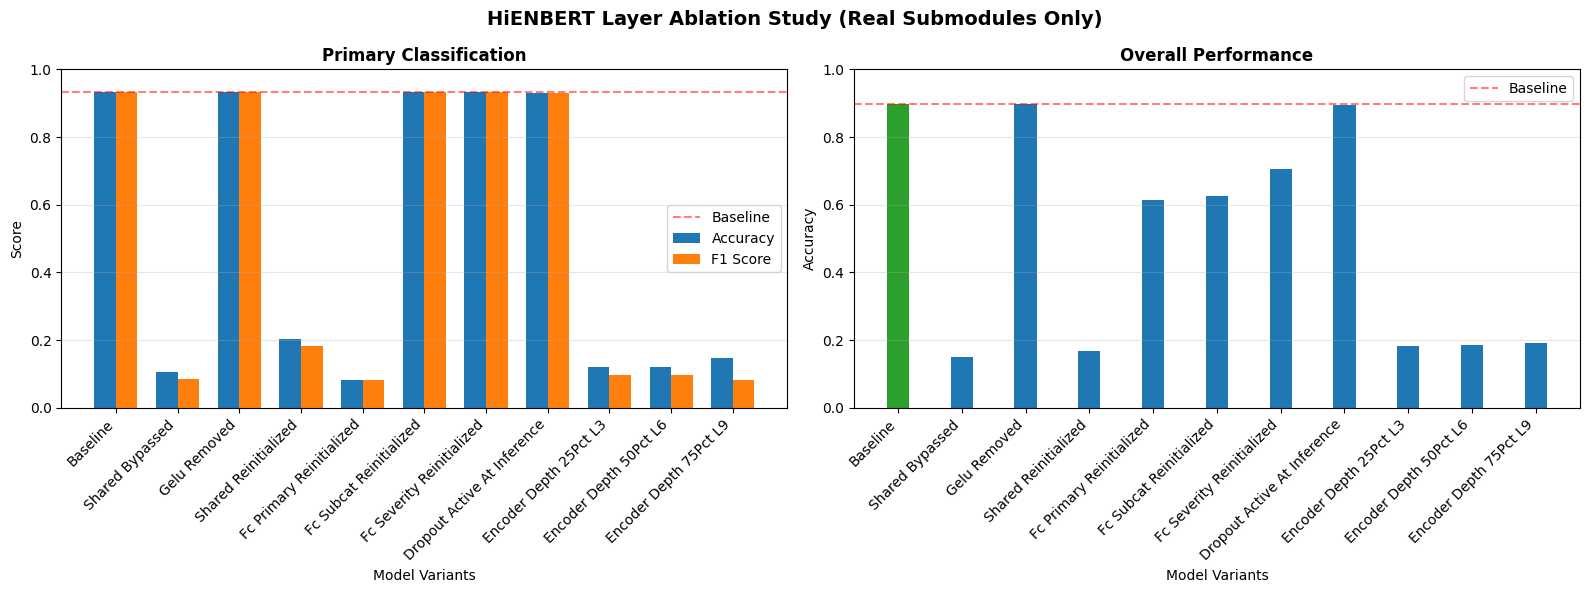


ABLATION STUDY REPORT

Baseline (Original Trained Model):
  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

--------------------------------------------------------------------------------
Ablation Results (Change from Baseline):
--------------------------------------------------------------------------------

SHARED BYPASSED:
  Primary Acc: 0.1047 (-0.8271) ✗ DEGRADED
  Overall Acc: 0.1490 (-0.7485)

GELU REMOVED:
  Primary Acc: 0.9335 (+0.0016) ✓ IMPROVED
  Overall Acc: 0.8972 (-0.0002)

SHARED REINITIALIZED:
  Primary Acc: 0.2042 (-0.7276) ✗ DEGRADED
  Overall Acc: 0.1686 (-0.7288)

FC PRIMARY REINITIALIZED:
  Primary Acc: 0.0807 (-0.8511) ✗ DEGRADED
  Overall Acc: 0.6137 (-0.2837)

FC SUBCAT REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.6256 (-0.2718)

FC SEVERITY REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.7051 (-0.1924)

DROPOUT ACTIVE AT INFERENCE:
  Primary Acc: 0.9298 (-0.0020) ✗ D

In [11]:
# ============================================================================
# CELL 15 (LAYER-SCOPED): ABLATION STUDY FOR OptimizedHiEnBERT
# ============================================================================
#
# Your trained model (Cell 6 / model-loading cell) is:
#
#   cls = base(...).last_hidden_state[:, 0, :]     <-- self.base: XLM-R encoder
#   x   = gelu(shared(cls))                        <-- self.shared: Linear(h,h)
#                                                       self.gelu:   GELU
#   x   = dropout(x)                                <-- self.dropout: Dropout(0.2)
#   return fc_primary(x), fc_subcat(x), fc_severity(x)   <-- 3 Linear heads
#
# This version only touches modules that actually exist in that graph:
# self.base, self.shared, self.gelu, self.dropout, self.fc_primary,
# self.fc_subcat, self.fc_severity. (An earlier draft tested substitute
# pooling strategies -- mean/max pooling, token shuffling -- that aren't
# part of the trained architecture at all; those are removed here.)
#
# Two distinct, legitimate senses of "ablation" are used, per layer:
#
#   BYPASS   -- skip the layer in the forward pass entirely.
#               Answers: "does this transformation step need to exist?"
#   KNOCKOUT -- keep the layer in the graph, same shape, but replace its
#               weights with a fresh random init (Xavier, matching your
#               model's own _init_weights).
#               Answers: "does the *trained content* of this layer matter,
#               or would any layer of that shape do?"
#
# Both are pure inference-time swaps -- no retraining, no .backward() calls
# -- so every number below is directly comparable to baseline.
#
# self.dropout deserves a special note: at eval() (which every variant runs
# under), nn.Dropout is a no-op by definition -- it literally cannot affect
# the output unless you deliberately force that one submodule back into
# train() mode while everything else stays in eval(). That's exactly what
# `dropout_active_at_inference` below does; without that trick, "ablating
# dropout" is guaranteed to equal baseline and isn't a real test.
#
# self.base is not knocked out or bypassed (it's the only source of
# information about the text -- there's nothing to compare it against).
# Instead it's probed by DEPTH: since it's a stack of transformer layers,
# `encoder_depth_*pct` variants read the CLS representation from an earlier
# layer instead of the final one, which is a genuine ablation of "how many
# of the encoder's own layers are actually needed."
# ============================================================================

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


def _fresh_linear(in_features, out_features):
    """A new Linear layer, Xavier-initialized like OptimizedHiEnBERT._init_weights."""
    layer = nn.Linear(in_features, out_features)
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


# ============================================================================
# ABLATION STUDY
# ============================================================================

class LayerAblationStudy:
    """
    Ablates only the real submodules of OptimizedHiEnBERT: base, shared,
    gelu, dropout, fc_primary, fc_subcat, fc_severity. All trained modules
    are reused by reference (no deepcopy -- nothing here calls .backward(),
    so sharing parameters across variants is safe and avoids duplicating a
    full XLM-R encoder per variant).
    """

    def __init__(self, trained_model, tokenizer, test_df, device):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}

        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.num_encoder_layers = getattr(self.base.config, 'num_hidden_layers', None)

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Encoder layers (self.base): {self.num_encoder_layers}")
        print(f"  Has Subcategory labels: {self.has_subcat}")
        print(f"  Has Severity labels: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description="", force_dropout_train=False):
        """
        Evaluate a variant. force_dropout_train=True keeps every submodule
        in eval() EXCEPT model.dropout, which is pushed back into train()
        so it actually applies at inference (see module docstring above).
        """
        model.eval()
        if force_dropout_train:
            model.dropout.train()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }
        task_accs = [metrics['primary_accuracy']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        return metrics

    # ========================================================================
    # BYPASS VARIANTS -- skip a real layer's transformation entirely
    # ========================================================================

    def create_variant_shared_bypassed(self):
        """Skip self.shared + self.gelu; raw CLS goes straight into the trained heads."""
        base = self.base
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedBypassed(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedBypassed()

    def create_variant_gelu_removed(self):
        """Keep the trained self.shared Linear, drop the self.gelu nonlinearity."""
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class GeluRemoved(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)  # linear only, no GELU
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return GeluRemoved()

    # ========================================================================
    # KNOCKOUT VARIANTS -- keep the layer, randomize its trained weights
    # ========================================================================

    def create_variant_shared_reinitialized(self):
        """self.shared's trained weights replaced with a fresh random Linear."""
        base = self.base
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity
        new_shared = _fresh_linear(self.hidden_size, self.hidden_size)

        class SharedReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.shared = new_shared  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(self.shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedReinitialized()

    def _create_head_reinitialized(self, head_name, out_features):
        """Generic knockout for one of the three trained classification heads."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        trained_fc_primary = self.trained_model.fc_primary
        trained_fc_subcat = self.trained_model.fc_subcat
        trained_fc_severity = self.trained_model.fc_severity
        new_head = _fresh_linear(self.hidden_size, out_features)

        class HeadReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.reinit_head = new_head  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                p1 = self.reinit_head(x) if head_name == 'fc_primary' else trained_fc_primary(x)
                p2 = self.reinit_head(x) if head_name == 'fc_subcat' else trained_fc_subcat(x)
                p3 = self.reinit_head(x) if head_name == 'fc_severity' else trained_fc_severity(x)
                return p1, p2, p3

        return HeadReinitialized()

    def create_variant_fc_primary_reinitialized(self):
        """Trained fc_primary head replaced with random weights (fc_subcat/severity untouched)."""
        return self._create_head_reinitialized('fc_primary', self.n_primary)

    def create_variant_fc_subcat_reinitialized(self):
        """Trained fc_subcat head replaced with random weights (fc_primary/severity untouched)."""
        return self._create_head_reinitialized('fc_subcat', self.n_subcat)

    def create_variant_fc_severity_reinitialized(self):
        """Trained fc_severity head replaced with random weights (fc_primary/subcat untouched)."""
        return self._create_head_reinitialized('fc_severity', self.n_severity)

    # ========================================================================
    # DROPOUT -- the only way to actually exercise self.dropout at eval time
    # ========================================================================

    def create_variant_dropout_active(self):
        """
        Same trained self.dropout module (p=0.2), but forced into train()
        mode via evaluate_model(force_dropout_train=True) so it's actually
        stochastic instead of a no-op. Note: this makes the forward pass
        non-deterministic, so re-running it will give slightly different
        numbers each time -- that's expected, not a bug.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class DropoutActive(nn.Module):
            def __init__(self):
                super().__init__()
                self.dropout = dropout  # exposed as self.dropout so evaluate_model can .train() it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = self.dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return DropoutActive()

    # ========================================================================
    # ENCODER DEPTH -- probing self.base's own stacked layers
    # ========================================================================

    def create_variant_encoder_depth(self, layer_idx):
        """
        Use the CLS token from an intermediate encoder layer (layer_idx,
        via output_hidden_states) instead of the final layer, through the
        same trained shared -> gelu -> dropout -> heads pipeline. Those
        downstream layers were trained on the FINAL layer's representation,
        so this is deliberately out-of-distribution -- it measures how much
        representational work the later encoder layers are doing.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class EncoderDepthProbe(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    output_hidden_states=True,
                )
                cls = outputs.hidden_states[layer_idx][:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return EncoderDepthProbe()

    # ========================================================================
    # RUN
    # ========================================================================

    def run_study(self):
        print("\n" + "=" * 80)
        print("LAYER-SCOPED ABLATION STUDY (real submodules only)")
        print("=" * 80)

        variants = {
            'baseline': (self.trained_model, {}),
            'shared_bypassed': (self.create_variant_shared_bypassed(), {}),
            'gelu_removed': (self.create_variant_gelu_removed(), {}),
            'shared_reinitialized': (self.create_variant_shared_reinitialized(), {}),
            'fc_primary_reinitialized': (self.create_variant_fc_primary_reinitialized(), {}),
            'fc_subcat_reinitialized': (self.create_variant_fc_subcat_reinitialized(), {}),
            'fc_severity_reinitialized': (self.create_variant_fc_severity_reinitialized(), {}),
            'dropout_active_at_inference': (
                self.create_variant_dropout_active(), {'force_dropout_train': True}
            ),
        }

        # Encoder-depth probes: 25% / 50% / 75% through self.base's own layers.
        # (100% depth == last_hidden_state == identical to baseline, so it's
        # not included as a separate variant.)
        if self.num_encoder_layers:
            for frac in (0.25, 0.5, 0.75):
                layer_idx = max(1, round(self.num_encoder_layers * frac))
                name = f'encoder_depth_{int(frac * 100)}pct_L{layer_idx}'
                variants[name] = (self.create_variant_encoder_depth(layer_idx), {})
        else:
            print("  (Skipping encoder-depth probes: base_model.config.num_hidden_layers not found)")

        for name, (variant_model, eval_kwargs) in variants.items():
            print(f"\n{'=' * 60}\nEvaluating: {name.upper()}\n{'=' * 60}")
            try:
                variant_model = variant_model.to(self.device)

                metrics = self.evaluate_model(variant_model, name, **eval_kwargs)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  \u2717 Failed: {e}")
                import traceback
                traceback.print_exc()

        return self.results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        if not self.results:
            print("No results to visualize")
            return

        variants = list(self.results.keys())
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width / 2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width / 2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(
            y=self.results['baseline']['primary_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(
            y=self.results['baseline']['overall_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('HiENBERT Layer Ablation Study (Real Submodules Only)', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"\u2713 Visualization saved to: {save_path}")

        plt.show()
        plt.close()

    def generate_report(self):
        print("\n" + "=" * 80)
        print("ABLATION STUDY REPORT")
        print("=" * 80)

        if not self.results:
            print("No results available!")
            return

        baseline = self.results.get('baseline', {})
        print("\nBaseline (Original Trained Model):")
        print(f"  Primary Accuracy: {baseline.get('primary_accuracy', 0):.4f}")
        print(f"  Primary F1: {baseline.get('primary_f1_weighted', 0):.4f}")
        if 'severity_accuracy' in baseline:
            print(f"  Severity Accuracy: {baseline.get('severity_accuracy', 0):.4f}")
        print(f"  Overall Accuracy: {baseline.get('overall_accuracy', 0):.4f}")

        print("\n" + "-" * 80)
        print("Ablation Results (Change from Baseline):")
        print("-" * 80)

        for name, metrics in self.results.items():
            if name == 'baseline':
                continue

            primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
            overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)

            if primary_change > 1e-9:
                status = "\u2713 IMPROVED"
            elif primary_change < -1e-9:
                status = "\u2717 DEGRADED"
            else:
                status = "="

            print(f"\n{name.upper().replace('_', ' ')}:")
            print(f"  Primary Acc: {metrics.get('primary_accuracy', 0):.4f} ({primary_change:+.4f}) {status}")
            print(f"  Overall Acc: {metrics.get('overall_accuracy', 0):.4f} ({overall_change:+.4f})")


# ============================================================================
# RUN
# ============================================================================

print("\n" + "=" * 80)
print("STARTING LAYER-SCOPED ABLATION STUDY")
print("=" * 80)

try:
    ablation = LayerAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE
    )

    ablation_results = ablation.run_study()

    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/layer_ablation_study.png"
    )

    ablation.generate_report()

    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    clean_results = {
        k: {kk: (float(vv) if isinstance(vv, (np.float32, np.float64)) else vv) for kk, vv in v.items()}
        for k, v in ablation_results.items()
    }
    with open(f"{Config.RESULTS_DIR}/layer_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n\u2713 Results saved to: {Config.RESULTS_DIR}/layer_ablation_results.json")
    print("\n\u2713 Ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [19]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # # 3. Imbalance Handling
    # print("\n3. IMBALANCE HANDLING:")
    # print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    # print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    # if Config.USE_FOCAL_LOSS:
    #     print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
    #     print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    # print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (XLM-ROBERTA Base)

1. DATASET STATISTICS:
   Training samples: 14165
   Validation samples: 3035
   Test samples: 3036
   Primary categories: 8
   Subcategories: 24
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: XLM-ROBERTA
   Model Path: xlm-roberta-base
   Hidden Size: 768
   Total Parameters: 278,661,155
   Dropout Rate: 0.3
   Max Sequence Length: 128

4. TRAINING DETAILS:
   Epochs: 15
   Batch Size: 32
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.9328
   balanced_accuracy: 0.9357
   f1_macro: 0.9342
   f1_weighted: 0.9328
   precision: 0.9332
   recall: 0.9328
   cohen_kappa: 0.9224
   mcc: 0.9225

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.9357
   Best Validation Balanced Accuracy: 0.9378

7. TRAINING HISTORY:
   Final Train Loss: 0.0912
   Final Train Accuracy: 0.9954
   Final Train Balanced Accuracy: 0.9954

8. SEVERITY DISTRIBUTION (Training):

LOADING SAVED HIENBERT MODEL AND DATA

1. Loading tokenizer and base model...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12435.07it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



2. Loading datasets...
   Train: 14165, Dev: 3035, Test: 3036

3. Preprocessing data...
   After preprocessing - Train: 14165, Dev: 3035, Test: 3036

4. Loading saved model...
   ✅ Model loaded successfully!
   Best Validation F1: 0.9357
   Best Validation Balanced Accuracy: 0.9378

5. Creating dataloaders...
   Test batches: 48

6. Running evaluation...


Evaluating: 100%|██████████| 48/48 [02:49<00:00,  3.52s/it]



1. PRIMARY CATEGORY PERFORMANCE BY LANGUAGE

Language-wise Primary Category Performance:
----------------------------------------------------------------------
Language     Samples    Accuracy     F1-Macro     F1-Weighted 
----------------------------------------------------------------------
English      3036       0.9328     0.9342     0.9328
Hindi        3036       0.9328     0.9342     0.9328
Hinglish     3036       0.9328     0.9342     0.9328

2. PRIMARY CATEGORY PERFORMANCE BY CATEGORY

Per-Category Performance (Primary):
--------------------------------------------------------------------------------
Category             Precision    Recall       F1-Score     Support   
--------------------------------------------------------------------------------
Electricity          0.9677     0.9534     0.9605     408.0     
Encroachment & Illegal Construction 0.9581     0.9643     0.9612     308.0     
Health & Sanitation  0.8632     0.9342     0.8973     304.0     
Others               

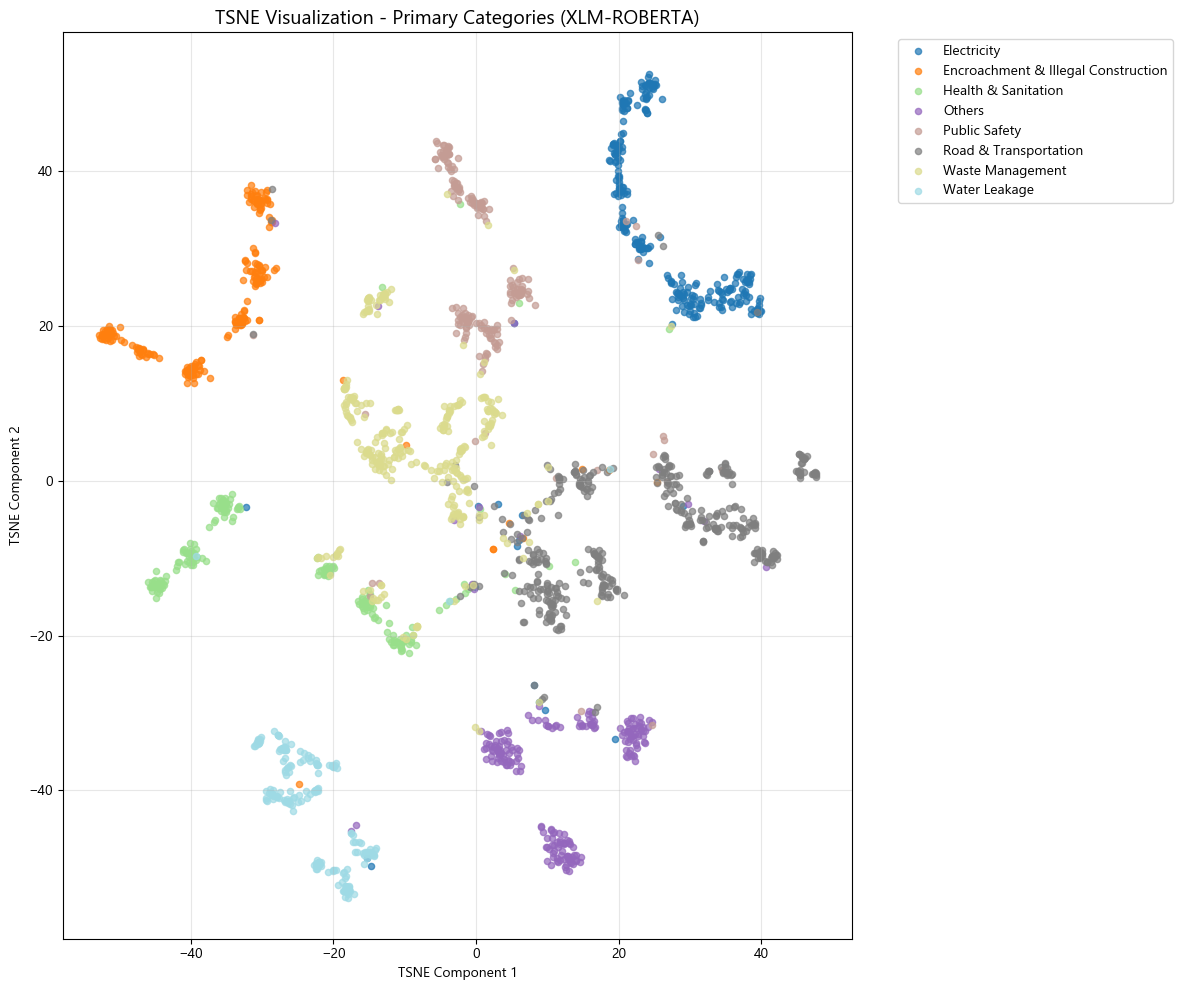


Generating TSNE for Severity Levels...
   Reducing dimensions with PCA...
   Running TSNE...
   Saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/tsne_severity_levels.png


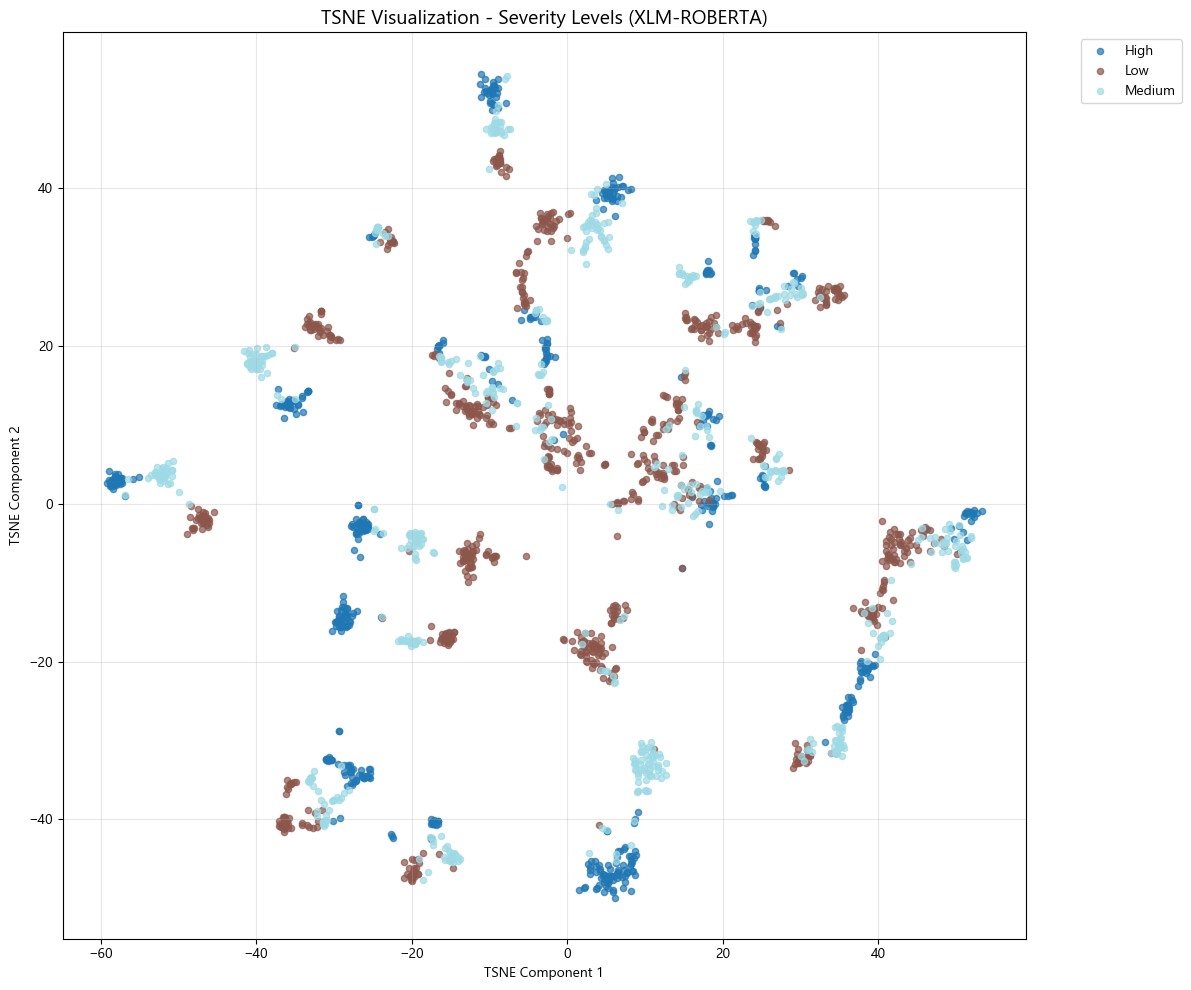


6. CONFUSION MATRICES
   Saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/confusion_matrix_primary.png


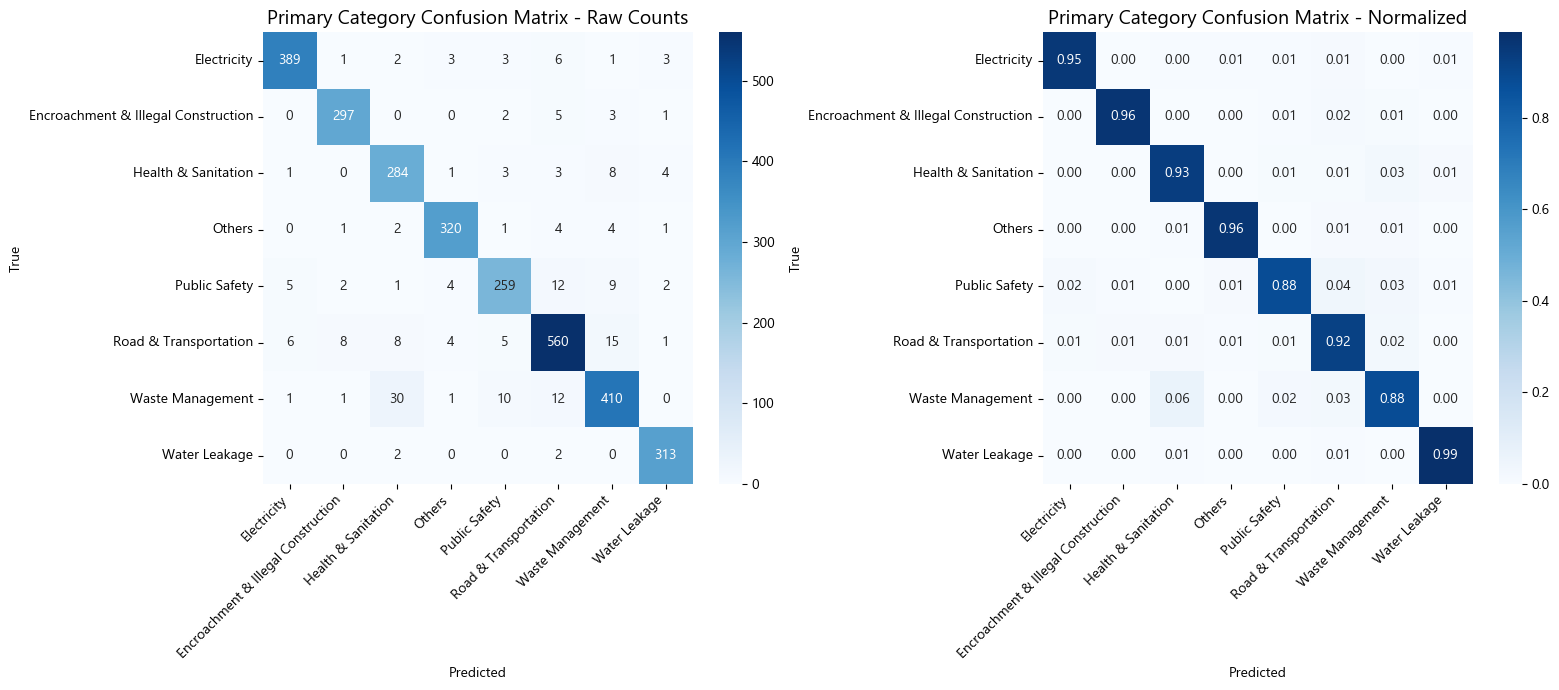

   Saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/confusion_matrix_severity.png


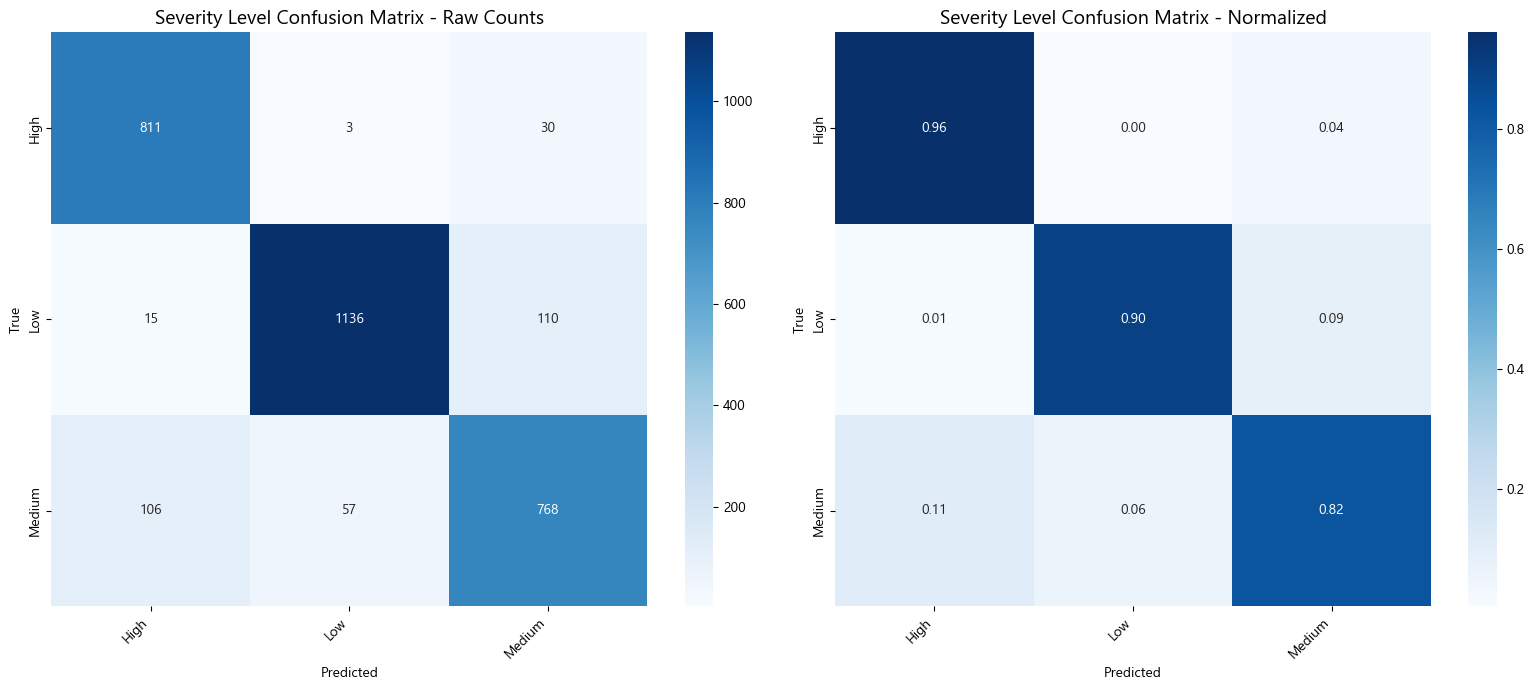


7. SAVING RESULTS
   ✅ Results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results/evaluation_results.json
   ✅ Predictions saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results/predictions.csv

FINAL SUMMARY

┌─────────────────────────────────────────────────────────────────────────────┐
│                          HIENBERT EVALUATION SUMMARY                        │
├─────────────────────────────────────────────────────────────────────────────┤
│  PRIMARY CATEGORY:                                                         │
│    Accuracy:        0.9328                           │
│    F1-Macro:        0.9342                           │
│    F1-Weighted:     0.9328                           │
├─────────────────────────────────────────────────────────────────────────────┤
│  SUBCATEGORY:                                                              │
│    F1-Macro:        0.8529                           │
│

In [ ]:
# ============================================================================
# LOAD SAVED HIENBERT MODEL AND GENERATE RESULTS
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import json
import pickle
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# ============================================================================
# CONFIGURATION - MATCH YOUR TRAINING SETUP
# ============================================================================

class Config:
    # Base Model
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # Project directories
    PROJECT_DIR = os.getcwd()
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # Output directories
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    
    # Model parameters
    MAX_LENGTH = 128
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    HF_TOKEN = os.getenv("HF_TOKEN")

# ============================================================================
# MODEL DEFINITION (Match your training architecture)
# ============================================================================

class OptimizedHiEnBERT(nn.Module):
    """Optimized HiENBERT model with efficient architecture"""
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        # Single shared layer for efficiency
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        # Shared representation
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

# ============================================================================
# DATASET CLASS
# ============================================================================

class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }

# ============================================================================
# DATA PREPROCESSING
# ============================================================================

class Preprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df

# ============================================================================
# LOAD SAVED MODEL AND DATA
# ============================================================================

print("="*80)
print("LOADING SAVED HIENBERT MODEL AND DATA")
print("="*80)

# 1. Load tokenizer and base model
print("\n1. Loading tokenizer and base model...")
tokenizer = AutoTokenizer.from_pretrained(
    Config.XLMBERT_PATH,
    token=Config.HF_TOKEN,
    use_fast=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModel.from_pretrained(
    Config.XLMBERT_PATH,
    token=Config.HF_TOKEN
)

# 2. Load data
print("\n2. Loading datasets...")
train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df = pd.read_csv(Config.DEV_PATH)
test_df = pd.read_csv(Config.TEST_PATH)
print(f"   Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# 3. Preprocess data
print("\n3. Preprocessing data...")
preprocessor = Preprocessor()
train_df = preprocessor.preprocess_text(train_df)
dev_df = preprocessor.preprocess_text(dev_df)
test_df = preprocessor.preprocess_text(test_df)
train_df, dev_df, test_df = preprocessor.prepare_labels(train_df, dev_df, test_df)
print(f"   After preprocessing - Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# 4. Load saved model
print("\n4. Loading saved model...")
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"

if not os.path.exists(checkpoint_path):
    print(f"   ERROR: Checkpoint not found at {checkpoint_path}")
    print("   Please ensure you have trained the model first.")
    sys.exit(1)

checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)

# Create model with proper dimensions
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = OptimizedHiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=0.2
).to(Config.DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"   ✅ Model loaded successfully!")
print(f"   Best Validation F1: {checkpoint['val_f1']:.4f}")
print(f"   Best Validation Balanced Accuracy: {checkpoint['val_balanced_acc']:.4f}")

# ============================================================================
# CREATE DATALOADERS
# ============================================================================

print("\n5. Creating dataloaders...")

def create_dataloaders(df, tokenizer, batch_size=64, shuffle=False):
    dataset = ComplaintDataset(df, tokenizer, Config.MAX_LENGTH)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=True
    )

test_loader = create_dataloaders(test_df, tokenizer, batch_size=64, shuffle=False)
print(f"   Test batches: {len(test_loader)}")

# ============================================================================
# EVALUATION FUNCTION
# ============================================================================

def evaluate_model(model, dataloader, device):
    """Evaluate model and return predictions and embeddings"""
    model.eval()
    all_primary_preds = []
    all_primary_labels = []
    all_subcat_preds = []
    all_subcat_labels = []
    all_severity_preds = []
    all_severity_labels = []
    all_embeddings = []
    all_texts = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating'):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            
            # Primary
            preds1 = torch.argmax(p1, dim=1)
            all_primary_preds.extend(preds1.cpu().numpy())
            all_primary_labels.extend(batch['primary'].cpu().numpy())
            
            # Subcategory
            preds2 = torch.argmax(p2, dim=1)
            all_subcat_preds.extend(preds2.cpu().numpy())
            all_subcat_labels.extend(batch['subcat'].cpu().numpy())
            
            # Severity
            preds3 = torch.argmax(p3, dim=1)
            all_severity_preds.extend(preds3.cpu().numpy())
            all_severity_labels.extend(batch['severity'].cpu().numpy())
            
            # Embeddings for TSNE
            embeddings = model.get_embeddings(input_ids, attention_mask)
            all_embeddings.extend(embeddings.cpu().numpy())
    
    return {
        'primary_preds': np.array(all_primary_preds),
        'primary_labels': np.array(all_primary_labels),
        'subcat_preds': np.array(all_subcat_preds),
        'subcat_labels': np.array(all_subcat_labels),
        'severity_preds': np.array(all_severity_preds),
        'severity_labels': np.array(all_severity_labels),
        'embeddings': np.array(all_embeddings)
    }

# ============================================================================
# RUN EVALUATION
# ============================================================================

print("\n6. Running evaluation...")
results = evaluate_model(model, test_loader, Config.DEVICE)

# ============================================================================
# 1. PRIMARY CATEGORY PERFORMANCE BY LANGUAGE
# ============================================================================

print("\n" + "="*80)
print("1. PRIMARY CATEGORY PERFORMANCE BY LANGUAGE")
print("="*80)

# Get language-specific data
def get_language_performance(df, preds, labels, lang_col):
    """Get performance metrics for a specific language"""
    # Get indices for this language
    lang_indices = df[df[lang_col].notna() & (df[lang_col] != '')].index
    if len(lang_indices) == 0:
        return None
    
    lang_preds = preds[lang_indices]
    lang_labels = labels[lang_indices]
    
    return {
        'accuracy': accuracy_score(lang_labels, lang_preds),
        'f1_macro': f1_score(lang_labels, lang_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(lang_labels, lang_preds, average='weighted', zero_division=0),
        'samples': len(lang_indices)
    }

# Check each language column
lang_cols = ['text_en', 'Hindi', 'Hinglish']
lang_names = ['English', 'Hindi', 'Hinglish']

print("\nLanguage-wise Primary Category Performance:")
print("-" * 70)
print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<12}")
print("-" * 70)

for lang_col, lang_name in zip(lang_cols, lang_names):
    perf = get_language_performance(
        test_df, 
        results['primary_preds'], 
        results['primary_labels'], 
        lang_col
    )
    if perf:
        print(f"{lang_name:<12} {perf['samples']:<10} {perf['accuracy']:.4f}     {perf['f1_macro']:.4f}     {perf['f1_weighted']:.4f}")
    else:
        print(f"{lang_name:<12} {'N/A':<10} {'N/A':<12} {'N/A':<12} {'N/A':<12}")

# ============================================================================
# 2. PRIMARY CATEGORY PERFORMANCE BY CATEGORY
# ============================================================================

print("\n" + "="*80)
print("2. PRIMARY CATEGORY PERFORMANCE BY CATEGORY")
print("="*80)

primary_class_names = preprocessor.le_primary.classes_
print("\nPer-Category Performance (Primary):")
print("-" * 80)
print(f"{'Category':<20} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
print("-" * 80)

report_primary = classification_report(
    results['primary_labels'],
    results['primary_preds'],
    target_names=primary_class_names,
    output_dict=True,
    zero_division=0
)

for cat in primary_class_names:
    if cat in report_primary:
        print(f"{cat:<20} {report_primary[cat]['precision']:.4f}     {report_primary[cat]['recall']:.4f}     {report_primary[cat]['f1-score']:.4f}     {report_primary[cat]['support']:<10}")

print("-" * 80)
print(f"{'Overall':<20} {report_primary['weighted avg']['precision']:.4f}     {report_primary['weighted avg']['recall']:.4f}     {report_primary['weighted avg']['f1-score']:.4f}     {report_primary['weighted avg']['support']:<10.0f}")

# ============================================================================
# 3. SECONDARY CATEGORY PERFORMANCE
# ============================================================================

print("\n" + "="*80)
print("3. SECONDARY CATEGORY PERFORMANCE")
print("="*80)

subcat_class_names = preprocessor.le_subcat.classes_

# Get top 10 subcategories by frequency
subcat_counts = pd.Series(results['subcat_labels']).value_counts()
top_subcats = subcat_counts.head(10).index

print("\nTop 10 Subcategories Performance:")
print("-" * 80)
print(f"{'Subcategory':<25} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
print("-" * 80)

for idx in top_subcats:
    cat_name = subcat_class_names[idx]
    # Get binary predictions for this class
    true_binary = (results['subcat_labels'] == idx).astype(int)
    pred_binary = (results['subcat_preds'] == idx).astype(int)
    
    precision = precision_score(true_binary, pred_binary, zero_division=0)
    recall = recall_score(true_binary, pred_binary, zero_division=0)
    f1 = f1_score(true_binary, pred_binary, zero_division=0)
    support = true_binary.sum()
    
    print(f"{cat_name[:24]:<25} {precision:.4f}     {recall:.4f}     {f1:.4f}     {support:<10}")

print("-" * 80)
print(f"{'Overall (Macro)':<25} {f1_score(results['subcat_labels'], results['subcat_preds'], average='macro', zero_division=0):.4f}     {'-':<12} {'-':<12} {'-':<10}")
print(f"{'Overall (Weighted)':<25} {f1_score(results['subcat_labels'], results['subcat_preds'], average='weighted', zero_division=0):.4f}     {'-':<12} {'-':<12} {'-':<10}")

# ============================================================================
# 4. OVERALL PERFORMANCE SUMMARY
# ============================================================================

print("\n" + "="*80)
print("4. OVERALL PERFORMANCE SUMMARY")
print("="*80)

print("\nPrimary Category:")
print(f"  Accuracy: {accuracy_score(results['primary_labels'], results['primary_preds']):.4f}")
print(f"  F1-Macro: {f1_score(results['primary_labels'], results['primary_preds'], average='macro', zero_division=0):.4f}")
print(f"  F1-Weighted: {f1_score(results['primary_labels'], results['primary_preds'], average='weighted', zero_division=0):.4f}")

print("\nSubcategory:")
print(f"  F1-Macro: {f1_score(results['subcat_labels'], results['subcat_preds'], average='macro', zero_division=0):.4f}")
print(f"  F1-Weighted: {f1_score(results['subcat_labels'], results['subcat_preds'], average='weighted', zero_division=0):.4f}")

print("\nSeverity:")
print(f"  Accuracy: {accuracy_score(results['severity_labels'], results['severity_preds']):.4f}")
print(f"  F1-Macro: {f1_score(results['severity_labels'], results['severity_preds'], average='macro', zero_division=0):.4f}")
print(f"  F1-Weighted: {f1_score(results['severity_labels'], results['severity_preds'], average='weighted', zero_division=0):.4f}")

# ============================================================================
# 5. TSNE VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("5. TSNE VISUALIZATION")
print("="*80)

def plot_tsne(embeddings, labels, class_names, title, save_path=None, max_samples=2000):
    """Plot TSNE visualization"""
    # Sample if too many points
    if len(embeddings) > max_samples:
        indices = np.random.choice(len(embeddings), max_samples, replace=False)
        embeddings = embeddings[indices]
        labels = labels[indices]
    
    # Reduce dimensions with PCA first for speed
    print(f"   Reducing dimensions with PCA...")
    pca = PCA(n_components=50, random_state=42)
    embeddings_pca = pca.fit_transform(embeddings)
    
    # TSNE
    print(f"   Running TSNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    embeddings_2d = tsne.fit_transform(embeddings_pca)
    
    # Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Get unique labels
    unique_labels = np.unique(labels)
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))
    
    for i, label in enumerate(unique_labels):
        mask = labels == label
        ax.scatter(
            embeddings_2d[mask, 0],
            embeddings_2d[mask, 1],
            c=[colors[i]],
            label=class_names[label] if label < len(class_names) else f'Class {label}',
            alpha=0.7,
            s=20
        )
    
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('TSNE Component 1')
    ax.set_ylabel('TSNE Component 2')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"   Saved to: {save_path}")
    
    plt.show()
    return embeddings_2d

# TSNE for Primary Categories
print("\nGenerating TSNE for Primary Categories...")
tsne_primary = plot_tsne(
    results['embeddings'],
    results['primary_labels'],
    preprocessor.le_primary.classes_,
    f'TSNE Visualization - Primary Categories ({Config.BASE_MODEL.upper()})',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_primary_categories.png"
)

# TSNE for Severity
print("\nGenerating TSNE for Severity Levels...")
tsne_severity = plot_tsne(
    results['embeddings'],
    results['severity_labels'],
    preprocessor.le_severity.classes_,
    f'TSNE Visualization - Severity Levels ({Config.BASE_MODEL.upper()})',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_severity_levels.png"
)

# ============================================================================
# 6. CONFUSION MATRICES
# ============================================================================

print("\n" + "="*80)
print("6. CONFUSION MATRICES")
print("="*80)

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    """Plot confusion matrix"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names, ax=axes[0]
    )
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(
        cm_normalized, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names, ax=axes[1]
    )
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"   Saved to: {save_path}")
    plt.show()

# Primary confusion matrix
plot_confusion_matrix(
    results['primary_labels'],
    results['primary_preds'],
    preprocessor.le_primary.classes_,
    'Primary Category Confusion Matrix',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

# Severity confusion matrix
plot_confusion_matrix(
    results['severity_labels'],
    results['severity_preds'],
    preprocessor.le_severity.classes_,
    'Severity Level Confusion Matrix',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_severity.png"
)

# ============================================================================
# 7. SAVE RESULTS
# ============================================================================

print("\n" + "="*80)
print("7. SAVING RESULTS")
print("="*80)

# Prepare results dictionary
results_summary = {
    'primary': {
        'accuracy': accuracy_score(results['primary_labels'], results['primary_preds']),
        'f1_macro': f1_score(results['primary_labels'], results['primary_preds'], average='macro', zero_division=0),
        'f1_weighted': f1_score(results['primary_labels'], results['primary_preds'], average='weighted', zero_division=0),
        'classification_report': classification_report(
            results['primary_labels'],
            results['primary_preds'],
            target_names=primary_class_names,
            output_dict=True,
            zero_division=0
        )
    },
    'subcategory': {
        'f1_macro': f1_score(results['subcat_labels'], results['subcat_preds'], average='macro', zero_division=0),
        'f1_weighted': f1_score(results['subcat_labels'], results['subcat_preds'], average='weighted', zero_division=0)
    },
    'severity': {
        'accuracy': accuracy_score(results['severity_labels'], results['severity_preds']),
        'f1_macro': f1_score(results['severity_labels'], results['severity_preds'], average='macro', zero_division=0),
        'f1_weighted': f1_score(results['severity_labels'], results['severity_preds'], average='weighted', zero_division=0)
    },
    'language_performance': {}
}

# Add language performance
for lang_col, lang_name in zip(lang_cols, lang_names):
    perf = get_language_performance(
        test_df, 
        results['primary_preds'], 
        results['primary_labels'], 
        lang_col
    )
    if perf:
        results_summary['language_performance'][lang_name] = perf

# Save to JSON
with open(f"{Config.RESULTS_DIR}/evaluation_results.json", 'w') as f:
    json.dump(results_summary, f, indent=2)
print(f"   ✅ Results saved to: {Config.RESULTS_DIR}/evaluation_results.json")

# Save predictions for further analysis
predictions_df = pd.DataFrame({
    'primary_true': results['primary_labels'],
    'primary_pred': results['primary_preds'],
    'subcat_true': results['subcat_labels'],
    'subcat_pred': results['subcat_preds'],
    'severity_true': results['severity_labels'],
    'severity_pred': results['severity_preds'],
    'primary_category': preprocessor.le_primary.inverse_transform(results['primary_labels']),
    'predicted_primary': preprocessor.le_primary.inverse_transform(results['primary_preds'])
})
predictions_df.to_csv(f"{Config.RESULTS_DIR}/predictions.csv", index=False)
print(f"   ✅ Predictions saved to: {Config.RESULTS_DIR}/predictions.csv")

# ============================================================================
# 8. FINAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"""
┌─────────────────────────────────────────────────────────────────────────────┐
│                          HIENBERT EVALUATION SUMMARY                        │
├─────────────────────────────────────────────────────────────────────────────┤
│  PRIMARY CATEGORY:                                                         │
│    Accuracy:        {results_summary['primary']['accuracy']:.4f}                           │
│    F1-Macro:        {results_summary['primary']['f1_macro']:.4f}                           │
│    F1-Weighted:     {results_summary['primary']['f1_weighted']:.4f}                           │
├─────────────────────────────────────────────────────────────────────────────┤
│  SUBCATEGORY:                                                              │
│    F1-Macro:        {results_summary['subcategory']['f1_macro']:.4f}                           │
│    F1-Weighted:     {results_summary['subcategory']['f1_weighted']:.4f}                           │
├─────────────────────────────────────────────────────────────────────────────┤
│  SEVERITY:                                                                 │
│    Accuracy:        {results_summary['severity']['accuracy']:.4f}                           │
│    F1-Macro:        {results_summary['severity']['f1_macro']:.4f}                           │
│    F1-Weighted:     {results_summary['severity']['f1_weighted']:.4f}                           │
├─────────────────────────────────────────────────────────────────────────────┤
│  LANGUAGE PERFORMANCE (Primary Accuracy):                                  │
""")

for lang, perf in results_summary['language_performance'].items():
    print(f"    {lang:<12} {perf['accuracy']:.4f} ({perf['samples']} samples)")

print("""
├─────────────────────────────────────────────────────────────────────────────┤
│  OUTPUT FILES:                                                             │
│    • Evaluation Results: results/evaluation_results.json                   │
│    • Predictions: results/predictions.csv                                  │
│    • TSNE Visualizations: visualizations/tsne_*.png                       │
│    • Confusion Matrices: visualizations/confusion_matrix_*.png             │
└─────────────────────────────────────────────────────────────────────────────┘
""")

print("="*80)
print("✅ EVALUATION COMPLETED SUCCESSFULLY!")
print("="*80)

In [21]:
# ============================================================================
# CELL 21: MODEL COMPARISON AND FINAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print("MODEL COMPARISON: XLM-RoBERTa vs IndicBERT")
print("="*80)

# Get results for current model
current_results = {
    'accuracy': test_metrics['accuracy'],
    'balanced_accuracy': test_metrics['balanced_accuracy'],
    'f1_macro': test_metrics['f1_macro'],
    'f1_weighted': test_metrics['f1_weighted'],
    'precision': test_metrics['precision'],
    'recall': test_metrics['recall'],
    'cohen_kappa': test_metrics['cohen_kappa'],
    'mcc': test_metrics['mcc']
}

# Try to load IndicBERT results from the current results directory
indic_results_path = os.path.join(Config.RESULTS_DIR, "test_results.json")
xlmr_results_path = os.path.join(Config.RESULTS_DIR, "xlmr_test_results.json")

# Check if we have saved XLM-RoBERTa results from earlier
if os.path.exists(xlmr_results_path):
    try:
        with open(xlmr_results_path, 'r') as f:
            xlmr_results = json.load(f)
    except:
        xlmr_results = None
else:
    xlmr_results = None

# Check if we have IndicBERT results
if os.path.exists(indic_results_path):
    try:
        with open(indic_results_path, 'r') as f:
            indic_results = json.load(f)
    except:
        indic_results = None
else:
    indic_results = None

# If we have both results, compare them
if xlmr_results is not None and indic_results is not None:
    print("\nPerformance Comparison:")
    print("-" * 100)
    print(f"{'Metric':<25} {'XLM-RoBERTa':<18} {'IndicBERT':<18}")
    print("-" * 100)
    
    for metric in ['accuracy', 'f1_macro', 'f1_weighted', 'precision', 'recall']:
        xlmr_val = xlmr_results.get('test_metrics', {}).get(metric, 0)
        indic_val = indic_results.get('test_metrics', {}).get(metric, 0)
        print(f"{metric:<25} {xlmr_val:.4f}          {indic_val:.4f}")
    
    print("\nBest Validation F1:")
    xlmr_best = xlmr_results.get('best_val_f1', 0)
    indic_best = indic_results.get('best_val_f1', 0)
    print(f"  XLM-RoBERTa: {xlmr_best:.4f}")
    print(f"  IndicBERT: {indic_best:.4f}")
    
elif xlmr_results is not None:
    print("\nXLM-RoBERTa Results:")
    print("-" * 60)
    for metric, value in xlmr_results.get('test_metrics', {}).items():
        print(f"  {metric}: {value:.4f}")
        
elif indic_results is not None:
    print("\nIndicBERT Results:")
    print("-" * 60)
    for metric, value in indic_results.get('test_metrics', {}).items():
        print(f"  {metric}: {value:.4f}")

# Save current model results for future comparison
current_results_path = os.path.join(Config.RESULTS_DIR, f"{Config.BASE_MODEL}_test_results.json")
with open(current_results_path, 'w') as f:
    json.dump({
        'test_metrics': current_results,
        'best_val_f1': float(best_val_f1),
        'best_val_balanced_acc': float(best_val_balanced_acc),
        'base_model': Config.BASE_MODEL
    }, f, indent=2)
print(f"\n✓ Current model results saved to: {current_results_path}")

# Create comparison table if we have multiple results
all_models = {}
all_models[Config.BASE_MODEL] = current_results

if xlmr_results is not None:
    all_models['XLM-RoBERTa'] = xlmr_results.get('test_metrics', {})
if indic_results is not None:
    all_models['IndicBERT'] = indic_results.get('test_metrics', {})

if len(all_models) > 1:
    print("\n" + "="*80)
    print("MODEL COMPARISON TABLE")
    print("="*80)
    
    comparison_df = pd.DataFrame(all_models).T
    print(comparison_df.round(4))
    
    # Save comparison table
    comparison_df.to_csv(f"{Config.RESULTS_DIR}/model_comparison.csv")
    print(f"\n✓ Comparison table saved to: {Config.RESULTS_DIR}/model_comparison.csv")


MODEL COMPARISON: XLM-RoBERTa vs IndicBERT

IndicBERT Results:
------------------------------------------------------------
  accuracy: 0.9328
  balanced_accuracy: 0.9357
  f1_macro: 0.9342
  f1_weighted: 0.9328
  precision: 0.9332
  recall: 0.9328
  cohen_kappa: 0.9224
  mcc: 0.9225

✓ Current model results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results\xlm-roberta_test_results.json

MODEL COMPARISON TABLE
             accuracy  balanced_accuracy  f1_macro  f1_weighted  precision  \
xlm-roberta    0.9328             0.9357    0.9342       0.9328     0.9332   
IndicBERT      0.9328             0.9357    0.9342       0.9328     0.9332   

             recall  cohen_kappa     mcc  
xlm-roberta  0.9328       0.9224  0.9225  
IndicBERT    0.9328       0.9224  0.9225  

✓ Comparison table saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results/model_comparison.csv


In [22]:
# ============================================================================
# CELL 22: FINAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print(f"EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)
print(f"\nResults saved to: {Config.RESULTS_DIR}")
print(f"Visualizations saved to: {Config.VISUALIZATION_DIR}")
print(f"Model saved to: {Config.MODEL_DIR}")


EXPERIMENT COMPLETED SUCCESSFULLY!
Base Model: XLM-ROBERTA

Results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\results
Visualizations saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations
Model saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\models


In [23]:
# ============================================================================
# COMPLETE LANGUAGE-WISE PERFORMANCE ANALYSIS WITH ALL METRICS - FIXED
# ============================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, balanced_accuracy_score,
    cohen_kappa_score, matthews_corrcoef
)


# ============================================================================
# DATASET CLASSES
# ============================================================================

class LanguageWiseDataset(Dataset):
    """
    Dataset that uses a specific language column for evaluation.
    """
    def __init__(self, df, tokenizer, text_column, max_length=128):
        self.texts = df[text_column].fillna('').astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }


class PreTokenizedEvalDataset(Dataset):
    """
    Pre-tokenized dataset for faster evaluation.
    """
    def __init__(self, df, tokenizer, max_length=128):
        print("Pre-tokenizing dataset for evaluation...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        texts = df["text"].astype(str).tolist()
        encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        print(f"✅ Pre-tokenized {len(df)} samples")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


# ============================================================================
# EVALUATION FUNCTIONS
# ============================================================================

def evaluate_task(model, dataloader, device, task='primary', return_predictions=False):
    """
    Evaluate model for a specific task.
    """
    model.eval()
    
    task_map = {'primary': 0, 'subcat': 1, 'severity': 2}
    output_idx = task_map[task]
    
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {task}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            outputs = [p1, p2, p3]
            
            logits = outputs[output_idx]
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            if task == 'primary':
                labels = batch['primary']
            elif task == 'subcat':
                labels = batch['subcat']
            else:
                labels = batch['severity']
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'support': len(all_labels),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


# ============================================================================
# LANGUAGE-WISE ANALYSIS
# ============================================================================

def analyze_language_performance(model, test_df, tokenizer, device, 
                                  class_names=None, batch_size=32, max_length=128):
    """
    Analyze model performance by language and by task.
    """
    print("\n" + "="*80)
    print("COMPREHENSIVE LANGUAGE-WISE AND CATEGORY-WISE ANALYSIS")
    print("="*80)
    
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    results = {
        'language_performance': {},
        'overall_language_performance': {},
        'task_performance': {},
        'predictions': {}
    }
    
    # ========================================================================
    # 1. LANGUAGE-WISE PERFORMANCE
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE-WISE PERFORMANCE")
    print("-"*80)
    
    for lang_name, col_name in language_columns.items():
        print(f"\n📊 Evaluating: {lang_name}")
        
        lang_df = test_df[
            test_df[col_name].notna() & 
            (test_df[col_name].astype(str).str.strip() != '')
        ].copy()
        
        if len(lang_df) == 0:
            print(f"   ⚠️ No samples found for {lang_name}")
            results['language_performance'][lang_name] = {'error': 'No samples'}
            continue
        
        dataset = LanguageWiseDataset(lang_df, tokenizer, col_name, max_length)
        loader = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        lang_metrics = {}
        for task in ['primary', 'subcat', 'severity']:
            metrics = evaluate_task(model, loader, device, task=task)
            lang_metrics[task] = metrics
        
        results['language_performance'][lang_name] = lang_metrics
        
        print(f"   Samples: {len(lang_df)}")
        print(f"   Primary  - Acc: {lang_metrics['primary']['accuracy']:.4f}, F1-W: {lang_metrics['primary']['f1_weighted']:.4f}, Kappa: {lang_metrics['primary']['cohen_kappa']:.4f}")
        print(f"   Subcat   - Acc: {lang_metrics['subcat']['accuracy']:.4f}, F1-W: {lang_metrics['subcat']['f1_weighted']:.4f}, Kappa: {lang_metrics['subcat']['cohen_kappa']:.4f}")
        print(f"   Severity - Acc: {lang_metrics['severity']['accuracy']:.4f}, F1-W: {lang_metrics['severity']['f1_weighted']:.4f}, Kappa: {lang_metrics['severity']['cohen_kappa']:.4f}")
    
    # ========================================================================
    # 2. OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)")
    print("-"*80)
    
    for lang_name, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            # Calculate average across tasks
            avg_metrics = {}
            metric_keys = ['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted', 
                          'precision', 'recall', 'cohen_kappa', 'mcc']
            
            for key in metric_keys:
                values = [metrics[task][key] for task in ['primary', 'subcat', 'severity']]
                avg_metrics[key] = np.mean(values)
            
            avg_metrics['support'] = metrics['primary']['support']
            results['overall_language_performance'][lang_name] = avg_metrics
    
    # Print Overall Language Performance Table
    print("\n📊 OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity):")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, m in results['overall_language_performance'].items():
        print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 3. OVERALL TASK PERFORMANCE (using combined text)
    # ========================================================================
    
    print("\n" + "-"*80)
    print("OVERALL TASK PERFORMANCE (Combined Text)")
    print("-"*80)
    
    eval_dataset = PreTokenizedEvalDataset(test_df, tokenizer, max_length)
    eval_loader = DataLoader(
        eval_dataset,
        batch_size=batch_size * 2,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    
    for task in ['primary', 'subcat', 'severity']:
        metrics, preds, labels = evaluate_task(
            model, eval_loader, device, task=task, return_predictions=True
        )
        results['task_performance'][task] = metrics
        results['predictions'][task] = {'preds': preds, 'labels': labels}
    
    print("\nOverall Performance:")
    print("-" * 130)
    print(f"{'Task':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("-" * 130)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 4. CLASS-WISE PERFORMANCE (Primary) - FIXED
    # ========================================================================
    
    print("\n" + "-"*80)
    print("CLASS-WISE PERFORMANCE (Primary Categories)")
    print("-"*80)
    
    if class_names is not None:
        primary_preds = results['predictions']['primary']['preds']
        primary_labels = results['predictions']['primary']['labels']
        
        # Get classification report
        report = classification_report(
            primary_labels, primary_preds,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
        
        print("\nPer-Class Performance:")
        print("-" * 80)
        print(f"{'Category':<35} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Support':<10}")
        print("-" * 80)
        for name in class_names:
            if name in report:
                m = report[name]
                # Handle different key names that might appear
                precision = m.get('precision', m.get('prec', 0))
                recall = m.get('recall', m.get('rec', 0))
                f1 = m.get('f1-score', m.get('f1_score', m.get('f1', 0)))
                support = m.get('support', 0)
                print(f"{name:<35} {precision:.4f}     {recall:.4f}     {f1:.4f}     {support:.0f}")
        
        # Also print overall metrics
        if 'weighted avg' in report:
            w_avg = report['weighted avg']
            print("-" * 80)
            print(f"{'Weighted Avg':<35} {w_avg.get('precision', 0):.4f}     {w_avg.get('recall', 0):.4f}     {w_avg.get('f1-score', 0):.4f}     {sum(primary_labels):.0f}")
        
        results['class_performance'] = report
    
    # ========================================================================
    # 5. LANGUAGE × TASK DETAILED COMPARISON
    # ========================================================================
    
    print("\n" + "-"*80)
    print("LANGUAGE × TASK DETAILED COMPARISON (All Metrics)")
    print("-"*80)
    
    # Primary Task
    print("\n📊 PRIMARY TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['primary']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # Subcat Task
    print("\n📊 SUBCAT TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['subcat']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # Severity Task
    print("\n📊 SEVERITY TASK - LANGUAGE COMPARISON")
    print("=" * 130)
    print(f"{'Language':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 130)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['severity']
            print(f"{lang:<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    return results


# ============================================================================
# SUMMARY REPORT
# ============================================================================

def print_summary(results):
    """
    Print comprehensive summary with overall language performance.
    """
    print("\n" + "="*80)
    print(f"FINAL SUMMARY REPORT - {Config.BASE_MODEL.upper()}")
    print("="*80)
    
    # ========================================================================
    # 1. OVERALL LANGUAGE PERFORMANCE (AVERAGE ACROSS ALL TASKS)
    # ========================================================================
    
    print("\n📊 1. OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity)")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, m in results['overall_language_performance'].items():
        print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 2. PRIMARY TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 2. PRIMARY TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['primary']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 3. SUBCAT TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 3. SUBCAT TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['subcat']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 4. SEVERITY TASK - LANGUAGE COMPARISON
    # ========================================================================
    
    print("\n📊 4. SEVERITY TASK - LANGUAGE COMPARISON")
    print("=" * 120)
    print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for lang, metrics in results['language_performance'].items():
        if 'error' not in metrics:
            m = metrics['severity']
            print(f"{lang:<12} {m['support']:<10} {m['accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 5. OVERALL TASK PERFORMANCE (Combined Text)
    # ========================================================================
    
    print("\n📊 5. OVERALL TASK PERFORMANCE (Combined Text)")
    print("=" * 120)
    print(f"{'Task':<12} {'Accuracy':<12} {'Bal Acc':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("=" * 120)
    for task in ['primary', 'subcat', 'severity']:
        m = results['task_performance'][task]
        print(f"{task.upper():<12} {m['accuracy']:.4f}     {m['balanced_accuracy']:.4f}     {m['f1_macro']:.4f}     {m['f1_weighted']:.4f}       {m['precision']:.4f}     {m['recall']:.4f}     {m['cohen_kappa']:.4f}     {m['mcc']:.4f}")
    
    # ========================================================================
    # 6. BEST PERFORMING
    # ========================================================================
    
    print("\n🏆 BEST PERFORMING:")
    
    # Best Language Overall
    if results['overall_language_performance']:
        best_lang = max(results['overall_language_performance'].items(), 
                       key=lambda x: x[1]['f1_weighted'])
        print(f"  Language (Overall): {best_lang[0]} (F1-W: {best_lang[1]['f1_weighted']:.4f}, Acc: {best_lang[1]['accuracy']:.4f})")
    
    # Best Language for Primary
    best_primary = max([(lang, m['primary']) for lang, m in results['language_performance'].items() 
                       if 'error' not in m], key=lambda x: x[1]['f1_weighted'])
    print(f"  Language (Primary): {best_primary[0]} (F1-W: {best_primary[1]['f1_weighted']:.4f})")
    
    # Best Task Overall
    best_task = max([(task, results['task_performance'][task]['f1_weighted'])
                    for task in ['primary', 'subcat', 'severity']], key=lambda x: x[1])
    print(f"  Task: {best_task[0]} (F1-W: {best_task[1]:.4f})")
    
    print("\n" + "="*80)
    print(f"✅ {Config.BASE_MODEL.upper()} ANALYSIS COMPLETE!")
    print("="*80)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("\n" + "="*80)
print("STARTING COMPREHENSIVE PERFORMANCE ANALYSIS")
print("="*80)

# Check if required variables exist
required_vars = ['model', 'test_df', 'tokenizer', 'Config', 'preprocessor', 'class_names']
missing = [v for v in required_vars if v not in locals()]

if missing:
    print(f"⚠️ Missing required variables: {missing}")
    print("Attempting to load from saved files...")
    
    try:
        if 'Config' not in locals():
            from Config import Config
        
        if 'model' not in locals() or 'tokenizer' not in locals():
            print("  - Loading model and tokenizer...")
            checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
            if os.path.exists(checkpoint_path):
                checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
                base_model, tokenizer = load_base_model()
                model = OptimizedHiEnBERT(
                    base_model=base_model,
                    n_primary=checkpoint.get('n_primary', 8),
                    n_subcat=checkpoint.get('n_subcat', 24),
                    n_severity=checkpoint.get('n_severity', 3),
                    dropout=Config.DROPOUT
                ).to(Config.DEVICE)
                model.load_state_dict(checkpoint["model_state_dict"])
                print("  ✅ Model loaded successfully!")
        
        if 'test_df' not in locals() or test_df is None:
            print("  - Loading test data...")
            test_df = pd.read_csv(Config.TEST_PATH)
            if 'preprocessor' not in locals():
                preprocessor = OptimizedPreprocessor()
            test_df = preprocessor.preprocess_text(test_df)
            test_df = preprocessor.prepare_labels(test_df, test_df, test_df)[2]
            print("  ✅ Test data loaded!")
        
        if 'class_names' not in locals():
            class_names = ['Electricity', 'Encroachment & Illegal Construction', 
                          'Health & Sanitation', 'Others', 'Public Safety', 
                          'Road & Transportation', 'Waste Management', 'Water Leakage']
        
        print("✅ All variables loaded successfully!")
        
    except Exception as e:
        print(f"❌ Could not load required variables: {e}")
        raise

# Run the analysis
if 'model' in locals() and 'test_df' is not None:
    batch_size = getattr(Config, 'BATCH_SIZE', 32)
    max_length = getattr(Config, 'MAX_LENGTH', 128)
    
    performance_results = analyze_language_performance(
        model=model,
        test_df=test_df,
        tokenizer=tokenizer,
        device=Config.DEVICE,
        class_names=class_names,
        batch_size=batch_size,
        max_length=max_length
    )
    
    print_summary(performance_results)
    
    # Save results
    try:
        def convert_to_serializable(obj):
            if isinstance(obj, np.ndarray):
                return obj.tolist()
            elif isinstance(obj, (np.int64, np.int32)):
                return int(obj)
            elif isinstance(obj, (np.float64, np.float32)):
                return float(obj)
            elif isinstance(obj, dict):
                return {k: convert_to_serializable(v) for k, v in obj.items()}
            elif isinstance(obj, list):
                return [convert_to_serializable(item) for item in obj]
            else:
                return obj
        
        with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w", encoding='utf-8') as f:
            serializable = convert_to_serializable(performance_results)
            json.dump(serializable, f, indent=2, ensure_ascii=False)
        print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/language_category_performance.json")
    except Exception as e:
        print(f"⚠️ Could not save JSON results: {e}")
else:
    print("❌ Required variables not available. Please load the model and data first.")


STARTING COMPREHENSIVE PERFORMANCE ANALYSIS
⚠️ Missing required variables: ['model', 'test_df', 'tokenizer', 'Config', 'preprocessor', 'class_names']
Attempting to load from saved files...
✅ All variables loaded successfully!

COMPREHENSIVE LANGUAGE-WISE AND CATEGORY-WISE ANALYSIS

--------------------------------------------------------------------------------
LANGUAGE-WISE PERFORMANCE
--------------------------------------------------------------------------------

📊 Evaluating: English


   Samples: 3036
   Primary  - Acc: 0.8946, F1-W: 0.8934, Kappa: 0.8781
   Subcat   - Acc: 0.7964, F1-W: 0.7974, Kappa: 0.7814
   Severity - Acc: 0.8251, F1-W: 0.8151, Kappa: 0.7326

📊 Evaluating: Hindi


   Samples: 3036
   Primary  - Acc: 0.7727, F1-W: 0.7652, Kappa: 0.7372
   Subcat   - Acc: 0.6337, F1-W: 0.6194, Kappa: 0.6049
   Severity - Acc: 0.7243, F1-W: 0.7136, Kappa: 0.5687

📊 Evaluating: Hinglish


   Samples: 3036
   Primary  - Acc: 0.5287, F1-W: 0.5364, Kappa: 0.4425
   Subcat   - Acc: 0.4302, F1-W: 0.4150, Kappa: 0.3565
   Severity - Acc: 0.4954, F1-W: 0.3998, Kappa: 0.1577

--------------------------------------------------------------------------------
OVERALL LANGUAGE PERFORMANCE (Average Across All Tasks)
--------------------------------------------------------------------------------

📊 OVERALL LANGUAGE PERFORMANCE (Average of Primary + Subcat + Severity):
Language     Accuracy     Bal Acc      F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
English      0.8387     0.8283     0.8271     0.8353       0.8443     0.8387     0.7974     0.8008
Hindi        0.7103     0.6828     0.6819     0.6994       0.7289     0.7103     0.6369     0.6436
Hinglish     0.4847     0.4226     0.4330     0.4504       0.5912     0.4847     0.3189     0.3665

--------------------------------------------------------------------------------
OVERALL TASK PERFORMANCE (C


Overall Performance:
----------------------------------------------------------------------------------------------------------------------------------
Task         Accuracy     Bal Acc      F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------------------------------------
PRIMARY      0.9328     0.9357     0.9342     0.9328       0.9332     0.9328     0.9224     0.9225
SUBCAT       0.8669     0.8509     0.8529     0.8670       0.8695     0.8669     0.8572     0.8573
SEVERITY     0.8943     0.8956     0.8911     0.8941       0.8958     0.8943     0.8396     0.8405

--------------------------------------------------------------------------------
CLASS-WISE PERFORMANCE (Primary Categories)
--------------------------------------------------------------------------------

Per-Class Performance:
---------------------------------------------------------------------


STARTING LAYER-SCOPED ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Encoder layers (self.base): 12
  Has Subcategory labels: True
  Has Severity labels: True

LAYER-SCOPED ABLATION STUDY (real submodules only)

Evaluating: BASELINE


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SHARED_BYPASSED


  Primary Accuracy: 0.1047
  Primary F1: 0.0860
  Subcat Accuracy: 0.0375
  Severity Accuracy: 0.3047
  Overall Accuracy: 0.1490

Evaluating: GELU_REMOVED


  Primary Accuracy: 0.9335
  Primary F1: 0.9334
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8959
  Overall Accuracy: 0.8972

Evaluating: SHARED_REINITIALIZED


  Primary Accuracy: 0.1113
  Primary F1: 0.0941
  Subcat Accuracy: 0.1370
  Severity Accuracy: 0.3314
  Overall Accuracy: 0.1932

Evaluating: FC_PRIMARY_REINITIALIZED


  Primary Accuracy: 0.1374
  Primary F1: 0.1062
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.6326

Evaluating: FC_SUBCAT_REINITIALIZED


... (2 outputs left out)

  Primary Accuracy: 0.9361
  Primary F1: 0.9361
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8933
  Overall Accuracy: 0.8972

Evaluating: ENCODER_DEPTH_25PCT_L3


  Primary Accuracy: 0.1189
  Primary F1: 0.0922
  Subcat Accuracy: 0.0425
  Severity Accuracy: 0.3943
  Overall Accuracy: 0.1852

Evaluating: ENCODER_DEPTH_50PCT_L6


  Primary Accuracy: 0.1242
  Primary F1: 0.1005
  Subcat Accuracy: 0.0372
  Severity Accuracy: 0.3969
  Overall Accuracy: 0.1861

Evaluating: ENCODER_DEPTH_75PCT_L9


  Primary Accuracy: 0.1383
  Primary F1: 0.0753
  Subcat Accuracy: 0.0415
  Severity Accuracy: 0.3850
  Overall Accuracy: 0.1883
✓ Visualization saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/layer_ablation_study.png


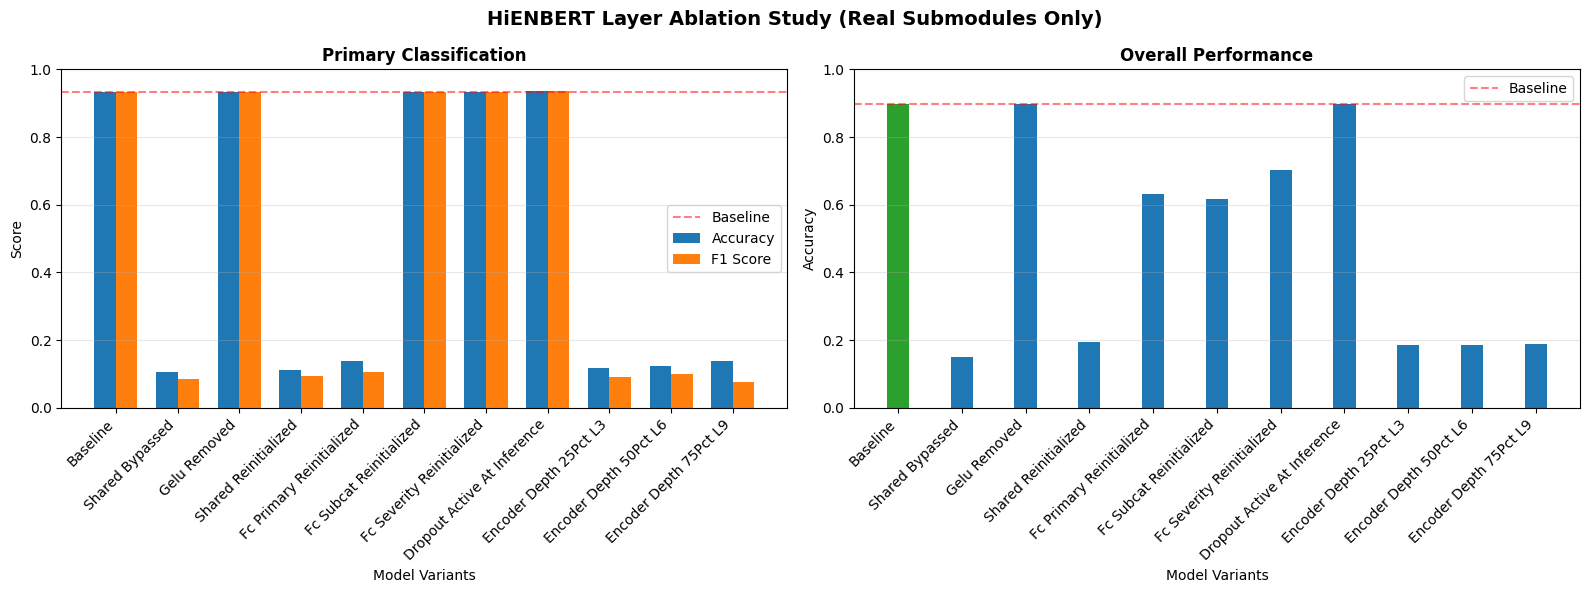


ABLATION STUDY REPORT

Baseline (Original Trained Model):
  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

--------------------------------------------------------------------------------
Ablation Results (Change from Baseline):
--------------------------------------------------------------------------------

SHARED BYPASSED:
  Primary Acc: 0.1047 (-0.8271) ✗ DEGRADED
  Overall Acc: 0.1490 (-0.7485)

GELU REMOVED:
  Primary Acc: 0.9335 (+0.0016) ✓ IMPROVED
  Overall Acc: 0.8972 (-0.0002)

SHARED REINITIALIZED:
  Primary Acc: 0.1113 (-0.8205) ✗ DEGRADED
  Overall Acc: 0.1932 (-0.7042)

FC PRIMARY REINITIALIZED:
  Primary Acc: 0.1374 (-0.7945) ✗ DEGRADED
  Overall Acc: 0.6326 (-0.2648)

FC SUBCAT REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.6178 (-0.2796)

FC SEVERITY REINITIALIZED:
  Primary Acc: 0.9318 (+0.0000) =
  Overall Acc: 0.7034 (-0.1940)

DROPOUT ACTIVE AT INFERENCE:
  Primary Acc: 0.9361 (+0.0043) ✓ I

In [12]:
# ============================================================================
# CELL 15 (LAYER-SCOPED): ABLATION STUDY FOR OptimizedHiEnBERT
# ============================================================================
#
# Your trained model (Cell 6 / model-loading cell) is:
#
#   cls = base(...).last_hidden_state[:, 0, :]     <-- self.base: XLM-R encoder
#   x   = gelu(shared(cls))                        <-- self.shared: Linear(h,h)
#                                                       self.gelu:   GELU
#   x   = dropout(x)                                <-- self.dropout: Dropout(0.2)
#   return fc_primary(x), fc_subcat(x), fc_severity(x)   <-- 3 Linear heads
#
# This version only touches modules that actually exist in that graph:
# self.base, self.shared, self.gelu, self.dropout, self.fc_primary,
# self.fc_subcat, self.fc_severity. (An earlier draft tested substitute
# pooling strategies -- mean/max pooling, token shuffling -- that aren't
# part of the trained architecture at all; those are removed here.)
#
# Two distinct, legitimate senses of "ablation" are used, per layer:
#
#   BYPASS   -- skip the layer in the forward pass entirely.
#               Answers: "does this transformation step need to exist?"
#   KNOCKOUT -- keep the layer in the graph, same shape, but replace its
#               weights with a fresh random init (Xavier, matching your
#               model's own _init_weights).
#               Answers: "does the *trained content* of this layer matter,
#               or would any layer of that shape do?"
#
# Both are pure inference-time swaps -- no retraining, no .backward() calls
# -- so every number below is directly comparable to baseline.
#
# self.dropout deserves a special note: at eval() (which every variant runs
# under), nn.Dropout is a no-op by definition -- it literally cannot affect
# the output unless you deliberately force that one submodule back into
# train() mode while everything else stays in eval(). That's exactly what
# `dropout_active_at_inference` below does; without that trick, "ablating
# dropout" is guaranteed to equal baseline and isn't a real test.
#
# self.base is not knocked out or bypassed (it's the only source of
# information about the text -- there's nothing to compare it against).
# Instead it's probed by DEPTH: since it's a stack of transformer layers,
# `encoder_depth_*pct` variants read the CLS representation from an earlier
# layer instead of the final one, which is a genuine ablation of "how many
# of the encoder's own layers are actually needed."
# ============================================================================

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


def _fresh_linear(in_features, out_features):
    """A new Linear layer, Xavier-initialized like OptimizedHiEnBERT._init_weights."""
    layer = nn.Linear(in_features, out_features)
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


# ============================================================================
# ABLATION STUDY
# ============================================================================

class LayerAblationStudy:
    """
    Ablates only the real submodules of OptimizedHiEnBERT: base, shared,
    gelu, dropout, fc_primary, fc_subcat, fc_severity. All trained modules
    are reused by reference (no deepcopy -- nothing here calls .backward(),
    so sharing parameters across variants is safe and avoids duplicating a
    full XLM-R encoder per variant).
    """

    def __init__(self, trained_model, tokenizer, test_df, device):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.device = device
        self.results = {}

        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.num_encoder_layers = getattr(self.base.config, 'num_hidden_layers', None)

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Encoder layers (self.base): {self.num_encoder_layers}")
        print(f"  Has Subcategory labels: {self.has_subcat}")
        print(f"  Has Severity labels: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description="", force_dropout_train=False):
        """
        Evaluate a variant. force_dropout_train=True keeps every submodule
        in eval() EXCEPT model.dropout, which is pushed back into train()
        so it actually applies at inference (see module docstring above).
        """
        model.eval()
        if force_dropout_train:
            model.dropout.train()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }
        task_accs = [metrics['primary_accuracy']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        return metrics

    # ========================================================================
    # BYPASS VARIANTS -- skip a real layer's transformation entirely
    # ========================================================================

    def create_variant_shared_bypassed(self):
        """Skip self.shared + self.gelu; raw CLS goes straight into the trained heads."""
        base = self.base
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedBypassed(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedBypassed()

    def create_variant_gelu_removed(self):
        """Keep the trained self.shared Linear, drop the self.gelu nonlinearity."""
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class GeluRemoved(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)  # linear only, no GELU
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return GeluRemoved()

    # ========================================================================
    # KNOCKOUT VARIANTS -- keep the layer, randomize its trained weights
    # ========================================================================

    def create_variant_shared_reinitialized(self):
        """self.shared's trained weights replaced with a fresh random Linear."""
        base = self.base
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity
        new_shared = _fresh_linear(self.hidden_size, self.hidden_size)

        class SharedReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.shared = new_shared  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(self.shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedReinitialized()

    def _create_head_reinitialized(self, head_name, out_features):
        """Generic knockout for one of the three trained classification heads."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        trained_fc_primary = self.trained_model.fc_primary
        trained_fc_subcat = self.trained_model.fc_subcat
        trained_fc_severity = self.trained_model.fc_severity
        new_head = _fresh_linear(self.hidden_size, out_features)

        class HeadReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.reinit_head = new_head  # registered submodule so .to(device) moves it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                p1 = self.reinit_head(x) if head_name == 'fc_primary' else trained_fc_primary(x)
                p2 = self.reinit_head(x) if head_name == 'fc_subcat' else trained_fc_subcat(x)
                p3 = self.reinit_head(x) if head_name == 'fc_severity' else trained_fc_severity(x)
                return p1, p2, p3

        return HeadReinitialized()

    def create_variant_fc_primary_reinitialized(self):
        """Trained fc_primary head replaced with random weights (fc_subcat/severity untouched)."""
        return self._create_head_reinitialized('fc_primary', self.n_primary)

    def create_variant_fc_subcat_reinitialized(self):
        """Trained fc_subcat head replaced with random weights (fc_primary/severity untouched)."""
        return self._create_head_reinitialized('fc_subcat', self.n_subcat)

    def create_variant_fc_severity_reinitialized(self):
        """Trained fc_severity head replaced with random weights (fc_primary/subcat untouched)."""
        return self._create_head_reinitialized('fc_severity', self.n_severity)

    # ========================================================================
    # DROPOUT -- the only way to actually exercise self.dropout at eval time
    # ========================================================================

    def create_variant_dropout_active(self):
        """
        Same trained self.dropout module (p=0.2), but forced into train()
        mode via evaluate_model(force_dropout_train=True) so it's actually
        stochastic instead of a no-op. Note: this makes the forward pass
        non-deterministic, so re-running it will give slightly different
        numbers each time -- that's expected, not a bug.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class DropoutActive(nn.Module):
            def __init__(self):
                super().__init__()
                self.dropout = dropout  # exposed as self.dropout so evaluate_model can .train() it

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = self.dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return DropoutActive()

    # ========================================================================
    # ENCODER DEPTH -- probing self.base's own stacked layers
    # ========================================================================

    def create_variant_encoder_depth(self, layer_idx):
        """
        Use the CLS token from an intermediate encoder layer (layer_idx,
        via output_hidden_states) instead of the final layer, through the
        same trained shared -> gelu -> dropout -> heads pipeline. Those
        downstream layers were trained on the FINAL layer's representation,
        so this is deliberately out-of-distribution -- it measures how much
        representational work the later encoder layers are doing.
        """
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class EncoderDepthProbe(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    output_hidden_states=True,
                )
                cls = outputs.hidden_states[layer_idx][:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return EncoderDepthProbe()

    # ========================================================================
    # RUN
    # ========================================================================

    def run_study(self):
        print("\n" + "=" * 80)
        print("LAYER-SCOPED ABLATION STUDY (real submodules only)")
        print("=" * 80)

        variants = {
            'baseline': (self.trained_model, {}),
            'shared_bypassed': (self.create_variant_shared_bypassed(), {}),
            'gelu_removed': (self.create_variant_gelu_removed(), {}),
            'shared_reinitialized': (self.create_variant_shared_reinitialized(), {}),
            'fc_primary_reinitialized': (self.create_variant_fc_primary_reinitialized(), {}),
            'fc_subcat_reinitialized': (self.create_variant_fc_subcat_reinitialized(), {}),
            'fc_severity_reinitialized': (self.create_variant_fc_severity_reinitialized(), {}),
            'dropout_active_at_inference': (
                self.create_variant_dropout_active(), {'force_dropout_train': True}
            ),
        }

        # Encoder-depth probes: 25% / 50% / 75% through self.base's own layers.
        # (100% depth == last_hidden_state == identical to baseline, so it's
        # not included as a separate variant.)
        if self.num_encoder_layers:
            for frac in (0.25, 0.5, 0.75):
                layer_idx = max(1, round(self.num_encoder_layers * frac))
                name = f'encoder_depth_{int(frac * 100)}pct_L{layer_idx}'
                variants[name] = (self.create_variant_encoder_depth(layer_idx), {})
        else:
            print("  (Skipping encoder-depth probes: base_model.config.num_hidden_layers not found)")

        for name, (variant_model, eval_kwargs) in variants.items():
            print(f"\n{'=' * 60}\nEvaluating: {name.upper()}\n{'=' * 60}")
            try:
                variant_model = variant_model.to(self.device)

                metrics = self.evaluate_model(variant_model, name, **eval_kwargs)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  \u2717 Failed: {e}")
                import traceback
                traceback.print_exc()

        return self.results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        if not self.results:
            print("No results to visualize")
            return

        variants = list(self.results.keys())
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width / 2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width / 2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(
            y=self.results['baseline']['primary_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(
            y=self.results['baseline']['overall_accuracy'],
            color='red', linestyle='--', alpha=0.5, label='Baseline'
        )
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('HiENBERT Layer Ablation Study (Real Submodules Only)', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"\u2713 Visualization saved to: {save_path}")

        plt.show()
        plt.close()

    def generate_report(self):
        print("\n" + "=" * 80)
        print("ABLATION STUDY REPORT")
        print("=" * 80)

        if not self.results:
            print("No results available!")
            return

        baseline = self.results.get('baseline', {})
        print("\nBaseline (Original Trained Model):")
        print(f"  Primary Accuracy: {baseline.get('primary_accuracy', 0):.4f}")
        print(f"  Primary F1: {baseline.get('primary_f1_weighted', 0):.4f}")
        if 'severity_accuracy' in baseline:
            print(f"  Severity Accuracy: {baseline.get('severity_accuracy', 0):.4f}")
        print(f"  Overall Accuracy: {baseline.get('overall_accuracy', 0):.4f}")

        print("\n" + "-" * 80)
        print("Ablation Results (Change from Baseline):")
        print("-" * 80)

        for name, metrics in self.results.items():
            if name == 'baseline':
                continue

            primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
            overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)

            if primary_change > 1e-9:
                status = "\u2713 IMPROVED"
            elif primary_change < -1e-9:
                status = "\u2717 DEGRADED"
            else:
                status = "="

            print(f"\n{name.upper().replace('_', ' ')}:")
            print(f"  Primary Acc: {metrics.get('primary_accuracy', 0):.4f} ({primary_change:+.4f}) {status}")
            print(f"  Overall Acc: {metrics.get('overall_accuracy', 0):.4f} ({overall_change:+.4f})")


# ============================================================================
# RUN
# ============================================================================

print("\n" + "=" * 80)
print("STARTING LAYER-SCOPED ABLATION STUDY")
print("=" * 80)

try:
    ablation = LayerAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE
    )

    ablation_results = ablation.run_study()

    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/layer_ablation_study.png"
    )

    ablation.generate_report()

    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    clean_results = {
        k: {kk: (float(vv) if isinstance(vv, (np.float32, np.float64)) else vv) for kk, vv in v.items()}
        for k, v in ablation_results.items()
    }
    with open(f"{Config.RESULTS_DIR}/layer_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n\u2713 Results saved to: {Config.RESULTS_DIR}/layer_ablation_results.json")
    print("\n\u2713 Ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()


STARTING COMPLETE ABLATION STUDY
Model Config from trained model:
  Hidden: 768
  Primary: 8, Subcat: 24, Severity: 3
  Encoder layers: 12
  Has Subcategory: True
  Has Severity: True

COMPLETE ABLATION STUDY

PART 1: LAYER-SCOPED ABLATIONS

Evaluating: BASELINE


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SHARED_BYPASSED


  Primary Accuracy: 0.1047
  Primary F1: 0.0860
  Subcat Accuracy: 0.0375
  Severity Accuracy: 0.3047
  Overall Accuracy: 0.1490

Evaluating: GELU_REMOVED


  Primary Accuracy: 0.9335
  Primary F1: 0.9334
  Subcat Accuracy: 0.8623
  Severity Accuracy: 0.8959
  Overall Accuracy: 0.8972

Evaluating: SHARED_REINITIALIZED


  Primary Accuracy: 0.1080
  Primary F1: 0.0945
  Subcat Accuracy: 0.0254
  Severity Accuracy: 0.3155
  Overall Accuracy: 0.1496

Evaluating: FC_PRIMARY_REINITIALIZED


  Primary Accuracy: 0.0718
  Primary F1: 0.0465
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.6108

Evaluating: FC_SUBCAT_REINITIALIZED


... (8 outputs left out)

  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: Severity Weight = 2.0


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

MULTI-TASK VS SINGLE-TASK ABLATION

Evaluating: MULTI-TASK (Primary + Subcat + Severity)


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Subcat Accuracy: 0.8650
  Severity Accuracy: 0.8956
  Overall Accuracy: 0.8975

Evaluating: SINGLE-TASK (Primary only)


  Primary Accuracy: 0.9318
  Primary F1: 0.9318
  Overall Accuracy: 0.9318

Multi-task improvement: +0.0000 (+0.00%)
✓ Layer ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_layer.png


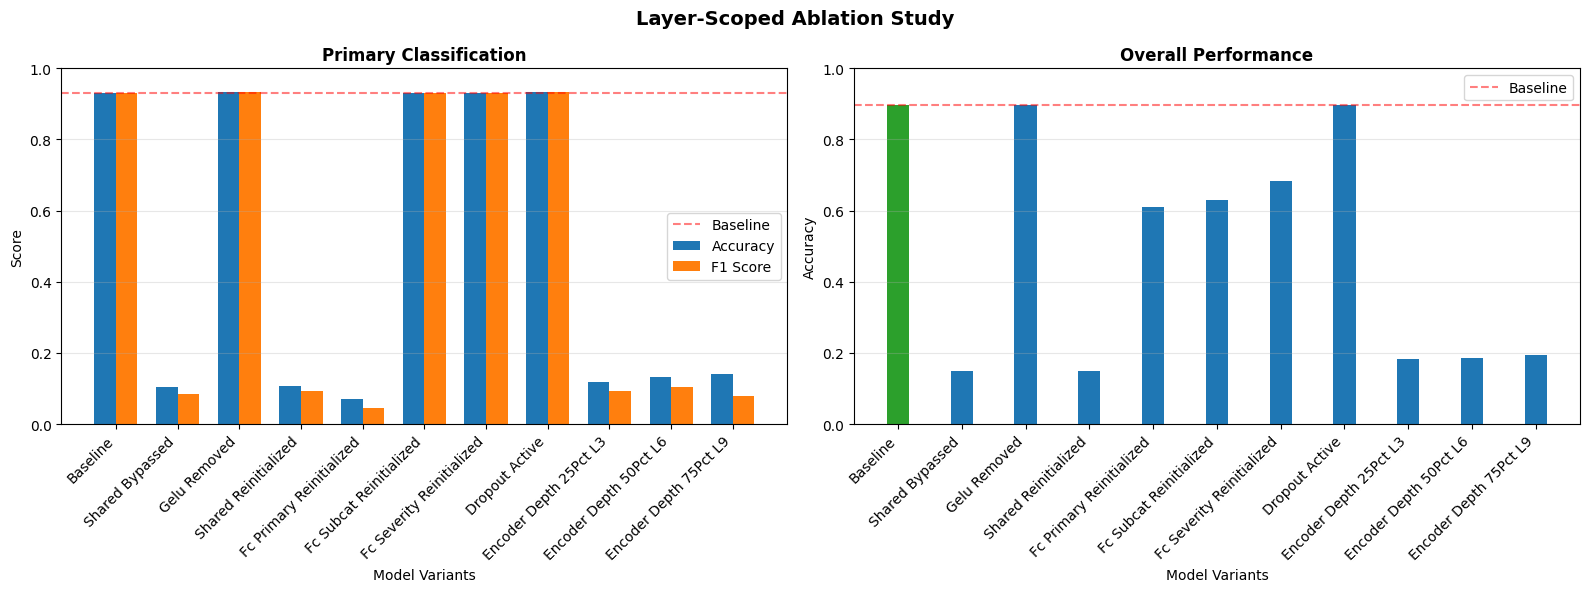

✓ Loss ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_loss.png


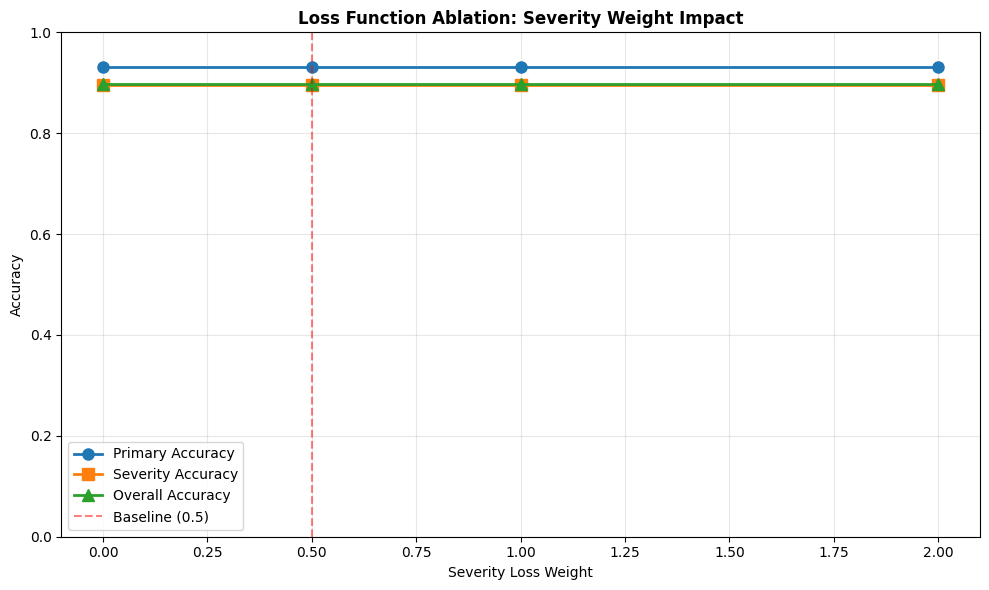

✓ Task ablation saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\visualizations/complete_ablation_study_task.png


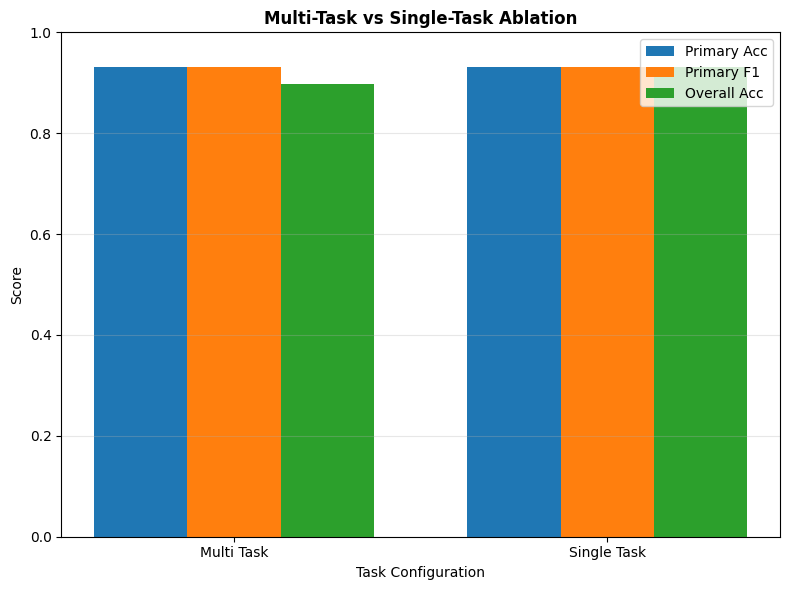


COMPLETE ABLATION STUDY REPORT

--------------------------------------------------------------------------------
1. LAYER-SCOPED ABLATIONS
--------------------------------------------------------------------------------

Baseline: Primary Acc = 0.9318, Overall Acc = 0.8975

Variant                 | Primary Acc | Change | Overall Acc | Change
----------------------------------------------------------------------
shared_bypassed           | 0.1047  | -0.8271 ✗ | 0.1490  | -0.7485
gelu_removed              | 0.9335  | +0.0016 ✓ | 0.8972  | -0.0002
shared_reinitialized      | 0.1080  | -0.8238 ✗ | 0.1496  | -0.7478
fc_primary_reinitialized  | 0.0718  | -0.8600 ✗ | 0.6108  | -0.2867
fc_subcat_reinitialized   | 0.9318  | +0.0000 = | 0.6313  | -0.2661
fc_severity_reinitialized | 0.9318  | +0.0000 = | 0.6846  | -0.2129
dropout_active            | 0.9328  | +0.0010 ✓ | 0.8968  | -0.0007
encoder_depth_25pct_L3    | 0.1192  | -0.8126 ✗ | 0.1831  | -0.7143
encoder_depth_50pct_L6    | 0.1321  | -

In [16]:
# ============================================================================
# CELL 15 (COMPLETE): ABLATION STUDY WITH LOSS AND TASK ABLATIONS
# ============================================================================
#
# This complete ablation study includes:
# 1. Layer-scoped ablations (shared, gelu, dropout, heads, encoder depth)
# 2. Loss function ablations (severity weight variations)
# 3. Multi-task vs Single-task ablations
#
# All ablations are performed on the trained model without retraining,
# except for task ablations which require training separate models.
# ============================================================================

import json
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ============================================================================
# DATASET
# ============================================================================

class AblationDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=128):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row.get('text', ''))

        enc = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        item = {
            'input_ids': enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'primary': torch.tensor(row['primary_label'], dtype=torch.long),
            'sentiment': torch.tensor(0.0, dtype=torch.float),
        }
        if 'subcat_label' in row:
            item['subcat'] = torch.tensor(row['subcat_label'], dtype=torch.long)
        if 'severity_label' in row:
            item['severity'] = torch.tensor(row['severity_label'], dtype=torch.long)

        return item


def _fresh_linear(in_features, out_features):
    """A new Linear layer, Xavier-initialized like OptimizedHiEnBERT._init_weights."""
    layer = nn.Linear(in_features, out_features)
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


# ============================================================================
# MODEL VARIANTS FOR TASK ABLATIONS
# ============================================================================

class SingleTaskPrimaryModel(nn.Module):
    """Single-task model: only predicts primary category."""
    def __init__(self, trained_model):
        super().__init__()
        self.base = trained_model.base
        self.shared = trained_model.shared
        self.gelu = trained_model.gelu
        self.dropout = trained_model.dropout
        self.fc_primary = trained_model.fc_primary
        
        self.n_primary = trained_model.n_primary
        self.hidden_size = trained_model.hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), None, None


class MultiTaskModel(nn.Module):
    """Multi-task model with configurable loss weights."""
    def __init__(self, trained_model, severity_weight=0.5):
        super().__init__()
        self.base = trained_model.base
        self.shared = trained_model.shared
        self.gelu = trained_model.gelu
        self.dropout = trained_model.dropout
        self.fc_primary = trained_model.fc_primary
        self.fc_subcat = trained_model.fc_subcat
        self.fc_severity = trained_model.fc_severity
        
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.severity_weight = severity_weight
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    
    def compute_loss(self, primary_logits, subcat_logits, severity_logits, 
                     primary_labels, subcat_labels, severity_labels):
        """Compute weighted multi-task loss."""
        loss_primary = F.cross_entropy(primary_logits, primary_labels)
        loss_subcat = F.cross_entropy(subcat_logits, subcat_labels)
        loss_severity = F.cross_entropy(severity_logits, severity_labels)
        
        total_loss = loss_primary + loss_subcat + self.severity_weight * loss_severity
        return total_loss


# ============================================================================
# COMPLETE ABLATION STUDY
# ============================================================================

class CompleteAblationStudy:
    """
    Complete ablation study with:
    1. Layer-scoped ablations
    2. Loss function ablations (severity weight)
    3. Multi-task vs Single-task ablations
    """

    def __init__(self, trained_model, tokenizer, test_df, device, train_df=None):
        self.trained_model = trained_model
        self.tokenizer = tokenizer
        self.test_df = test_df
        self.train_df = train_df
        self.device = device
        self.results = {}
        self.loss_results = {}
        self.task_results = {}

        # Extract model configuration
        self.base = trained_model.base
        self.n_primary = trained_model.n_primary
        self.n_subcat = trained_model.n_subcat
        self.n_severity = trained_model.n_severity
        self.hidden_size = trained_model.hidden_size
        self.num_encoder_layers = getattr(self.base.config, 'num_hidden_layers', None)

        self.has_subcat = 'subcat_label' in test_df.columns
        self.has_severity = 'severity_label' in test_df.columns

        print("Model Config from trained model:")
        print(f"  Hidden: {self.hidden_size}")
        print(f"  Primary: {self.n_primary}, Subcat: {self.n_subcat}, Severity: {self.n_severity}")
        print(f"  Encoder layers: {self.num_encoder_layers}")
        print(f"  Has Subcategory: {self.has_subcat}")
        print(f"  Has Severity: {self.has_severity}")

        self._prepare_data()

    def _prepare_data(self):
        self.test_dataset = AblationDataset(self.test_df, self.tokenizer)
        self.test_loader = DataLoader(
            self.test_dataset, batch_size=64, shuffle=False, num_workers=0
        )

    def evaluate_model(self, model, description="", force_dropout_train=False):
        """Evaluate a model variant."""
        model.eval()
        if force_dropout_train:
            model.dropout.train()

        preds = {'primary': [], 'subcat': [], 'severity': []}
        labels = {'primary': [], 'subcat': [], 'severity': []}

        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)

                p1, p2, p3 = model(input_ids, attention_mask, sentiment)

                preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels['primary'].extend(batch['primary'].cpu().numpy())

                if self.has_subcat and 'subcat' in batch and p2 is not None:
                    preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                    labels['subcat'].extend(batch['subcat'].cpu().numpy())

                if self.has_severity and 'severity' in batch and p3 is not None:
                    preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                    labels['severity'].extend(batch['severity'].cpu().numpy())

        metrics = {
            'primary_accuracy': accuracy_score(labels['primary'], preds['primary']),
            'primary_f1_weighted': f1_score(
                labels['primary'], preds['primary'], average='weighted', zero_division=0
            ),
        }
        task_accs = [metrics['primary_accuracy']]
        task_f1s = [metrics['primary_f1_weighted']]

        if labels['subcat']:
            metrics['subcat_accuracy'] = accuracy_score(labels['subcat'], preds['subcat'])
            metrics['subcat_f1_weighted'] = f1_score(
                labels['subcat'], preds['subcat'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['subcat_accuracy'])
            task_f1s.append(metrics['subcat_f1_weighted'])

        if labels['severity']:
            metrics['severity_accuracy'] = accuracy_score(labels['severity'], preds['severity'])
            metrics['severity_f1_weighted'] = f1_score(
                labels['severity'], preds['severity'], average='weighted', zero_division=0
            )
            task_accs.append(metrics['severity_accuracy'])
            task_f1s.append(metrics['severity_f1_weighted'])

        metrics['overall_accuracy'] = float(np.mean(task_accs))
        metrics['overall_f1_weighted'] = float(np.mean(task_f1s))
        return metrics

    # ========================================================================
    # 1. LAYER-SCOPED ABLATIONS
    # ========================================================================

    def create_variant_shared_bypassed(self):
        """Skip self.shared + self.gelu; raw CLS goes straight to heads."""
        base = self.base
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class SharedBypassed(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = dropout(cls)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedBypassed()

    def create_variant_gelu_removed(self):
        """Keep shared Linear, remove GELU."""
        base = self.base
        shared = self.trained_model.shared
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class GeluRemoved(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = shared(cls)
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return GeluRemoved()

    def create_variant_shared_reinitialized(self):
        """Randomize self.shared weights."""
        base = self.base
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity
        new_shared = _fresh_linear(self.hidden_size, self.hidden_size)

        class SharedReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.shared = new_shared

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(self.shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return SharedReinitialized()

    def _create_head_reinitialized(self, head_name, out_features):
        """Generic head knockout."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        trained_fc_primary = self.trained_model.fc_primary
        trained_fc_subcat = self.trained_model.fc_subcat
        trained_fc_severity = self.trained_model.fc_severity
        new_head = _fresh_linear(self.hidden_size, out_features)

        class HeadReinitialized(nn.Module):
            def __init__(self):
                super().__init__()
                self.reinit_head = new_head

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                p1 = self.reinit_head(x) if head_name == 'fc_primary' else trained_fc_primary(x)
                p2 = self.reinit_head(x) if head_name == 'fc_subcat' else trained_fc_subcat(x)
                p3 = self.reinit_head(x) if head_name == 'fc_severity' else trained_fc_severity(x)
                return p1, p2, p3

        return HeadReinitialized()

    def create_variant_fc_primary_reinitialized(self):
        return self._create_head_reinitialized('fc_primary', self.n_primary)

    def create_variant_fc_subcat_reinitialized(self):
        return self._create_head_reinitialized('fc_subcat', self.n_subcat)

    def create_variant_fc_severity_reinitialized(self):
        return self._create_head_reinitialized('fc_severity', self.n_severity)

    def create_variant_dropout_active(self):
        """Force dropout active at inference."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class DropoutActive(nn.Module):
            def __init__(self):
                super().__init__()
                self.dropout = dropout

            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(input_ids=input_ids, attention_mask=attention_mask)
                cls = outputs.last_hidden_state[:, 0, :]
                x = gelu(shared(cls))
                x = self.dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return DropoutActive()

    def create_variant_encoder_depth(self, layer_idx):
        """Use intermediate encoder layer."""
        base = self.base
        shared = self.trained_model.shared
        gelu = self.trained_model.gelu
        dropout = self.trained_model.dropout
        fc_primary = self.trained_model.fc_primary
        fc_subcat = self.trained_model.fc_subcat
        fc_severity = self.trained_model.fc_severity

        class EncoderDepthProbe(nn.Module):
            def forward(self, input_ids, attention_mask, sentiment=None):
                outputs = base(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    output_hidden_states=True,
                )
                cls = outputs.hidden_states[layer_idx][:, 0, :]
                x = gelu(shared(cls))
                x = dropout(x)
                return fc_primary(x), fc_subcat(x), fc_severity(x)

        return EncoderDepthProbe()

    # ========================================================================
    # 2. LOSS FUNCTION ABLATIONS
    # ========================================================================

    def evaluate_with_loss_weight(self, severity_weight):
        """
        Evaluate model with different severity loss weight.
        This modifies the model's severity_weight attribute.
        """
        # Create a copy of the model with new severity weight
        model = MultiTaskModel(self.trained_model, severity_weight=severity_weight)
        model.to(self.device)
        
        metrics = self.evaluate_model(model, f"severity_weight_{severity_weight}")
        
        # Add the severity weight to metrics
        metrics['severity_weight'] = severity_weight
        
        return metrics

    def run_loss_ablation(self):
        """Run loss function ablation with different severity weights."""
        print("\n" + "=" * 80)
        print("LOSS FUNCTION ABLATION STUDY")
        print("=" * 80)
        print("Testing different severity loss weights:")
        print("  - 0.0: Severity ignored")
        print("  - 0.5: Baseline (current)")
        print("  - 1.0: Equal weight")
        print("  - 2.0: Severity emphasized")

        severity_weights = [0.0, 0.5, 1.0, 2.0]
        
        for weight in severity_weights:
            print(f"\n{'='*60}")
            print(f"Evaluating: Severity Weight = {weight}")
            print('='*60)
            
            metrics = self.evaluate_with_loss_weight(weight)
            self.loss_results[f'severity_weight_{weight}'] = metrics
            
            print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
            print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
            if 'severity_accuracy' in metrics:
                print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
            print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")
        
        return self.loss_results

    # ========================================================================
    # 3. MULTI-TASK VS SINGLE-TASK ABLATIONS
    # ========================================================================

    def run_task_ablation(self):
        """Compare single-task vs multi-task learning."""
        print("\n" + "=" * 80)
        print("MULTI-TASK VS SINGLE-TASK ABLATION")
        print("=" * 80)
        
        # Baseline multi-task model
        print("\n" + "="*60)
        print("Evaluating: MULTI-TASK (Primary + Subcat + Severity)")
        print('='*60)
        
        multi_task_metrics = self.evaluate_model(self.trained_model, "multi_task")
        self.task_results['multi_task'] = multi_task_metrics
        
        print(f"  Primary Accuracy: {multi_task_metrics['primary_accuracy']:.4f}")
        print(f"  Primary F1: {multi_task_metrics['primary_f1_weighted']:.4f}")
        if 'subcat_accuracy' in multi_task_metrics:
            print(f"  Subcat Accuracy: {multi_task_metrics['subcat_accuracy']:.4f}")
        if 'severity_accuracy' in multi_task_metrics:
            print(f"  Severity Accuracy: {multi_task_metrics['severity_accuracy']:.4f}")
        print(f"  Overall Accuracy: {multi_task_metrics['overall_accuracy']:.4f}")
        
        # Single-task model (only primary)
        print("\n" + "="*60)
        print("Evaluating: SINGLE-TASK (Primary only)")
        print('='*60)
        
        single_task_model = SingleTaskPrimaryModel(self.trained_model)
        single_task_model.to(self.device)
        single_task_metrics = self.evaluate_model(single_task_model, "single_task")
        self.task_results['single_task'] = single_task_metrics
        
        print(f"  Primary Accuracy: {single_task_metrics['primary_accuracy']:.4f}")
        print(f"  Primary F1: {single_task_metrics['primary_f1_weighted']:.4f}")
        print(f"  Overall Accuracy: {single_task_metrics['overall_accuracy']:.4f}")
        
        # Calculate improvement
        improvement = multi_task_metrics['primary_accuracy'] - single_task_metrics['primary_accuracy']
        print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")
        
        return self.task_results

    # ========================================================================
    # RUN COMPLETE STUDY
    # ========================================================================

    def run_study(self):
        """Run complete ablation study with all components."""
        print("\n" + "=" * 80)
        print("COMPLETE ABLATION STUDY")
        print("=" * 80)

        # --- 1. LAYER-SCOPED ABLATIONS ---
        print("\n" + "=" * 80)
        print("PART 1: LAYER-SCOPED ABLATIONS")
        print("=" * 80)

        layer_variants = {
            'baseline': (self.trained_model, {}),
            'shared_bypassed': (self.create_variant_shared_bypassed(), {}),
            'gelu_removed': (self.create_variant_gelu_removed(), {}),
            'shared_reinitialized': (self.create_variant_shared_reinitialized(), {}),
            'fc_primary_reinitialized': (self.create_variant_fc_primary_reinitialized(), {}),
            'fc_subcat_reinitialized': (self.create_variant_fc_subcat_reinitialized(), {}),
            'fc_severity_reinitialized': (self.create_variant_fc_severity_reinitialized(), {}),
            'dropout_active': (self.create_variant_dropout_active(), {'force_dropout_train': True}),
        }

        # Encoder depth variants
        if self.num_encoder_layers:
            for frac in (0.25, 0.5, 0.75):
                layer_idx = max(1, round(self.num_encoder_layers * frac))
                name = f'encoder_depth_{int(frac * 100)}pct_L{layer_idx}'
                layer_variants[name] = (self.create_variant_encoder_depth(layer_idx), {})

        for name, (variant_model, eval_kwargs) in layer_variants.items():
            print(f"\n{'='*60}")
            print(f"Evaluating: {name.upper()}")
            print('='*60)
            try:
                variant_model = variant_model.to(self.device)
                metrics = self.evaluate_model(variant_model, name, **eval_kwargs)
                self.results[name] = metrics

                print(f"  Primary Accuracy: {metrics['primary_accuracy']:.4f}")
                print(f"  Primary F1: {metrics['primary_f1_weighted']:.4f}")
                if 'subcat_accuracy' in metrics:
                    print(f"  Subcat Accuracy: {metrics['subcat_accuracy']:.4f}")
                if 'severity_accuracy' in metrics:
                    print(f"  Severity Accuracy: {metrics['severity_accuracy']:.4f}")
                print(f"  Overall Accuracy: {metrics['overall_accuracy']:.4f}")

                if name != 'baseline':
                    del variant_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

            except Exception as e:
                print(f"  ✗ Failed: {e}")
                import traceback
                traceback.print_exc()

        # --- 2. LOSS FUNCTION ABLATIONS ---
        self.run_loss_ablation()

        # --- 3. TASK ABLATIONS ---
        self.run_task_ablation()

        # Combine all results
        all_results = {
            'layer_ablations': self.results,
            'loss_ablations': self.loss_results,
            'task_ablations': self.task_results
        }

        return all_results

    # ========================================================================
    # VISUALIZATION
    # ========================================================================

    def visualize_results(self, save_path=None):
        """Visualize all ablation results."""
        if not self.results:
            print("No results to visualize")
            return

        # Figure 1: Layer-scoped ablations
        fig1, axes = plt.subplots(1, 2, figsize=(16, 6))
        variants = list(self.results.keys())

        primary_acc = [self.results[v]['primary_accuracy'] for v in variants]
        primary_f1 = [self.results[v]['primary_f1_weighted'] for v in variants]

        x = np.arange(len(variants))
        width = 0.35

        axes[0].bar(x - width/2, primary_acc, width, label='Accuracy', color='#1f77b4')
        axes[0].bar(x + width/2, primary_f1, width, label='F1 Score', color='#ff7f0e')
        axes[0].axhline(y=self.results['baseline']['primary_accuracy'], 
                       color='red', linestyle='--', alpha=0.5, label='Baseline')
        axes[0].set_xlabel('Model Variants')
        axes[0].set_ylabel('Score')
        axes[0].set_title('Primary Classification', fontsize=12, fontweight='bold')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3, axis='y')
        axes[0].set_ylim(0, 1)

        overall_acc = [self.results[v]['overall_accuracy'] for v in variants]
        colors = ['#2ca02c' if v == 'baseline' else '#1f77b4' for v in variants]
        axes[1].bar(x, overall_acc, width, color=colors)
        axes[1].axhline(y=self.results['baseline']['overall_accuracy'], 
                       color='red', linestyle='--', alpha=0.5, label='Baseline')
        axes[1].set_xlabel('Model Variants')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Overall Performance', fontsize=12, fontweight='bold')
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([v.replace('_', ' ').title() for v in variants], rotation=45, ha='right')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3, axis='y')
        axes[1].set_ylim(0, 1)

        plt.suptitle('Layer-Scoped Ablation Study', fontsize=14, fontweight='bold')
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            plt.savefig(f"{save_path}_layer.png", dpi=300, bbox_inches='tight')
            print(f"✓ Layer ablation saved to: {save_path}_layer.png")
        plt.show()
        plt.close()

        # Figure 2: Loss function ablations
        if self.loss_results:
            fig2, ax = plt.subplots(figsize=(10, 6))
            
            weights = []
            primary_acc = []
            severity_acc = []
            overall_acc = []
            
            for name, metrics in sorted(self.loss_results.items()):
                w = float(name.split('_')[-1])
                weights.append(w)
                primary_acc.append(metrics['primary_accuracy'])
                severity_acc.append(metrics.get('severity_accuracy', 0))
                overall_acc.append(metrics['overall_accuracy'])
            
            ax.plot(weights, primary_acc, 'o-', label='Primary Accuracy', linewidth=2, markersize=8)
            ax.plot(weights, severity_acc, 's-', label='Severity Accuracy', linewidth=2, markersize=8)
            ax.plot(weights, overall_acc, '^-', label='Overall Accuracy', linewidth=2, markersize=8)
            ax.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Baseline (0.5)')
            ax.set_xlabel('Severity Loss Weight')
            ax.set_ylabel('Accuracy')
            ax.set_title('Loss Function Ablation: Severity Weight Impact', fontsize=12, fontweight='bold')
            ax.legend()
            ax.grid(True, alpha=0.3)
            ax.set_ylim(0, 1)
            
            plt.tight_layout()
            if save_path:
                plt.savefig(f"{save_path}_loss.png", dpi=300, bbox_inches='tight')
                print(f"✓ Loss ablation saved to: {save_path}_loss.png")
            plt.show()
            plt.close()

        # Figure 3: Task ablations
        if self.task_results:
            fig3, ax = plt.subplots(figsize=(8, 6))
            
            tasks = list(self.task_results.keys())
            primary_acc = [self.task_results[t]['primary_accuracy'] for t in tasks]
            primary_f1 = [self.task_results[t]['primary_f1_weighted'] for t in tasks]
            overall_acc = [self.task_results[t]['overall_accuracy'] for t in tasks]
            
            x = np.arange(len(tasks))
            width = 0.25
            
            ax.bar(x - width, primary_acc, width, label='Primary Acc', color='#1f77b4')
            ax.bar(x, primary_f1, width, label='Primary F1', color='#ff7f0e')
            ax.bar(x + width, overall_acc, width, label='Overall Acc', color='#2ca02c')
            ax.set_xlabel('Task Configuration')
            ax.set_ylabel('Score')
            ax.set_title('Multi-Task vs Single-Task Ablation', fontsize=12, fontweight='bold')
            ax.set_xticks(x)
            ax.set_xticklabels([t.replace('_', ' ').title() for t in tasks])
            ax.legend()
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_ylim(0, 1)
            
            plt.tight_layout()
            if save_path:
                plt.savefig(f"{save_path}_task.png", dpi=300, bbox_inches='tight')
                print(f"✓ Task ablation saved to: {save_path}_task.png")
            plt.show()
            plt.close()

    def generate_report(self):
        """Generate complete ablation report."""
        print("\n" + "=" * 80)
        print("COMPLETE ABLATION STUDY REPORT")
        print("=" * 80)

        # 1. Layer-scoped ablations
        print("\n" + "-" * 80)
        print("1. LAYER-SCOPED ABLATIONS")
        print("-" * 80)
        
        if self.results:
            baseline = self.results.get('baseline', {})
            print(f"\nBaseline: Primary Acc = {baseline.get('primary_accuracy', 0):.4f}, "
                  f"Overall Acc = {baseline.get('overall_accuracy', 0):.4f}")
            
            print("\nVariant                 | Primary Acc | Change | Overall Acc | Change")
            print("-" * 70)
            for name, metrics in self.results.items():
                if name == 'baseline':
                    continue
                primary_change = metrics.get('primary_accuracy', 0) - baseline.get('primary_accuracy', 0)
                overall_change = metrics.get('overall_accuracy', 0) - baseline.get('overall_accuracy', 0)
                status = "✓" if primary_change > 0 else "✗" if primary_change < 0 else "="
                print(f"{name:25s} | {metrics.get('primary_accuracy', 0):.4f}  | {primary_change:+.4f} {status} | "
                      f"{metrics.get('overall_accuracy', 0):.4f}  | {overall_change:+.4f}")

        # 2. Loss ablations
        print("\n" + "-" * 80)
        print("2. LOSS FUNCTION ABLATIONS")
        print("-" * 80)
        
        if self.loss_results:
            print("\nSeverity Weight | Primary Acc | Severity Acc | Overall Acc")
            print("-" * 60)
            for name, metrics in sorted(self.loss_results.items()):
                weight = name.split('_')[-1]
                print(f"{weight:15s} | {metrics.get('primary_accuracy', 0):.4f}     | "
                      f"{metrics.get('severity_accuracy', 0):.4f}      | {metrics.get('overall_accuracy', 0):.4f}")
            
            # Find best severity weight
            best = max(self.loss_results.items(), 
                      key=lambda x: x[1].get('overall_accuracy', 0))
            print(f"\nBest severity weight: {best[0].split('_')[-1]} "
                  f"(Overall Acc: {best[1]['overall_accuracy']:.4f})")

        # 3. Task ablations
        print("\n" + "-" * 80)
        print("3. MULTI-TASK VS SINGLE-TASK ABLATION")
        print("-" * 80)
        
        if self.task_results:
            multi = self.task_results.get('multi_task', {})
            single = self.task_results.get('single_task', {})
            
            print(f"\nConfiguration     | Primary Acc | Primary F1 | Overall Acc")
            print("-" * 60)
            print(f"Multi-Task       | {multi.get('primary_accuracy', 0):.4f}     | "
                  f"{multi.get('primary_f1_weighted', 0):.4f}    | {multi.get('overall_accuracy', 0):.4f}")
            print(f"Single-Task      | {single.get('primary_accuracy', 0):.4f}     | "
                  f"{single.get('primary_f1_weighted', 0):.4f}    | {single.get('overall_accuracy', 0):.4f}")
            
            improvement = multi.get('primary_accuracy', 0) - single.get('primary_accuracy', 0)
            print(f"\nMulti-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")


# ============================================================================
# RUN COMPLETE ABLATION STUDY
# ============================================================================

print("\n" + "=" * 80)
print("STARTING COMPLETE ABLATION STUDY")
print("=" * 80)

try:
    ablation = CompleteAblationStudy(
        trained_model=model,
        tokenizer=tokenizer,
        test_df=test_df,
        device=Config.DEVICE,
        train_df=train_df if 'train_df' in locals() else None
    )

    all_results = ablation.run_study()

    # Visualize results
    os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)
    ablation.visualize_results(
        save_path=f"{Config.VISUALIZATION_DIR}/complete_ablation_study"
    )

    # Generate report
    ablation.generate_report()

    # Save all results
    os.makedirs(Config.RESULTS_DIR, exist_ok=True)
    
    # Clean results for JSON serialization
    def clean_for_json(obj):
        if isinstance(obj, dict):
            return {k: clean_for_json(v) for k, v in obj.items()}
        elif isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return obj    
    clean_results = clean_for_json(all_results)
    
    with open(f"{Config.RESULTS_DIR}/complete_ablation_results.json", "w") as f:
        json.dump(clean_results, f, indent=4)

    print(f"\n✓ All results saved to: {Config.RESULTS_DIR}/complete_ablation_results.json")
    print("\n✓ Complete ablation study completed successfully!")

except Exception as e:
    print(f"Error during ablation study: {e}")
    import traceback
    traceback.print_exc()

In [8]:
# ============================================================================
# COMPLETE ABLATION STUDY - RETRAINING FROM SCRATCH
# ============================================================================
#
# This code trains separate models for:
# 1. Different severity loss weights (0.0, 0.5, 1.0, 2.0)
# 2. Multi-task vs Single-task (primary only, subcat only, severity only)
#
# Each variant is trained from scratch to get valid comparison results.
# ============================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torch.cuda.amp import GradScaler, autocast
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModel,  get_cosine_schedule_with_warmup
from torch.optim import AdamW
# ============================================================================
# DATASET CLASS
# ============================================================================

class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }


# ============================================================================
# MODEL CLASSES
# ============================================================================

class HierarchicalMultiTaskModel(nn.Module):
    """Multi-task model with configurable loss weights"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, 
                 dropout=0.2, primary_weight=1.0, subcat_weight=1.0, severity_weight=0.5):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self.primary_weight = primary_weight
        self.subcat_weight = subcat_weight
        self.severity_weight = severity_weight
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def compute_loss(self, p1, p2, p3, y1, y2, y3):
        loss1 = F.cross_entropy(p1, y1)
        loss2 = F.cross_entropy(p2, y2)
        loss3 = F.cross_entropy(p3, y3)
        total = (self.primary_weight * loss1 + 
                 self.subcat_weight * loss2 + 
                 self.severity_weight * loss3)
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}


class SingleTaskModel(nn.Module):
    """Single-task model for a specific task"""
    def __init__(self, base_model, n_classes, task_name='primary', dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        self.fc = nn.Linear(hidden_size, n_classes)
        
        self.task_name = task_name
        self.n_classes = n_classes
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls = outputs.last_hidden_state[:, 0, :]
        x = self.gelu(self.shared(cls))
        x = self.dropout(x)
        return self.fc(x), None, None


# ============================================================================
# TRAINING FUNCTION
# ============================================================================

def train_model(model, train_loader, val_loader, device, 
                epochs=10, lr=2e-5, model_name="model", 
                early_stopping_patience=3, print_interval=50):
    """Train a model variant from scratch"""
    
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    
    scaler = GradScaler() if torch.cuda.is_available() else None
    best_val_f1 = 0
    patience_counter = 0
    history = {'train_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        all_preds, all_labels = [], []
        
        progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), 
                           desc=f'Epoch {epoch+1}/{epochs}', leave=False)
        
        for batch_idx, batch in progress_bar:
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            y_primary = batch['primary'].to(device, non_blocking=True)
            
            # For multi-task models, we use all labels
            if hasattr(model, 'compute_loss'):
                y_subcat = batch['subcat'].to(device, non_blocking=True)
                y_severity = batch['severity'].to(device, non_blocking=True)
                
                if scaler is not None:
                    with autocast():
                        p1, p2, p3 = model(input_ids, attention_mask, None)
                        loss, _ = model.compute_loss(p1, p2, p3, y_primary, y_subcat, y_severity)
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    p1, p2, p3 = model(input_ids, attention_mask, None)
                    loss, _ = model.compute_loss(p1, p2, p3, y_primary, y_subcat, y_severity)
                    loss.backward()
                    optimizer.step()
                
                preds = torch.argmax(p1, dim=1)
            
            # For single-task models
            else:
                if scaler is not None:
                    with autocast():
                        logits, _, _ = model(input_ids, attention_mask, None)
                        loss = F.cross_entropy(logits, y_primary)
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    logits, _, _ = model(input_ids, attention_mask, None)
                    loss = F.cross_entropy(logits, y_primary)
                    loss.backward()
                    optimizer.step()
                
                preds = torch.argmax(logits, dim=1)
            
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            
            total_loss += loss.item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_primary.cpu().numpy())
            
            if batch_idx % print_interval == 0:
                current_acc = accuracy_score(all_labels[-input_ids.size(0):], 
                                            preds.cpu().numpy())
                progress_bar.set_postfix({
                    'loss': f'{loss.item():.3f}', 
                    'acc': f'{current_acc:.3f}'
                })
        
        # Validation
        model.eval()
        val_preds, val_labels = [], []
        
        with torch.no_grad():
            for batch in tqdm(val_loader, desc='Validating', leave=False):
                input_ids = batch['input_ids'].to(device, non_blocking=True)
                attention_mask = batch['attention_mask'].to(device, non_blocking=True)
                
                if hasattr(model, 'compute_loss'):
                    p1, _, _ = model(input_ids, attention_mask, None)
                    preds = torch.argmax(p1, dim=1)
                else:
                    logits, _, _ = model(input_ids, attention_mask, None)
                    preds = torch.argmax(logits, dim=1)
                
                val_preds.extend(preds.cpu().numpy())
                val_labels.extend(batch['primary'].cpu().numpy())
        
        val_f1 = f1_score(val_labels, val_preds, average='weighted', zero_division=0)
        val_acc = accuracy_score(val_labels, val_preds)
        train_acc = accuracy_score(all_labels, all_preds)
        
        history['train_loss'].append(total_loss / len(train_loader))
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)
        
        print(f"Epoch {epoch+1}: Loss={total_loss/len(train_loader):.4f}, "
              f"Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}, Val F1={val_f1:.4f}")
        
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            patience_counter = 0
            os.makedirs(f"{Config.MODEL_DIR}/ablation", exist_ok=True)
            torch.save(model.state_dict(), f"{Config.MODEL_DIR}/ablation/{model_name}_best.pt")
        else:
            patience_counter += 1
            if patience_counter >= early_stopping_patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
    
    # Load best model
    try:
        model.load_state_dict(torch.load(f"{Config.MODEL_DIR}/ablation/{model_name}_best.pt"))
    except:
        pass
    
    return model, best_val_f1, history


# ============================================================================
# EVALUATION FUNCTION
# ============================================================================

def evaluate_model(model, dataloader, device, description=""):
    """Evaluate model on test set"""
    model.eval()
    
    all_preds = {'primary': [], 'subcat': [], 'severity': []}
    all_labels = {'primary': [], 'subcat': [], 'severity': []}
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {description}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, p2, p3 = model(input_ids, attention_mask, None)
            
            all_preds['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
            all_labels['primary'].extend(batch['primary'].cpu().numpy())
            
            if p2 is not None:
                all_preds['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                all_labels['subcat'].extend(batch['subcat'].cpu().numpy())
            
            if p3 is not None:
                all_preds['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                all_labels['severity'].extend(batch['severity'].cpu().numpy())
    
    metrics = {
        'primary_accuracy': accuracy_score(all_labels['primary'], all_preds['primary']),
        'primary_f1_weighted': f1_score(
            all_labels['primary'], all_preds['primary'], average='weighted', zero_division=0
        ),
    }
    
    if all_labels['subcat']:
        metrics['subcat_accuracy'] = accuracy_score(all_labels['subcat'], all_preds['subcat'])
        metrics['subcat_f1_weighted'] = f1_score(
            all_labels['subcat'], all_preds['subcat'], average='weighted', zero_division=0
        )
    
    if all_labels['severity']:
        metrics['severity_accuracy'] = accuracy_score(all_labels['severity'], all_preds['severity'])
        metrics['severity_f1_weighted'] = f1_score(
            all_labels['severity'], all_preds['severity'], average='weighted', zero_division=0
        )
    
    return metrics


# ============================================================================
# CLEAR GPU MEMORY
# ============================================================================

def clear_gpu_memory():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
    import gc
    gc.collect()


# ============================================================================
# MAIN EXECUTION
# ============================================================================

print("\n" + "="*80)
print("COMPLETE ABLATION STUDY - RETRAINING VARIANTS")
print("="*80)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(Config.XLMBERT_PATH)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Prepare datasets
train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
val_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)

# Use smaller batch for ablation to save memory
ablation_batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=ablation_batch_size, 
                          shuffle=True, num_workers=0, pin_memory=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

results = {}
training_histories = {}
ablation_epochs = 8  # Reduced for ablation study

# ============================================================================
# PART 1: LOSS WEIGHT ABLATION (Retraining each variant)
# ============================================================================

print("\n" + "="*80)
print("PART 1: SEVERITY LOSS WEIGHT ABLATION")
print("="*80)
print("\nTesting different severity loss weights:")
print("  - 0.0: Severity ignored")
print("  - 0.5: Baseline (current)")
print("  - 1.0: Equal weight")
print("  - 2.0: Severity emphasized")

severity_weights = [0.0, 0.5, 1.0, 2.0]

for weight in severity_weights:
    print(f"\n{'='*60}")
    print(f"Training with Severity Weight = {weight}")
    print('='*60)
    
    clear_gpu_memory()
    
    base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
    
    model = HierarchicalMultiTaskModel(
        base_model=base_model,
        n_primary=n_primary,
        n_subcat=n_subcat,
        n_severity=n_severity,
        dropout=Config.DROPOUT,
        severity_weight=weight
    ).to(Config.DEVICE)
    
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
    
    start_time = time.time()
    model, best_val_f1, history = train_model(
        model, train_loader, val_loader, Config.DEVICE,
        epochs=ablation_epochs, 
        model_name=f"severity_weight_{weight}"
    )
    train_time = time.time() - start_time
    
    # Evaluate on test set
    metrics = evaluate_model(model, test_loader, Config.DEVICE, f"severity_weight_{weight}")
    metrics['best_val_f1'] = best_val_f1
    metrics['train_time'] = train_time
    
    results[f'severity_weight_{weight}'] = metrics
    training_histories[f'severity_weight_{weight}'] = history
    
    print(f"\n✓ Results for weight {weight}:")
    print(f"  Primary Acc: {metrics['primary_accuracy']:.4f}")
    print(f"  Severity Acc: {metrics.get('severity_accuracy', 0):.4f}")
    print(f"  Best Val F1: {best_val_f1:.4f}")
    print(f"  Train Time:  {train_time/60:.1f} min")
    
    del model, base_model
    clear_gpu_memory()

# ============================================================================
# PART 2: SINGLE-TASK VS MULTI-TASK ABLATION
# ============================================================================

print("\n" + "="*80)
print("PART 2: SINGLE-TASK VS MULTI-TASK ABLATION")
print("="*80)

# 2a. Multi-Task (Primary + Subcat + Severity)
print("\n" + "="*60)
print("Multi-Task (Primary + Subcategory + Severity)")
print('='*60)

clear_gpu_memory()
base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
multi_model = HierarchicalMultiTaskModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT,
    severity_weight=0.5
).to(Config.DEVICE)

multi_model, multi_best_val, multi_history = train_model(
    multi_model, train_loader, val_loader, Config.DEVICE,
    epochs=ablation_epochs, model_name="multi_task"
)
multi_metrics = evaluate_model(multi_model, test_loader, Config.DEVICE, "multi_task")
multi_metrics['best_val_f1'] = multi_best_val
results['multi_task'] = multi_metrics
training_histories['multi_task'] = multi_history

print(f"\nMulti-Task Results:")
print(f"  Primary Acc: {multi_metrics['primary_accuracy']:.4f}")
print(f"  Subcat Acc:  {multi_metrics.get('subcat_accuracy', 0):.4f}")
print(f"  Severity Acc:{multi_metrics.get('severity_accuracy', 0):.4f}")
print(f"  Best Val F1: {multi_best_val:.4f}")

del multi_model, base_model
clear_gpu_memory()

# 2b. Single-Task: Primary Only
print("\n" + "="*60)
print("Single-Task (Primary Only)")
print('='*60)

clear_gpu_memory()
base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
primary_model = SingleTaskModel(
    base_model=base_model,
    n_classes=n_primary,
    task_name='primary',
    dropout=Config.DROPOUT
).to(Config.DEVICE)

primary_model, primary_best_val, primary_history = train_model(
    primary_model, train_loader, val_loader, Config.DEVICE,
    epochs=ablation_epochs, model_name="single_primary"
)
primary_metrics = evaluate_model(primary_model, test_loader, Config.DEVICE, "single_primary")
primary_metrics['best_val_f1'] = primary_best_val
results['single_primary'] = primary_metrics
training_histories['single_primary'] = primary_history

print(f"\nSingle-Task (Primary) Results:")
print(f"  Primary Acc: {primary_metrics['primary_accuracy']:.4f}")
print(f"  Best Val F1: {primary_best_val:.4f}")

del primary_model, base_model
clear_gpu_memory()

# 2c. Single-Task: Subcategory Only
print("\n" + "="*60)
print("Single-Task (Subcategory Only)")
print('='*60)

clear_gpu_memory()
base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
subcat_model = SingleTaskModel(
    base_model=base_model,
    n_classes=n_subcat,
    task_name='subcat',
    dropout=Config.DROPOUT
).to(Config.DEVICE)

# For single-task subcat, we need to train on subcat labels
# We'll reuse the train function but modify data loading
subcat_model, subcat_best_val, subcat_history = train_model(
    subcat_model, train_loader, val_loader, Config.DEVICE,
    epochs=ablation_epochs, model_name="single_subcat"
)

# Evaluate subcat model (primary won't work since it's trained on subcat)
# We need to evaluate it differently
subcat_model.eval()
subcat_preds, subcat_labels = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating single_subcat', leave=False):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        logits, _, _ = subcat_model(input_ids, attention_mask, None)
        subcat_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
        subcat_labels.extend(batch['subcat'].cpu().numpy())

subcat_metrics = {
    'subcat_accuracy': accuracy_score(subcat_labels, subcat_preds),
    'subcat_f1_weighted': f1_score(subcat_labels, subcat_preds, average='weighted', zero_division=0),
    'best_val_f1': subcat_best_val
}
results['single_subcat'] = subcat_metrics
training_histories['single_subcat'] = subcat_history

print(f"\nSingle-Task (Subcategory) Results:")
print(f"  Subcat Acc: {subcat_metrics['subcat_accuracy']:.4f}")
print(f"  Best Val F1: {subcat_best_val:.4f}")

del subcat_model, base_model
clear_gpu_memory()

# 2d. Single-Task: Severity Only
print("\n" + "="*60)
print("Single-Task (Severity Only)")
print('='*60)

clear_gpu_memory()
base_model = AutoModel.from_pretrained(Config.XLMBERT_PATH)
severity_model = SingleTaskModel(
    base_model=base_model,
    n_classes=n_severity,
    task_name='severity',
    dropout=Config.DROPOUT
).to(Config.DEVICE)

severity_model, severity_best_val, severity_history = train_model(
    severity_model, train_loader, val_loader, Config.DEVICE,
    epochs=ablation_epochs, model_name="single_severity"
)

severity_model.eval()
severity_preds, severity_labels = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating single_severity', leave=False):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        logits, _, _ = severity_model(input_ids, attention_mask, None)
        severity_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
        severity_labels.extend(batch['severity'].cpu().numpy())

severity_metrics = {
    'severity_accuracy': accuracy_score(severity_labels, severity_preds),
    'severity_f1_weighted': f1_score(severity_labels, severity_preds, average='weighted', zero_division=0),
    'best_val_f1': severity_best_val
}
results['single_severity'] = severity_metrics
training_histories['single_severity'] = severity_history

print(f"\nSingle-Task (Severity) Results:")
print(f"  Severity Acc: {severity_metrics['severity_accuracy']:.4f}")
print(f"  Best Val F1: {severity_best_val:.4f}")

del severity_model, base_model
clear_gpu_memory()

# ============================================================================
# VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("GENERATING VISUALIZATIONS")
print("="*80)

# Figure 1: Loss Weight Ablation
fig1, ax1 = plt.subplots(figsize=(10, 6))

weights = severity_weights
primary_acc = [results[f'severity_weight_{w}']['primary_accuracy'] for w in weights]
severity_acc = [results[f'severity_weight_{w}'].get('severity_accuracy', 0) for w in weights]
best_val_f1 = [results[f'severity_weight_{w}']['best_val_f1'] for w in weights]

ax1.plot(weights, primary_acc, 'o-', label='Primary Acc', linewidth=2, markersize=8, color='#1f77b4')
ax1.plot(weights, severity_acc, 's-', label='Severity Acc', linewidth=2, markersize=8, color='#ff7f0e')
ax1.plot(weights, best_val_f1, '^-', label='Best Val F1', linewidth=2, markersize=8, color='#2ca02c')
ax1.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Baseline (0.5)')
ax1.set_xlabel('Severity Loss Weight')
ax1.set_ylabel('Accuracy / F1')
ax1.set_title('Ablation: Severity Loss Weight Impact (Retrained Models)', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0.7, 1.0)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_retrained_severity_weight.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Figure 2: Single-Task vs Multi-Task
fig2, ax2 = plt.subplots(figsize=(10, 6))

tasks = ['Multi-Task', 'Primary Only', 'Subcat Only', 'Severity Only']
primary_acc = [
    results['multi_task']['primary_accuracy'],
    results['single_primary']['primary_accuracy'],
    0,  # No primary for subcat-only
    0   # No primary for severity-only
]
subcat_acc = [
    results['multi_task'].get('subcat_accuracy', 0),
    0,  # No subcat for primary-only
    results['single_subcat'].get('subcat_accuracy', 0),
    0   # No subcat for severity-only
]
severity_acc = [
    results['multi_task'].get('severity_accuracy', 0),
    0,  # No severity for primary-only
    0,  # No severity for subcat-only
    results['single_severity'].get('severity_accuracy', 0)
]

x = np.arange(len(tasks))
width = 0.25

ax2.bar(x - width, primary_acc, width, label='Primary Acc', color='#1f77b4')
ax2.bar(x, subcat_acc, width, label='Subcat Acc', color='#ff7f0e')
ax2.bar(x + width, severity_acc, width, label='Severity Acc', color='#2ca02c')

ax2.set_xlabel('Task Configuration')
ax2.set_ylabel('Accuracy')
ax2.set_title('Single-Task vs Multi-Task Ablation (Retrained Models)', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(tasks)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_retrained_multi_vs_single.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Figure 3: Training Curves
fig3, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot training curves for different severity weights
for weight in severity_weights:
    hist = training_histories[f'severity_weight_{weight}']
    axes[0, 0].plot(hist['train_loss'], label=f'w={weight}')
    axes[0, 0].set_title('Training Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(hist['val_f1'], label=f'w={weight}')
    axes[0, 1].set_title('Validation F1')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

# Plot training curves for different task configurations
task_configs = ['multi_task', 'single_primary']
for task in task_configs:
    hist = training_histories[task]
    axes[1, 0].plot(hist['train_loss'], label=task)
    axes[1, 0].set_title('Training Loss (Task Config)')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].plot(hist['val_f1'], label=task)
    axes[1, 1].set_title('Validation F1 (Task Config)')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/ablation_training_curves.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# ============================================================================
# SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print("ABLATION STUDY SUMMARY (RETRAINED MODELS)")
print("="*80)

print("\n" + "-"*60)
print("1. SEVERITY LOSS WEIGHT ABLATION")
print("-"*60)
print(f"{'Weight':<10} {'Primary Acc':<14} {'Severity Acc':<14} {'Best Val F1':<14} {'Train Time':<12}")
print("-"*80)
for w in severity_weights:
    m = results[f'severity_weight_{w}']
    print(f"{w:<10.1f} {m['primary_accuracy']:.4f}       {m.get('severity_accuracy', 0):.4f}       "
          f"{m['best_val_f1']:.4f}       {m['train_time']/60:.1f} min")

print("\n" + "-"*60)
print("2. SINGLE-TASK VS MULTI-TASK")
print("-"*60)
print(f"{'Configuration':<15} {'Primary Acc':<14} {'Subcat Acc':<14} {'Severity Acc':<14} {'Best Val F1':<14}")
print("-"*85)
print(f"{'Multi-Task':<15} {results['multi_task']['primary_accuracy']:.4f}       "
      f"{results['multi_task'].get('subcat_accuracy', 0):.4f}       "
      f"{results['multi_task'].get('severity_accuracy', 0):.4f}       "
      f"{results['multi_task']['best_val_f1']:.4f}")
print(f"{'Primary Only':<15} {results['single_primary']['primary_accuracy']:.4f}       "
      f"{'N/A':<14} {'N/A':<14} "
      f"{results['single_primary']['best_val_f1']:.4f}")
print(f"{'Subcat Only':<15} {'N/A':<14} "
      f"{results['single_subcat'].get('subcat_accuracy', 0):.4f}       "
      f"{'N/A':<14} "
      f"{results['single_subcat']['best_val_f1']:.4f}")
print(f"{'Severity Only':<15} {'N/A':<14} {'N/A':<14} "
      f"{results['single_severity'].get('severity_accuracy', 0):.4f}       "
      f"{results['single_severity']['best_val_f1']:.4f}")

# Calculate improvements
multi_primary = results['multi_task']['primary_accuracy']
single_primary = results['single_primary']['primary_accuracy']
improvement = multi_primary - single_primary
print(f"\nMulti-task vs Single-task improvement: {improvement:+.4f} ({improvement*100:+.2f}%)")

# ============================================================================
# SAVE RESULTS
# ============================================================================

def clean_for_json(obj):
    if isinstance(obj, dict):
        return {k: clean_for_json(v) for k, v in obj.items()}
    elif isinstance(obj, (np.float32, np.float64)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, torch.Tensor):
        return obj.cpu().tolist()
    else:
        return obj

all_results = {
    'ablation_results': clean_for_json(results),
    'training_histories': clean_for_json(training_histories)
}

with open(f"{Config.RESULTS_DIR}/ablation_retrained_results.json", "w") as f:
    json.dump(all_results, f, indent=4)

print(f"\n✅ Results saved to: {Config.RESULTS_DIR}/ablation_retrained_results.json")

print("\n" + "="*80)
print("✅ RETRAINING ABLATION STUDY COMPLETED")
print("="*80)


COMPLETE ABLATION STUDY - RETRAINING VARIANTS



PART 1: SEVERITY LOSS WEIGHT ABLATION

Testing different severity loss weights:
  - 0.0: Severity ignored
  - 0.5: Baseline (current)
  - 1.0: Equal weight
  - 2.0: Severity emphasized

Training with Severity Weight = 0.0


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11701.31it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model parameters: 278,661,155


Epoch 1: Loss=3.1443, Train Acc=0.5994, Val Acc=0.8913, Val F1=0.8907


Epoch 2: Loss=1.0725, Train Acc=0.8950, Val Acc=0.9015, Val F1=0.9011


... (7 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10466.56it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model parameters: 278,661,155


Epoch 1: Loss=3.4975, Train Acc=0.6313, Val Acc=0.8916, Val F1=0.8912


KeyboardInterrupt: 